# TIAMAT

**Nome:** Ana Luiza de Lima Silva

**Disciplina:** Aprendizado de máquina - 2° semestre de 2026

**Professor responsável:** Daniel R. Cassar

## Sumário

## Sumário

1. Introdução
2. Desenvolvimento
    1. Importando bibliotecas
    2. Importando o conjunto de dados
    3. Verificação e análise exploratória dos dados
    4. Divisão em treino e teste e pré-processamento
        1. Proporção entre as classes de "Targets"
        2. Distribuição de "Targets" entre os atributos
        3. O poder de separação de cada atributo isoladamente
        4. Relação entre os pares de atributos de maior correlação
    5. Definindo as métricas e estratégias de validação
        1. Verificando a escala dos atributos
    6. Modelo baseline
    7. Modelo K-NN
        1. K-NN sem normalizador
        2. K-NN com normalizador padrão
        3. K-NN com normalizador pelo máximo absoluto
        4. K-NN com normalizador pelo máximo e mínimo
        5. Comparando os diferentes modelos de K-NN construídos
        6. Testando diferentes conjuntos de hiperparâmetros
        7. Avaliando a importância de cada atributo
    8. Modelo árvore de decisão
        1. Sem normalizador, com normalizador padrão, pelo máximo absoluto e pelo máximo e mínimo
        2. Comparando as diferentes árvores de decisão construídas
        3. Testando diferentes conjuntos de hiperparâmetros
        4. Verificando a importância de cada atributo
    9. Modelo floresta aleatória
        1. Sem normalizador, com normalizador padrão, pelo máximo absoluto e pelo máximo e mínimo
        2. Comparando as florestas aleatórias obtidas
        3. Testando diferentes conjuntos de hiperparâmetros
        4. Verificando a importância de cada atributo
    10. Modelo regressão logística
        1. Sem normalização, com normalização padrão, pelo máximo absoluto e pelo máximo e mínimo
        2. Comparando as regressões logísticas construídas
        3. Testando diferentes conjuntos de hiperparâmetros
        4. Verificando a importância de cada atributo
    11. Modelo XGBoost
        1. Verificando a importância de cada atributo
    12. Modelo Naive Bayes
        1. Verificando a importância de cada atributo
    13. Aplicando a redução de dimensionalidade e seleção de atributos
        1. Seleção de atributos pelo limiar da variância
        2. Seleção de atributos pelo fator de inflação de variância (VIF)
        3. Seleção de atributos por remoção recursiva de atributos (RFECV)
        4. Análise de componentes principais (PCA) e seleção de atributos otimizadas pelo optuna
    14. Comparando o melhor eleito de cada modelo
        1. Avaliando a quantidade de dados necessária para o aprendizado de cada modelo
        2. Avaliando ferramentas de explicabilidade dos modelos
            1. Dependência parcial (PDP)
            2. Importância por permutação
            3. LIME
            4. SHAP
            5. Explicações contrafactuais
            6. ALE
        3. Avaliando o desempenho ao inserir ruídos nos atributos
        4. Avaliando a estabilidade do desempenho de cada um deles
3. Conclusões e principais aprendizados
4. Descrição do uso de IA neste trabalho
5. Referências

## Introdução

## Desenvolvimento

In [1]:
import time

# marcando o instante de início da execução do notebook
inicio_notebook = time.perf_counter()

### Importando bibliotecas

In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import optuna

from pathlib import Path
from itertools import product

from ucimlrepo import fetch_ucirepo

from sklearn.base import clone
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler, MaxAbsScaler, MinMaxScaler, RobustScaler, OneHotEncoder
from sklearn.decomposition import PCA

from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB

from catboost import CatBoostClassifier

from sklearn.model_selection import train_test_split, StratifiedKFold, RepeatedStratifiedKFold, cross_val_score, cross_validate, cross_val_predict, learning_curve

from sklearn.metrics import accuracy_score, average_precision_score, confusion_matrix, f1_score, fbeta_score, make_scorer, precision_score, recall_score, roc_auc_score, roc_curve

from sklearn.inspection import permutation_importance, PartialDependenceDisplay

from optuna import create_study
from optuna.importance import get_param_importances
from optuna.samplers import TPESampler
from optuna.trial import TrialState

from scipy.stats import wilcoxon

### Importando o conjunto de dados

In [3]:
 # importando o repositório do repositório UCI
breast_cancer_wisconsin_diagnostic = fetch_ucirepo(id=17) 
  
X = breast_cancer_wisconsin_diagnostic.data.features 
y = breast_cancer_wisconsin_diagnostic.data.targets 


In [4]:
# verificando o conjunto de dados em um único DataFrame
dados = pd.concat([X, y], axis=1)
dados

,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,...,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3,Diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890,M
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902,M
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758,M
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300,M
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678,M
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,M
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,M
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,M
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,M


### Verificação e análise exploratória dos dados

In [5]:
# Criando uma versão numérica do target (diagnóstico)
dados["Diagnosis_num"] = dados["Diagnosis"].map({"B": 0, "M": 1})

In [6]:
# gerando as estatísticas descritivas dos dados
dados.describe(include="all")

,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,...,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3,Diagnosis,Diagnosis_num
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569,569.000000
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,NaN
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,B,NaN
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,357,NaN
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,NaN,0.372583
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,NaN,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,NaN,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,NaN,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,NaN,0.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,NaN,1.000000


In [7]:
# verificando se há dados faltantes, duplicados e quais seus tipos
print(f"Valores faltantes: {dados.isna().sum().sum()}")
print(f"Linhas duplicadas: {dados.duplicated().sum()}")
print(f"Tipos de dados: {dados.dtypes.unique().tolist()}")

Valores faltantes: 0
Linhas duplicadas: 0
Tipos de dados: [dtype('float64'), dtype('O'), dtype('int64')]


In [8]:
# verificando a distribuição das classes
contagem_classes = dados["Diagnosis"].value_counts().sort_index()

porcentagem_classes = dados["Diagnosis"].value_counts(
    normalize=True
).sort_index() * 100

# criando uma tabela com quantidade e porcentagem
distribuicao_classes = pd.DataFrame({
    "Quantidade": contagem_classes,
    "Porcentagem": porcentagem_classes
})

distribuicao_classes

,Quantidade,Porcentagem
Diagnosis,,
B,357,62.741652
M,212,37.258348


Text(0.5, 1.0, 'Distribuição das classes no conjunto de dados')

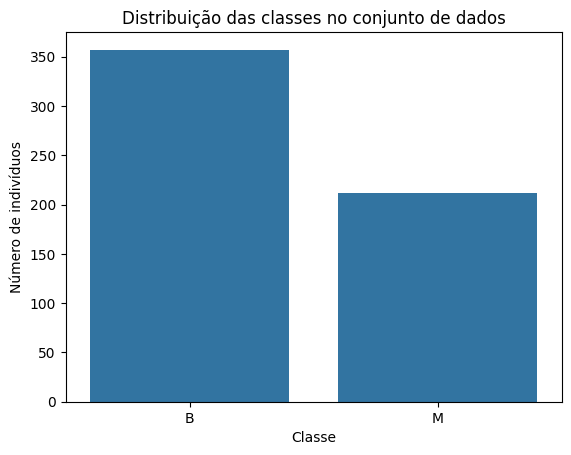

In [9]:
# gerando um gráfico de barras de comparação entre as classes
ax = sns.barplot(
    x=contagem_classes.index,
    y=contagem_classes.values
)

ax.set_xlabel("Classe")
ax.set_ylabel("Número de indivíduos")
ax.set_title("Distribuição das classes no conjunto de dados")

### Divisão em treino e teste e pré-processamento

In [10]:
SEMENTE_ALEATORIA = 94792

# separando 10% dos dados para testar o modelo
TAMANHO_TESTE = 0.1

# separando treino e teste a partir dos índices do DataFrame do dataset
indices = dados.index
indices_treino, indices_teste = train_test_split(indices, test_size=TAMANHO_TESTE, random_state=SEMENTE_ALEATORIA, stratify=dados['Diagnosis_num'])

# separando os dados de treino e teste a partir dos índices sorteados
dados_treino = dados.loc[indices_treino]
dados_teste = dados.loc[indices_teste]

In [11]:
# verificando os nomes das colunas do conjunto de dados
print(dados.columns)

Index(['radius1', 'texture1', 'perimeter1', 'area1', 'smoothness1',
       'compactness1', 'concavity1', 'concave_points1', 'symmetry1',
       'fractal_dimension1', 'radius2', 'texture2', 'perimeter2', 'area2',
       'smoothness2', 'compactness2', 'concavity2', 'concave_points2',
       'symmetry2', 'fractal_dimension2', 'radius3', 'texture3', 'perimeter3',
       'area3', 'smoothness3', 'compactness3', 'concavity3', 'concave_points3',
       'symmetry3', 'fractal_dimension3', 'Diagnosis', 'Diagnosis_num'],
      dtype='object')


In [12]:
ATRIBUTOS = ['radius1', 'texture1', 'perimeter1', 'area1', 'smoothness1', 'compactness1', 'concavity1', 'concave_points1', 
    'symmetry1', 'fractal_dimension1', 'radius2', 'texture2', 'perimeter2', 'area2',
    'smoothness2', 'compactness2', 'concavity2', 'concave_points2',
    'symmetry2', 'fractal_dimension2', 'radius3', 'texture3', 'perimeter3',
    'area3', 'smoothness3', 'compactness3', 'concavity3', 'concave_points3',
    'symmetry3', 'fractal_dimension3']

TARGET = ['Diagnosis_num']

In [13]:
# coletando atributos e targets dos dados de treino e teste
X_treino = dados_treino.reindex(ATRIBUTOS, axis=1)
y_treino = dados_treino.reindex(TARGET, axis=1).values.ravel()

X_teste = dados_teste.reindex(ATRIBUTOS, axis=1)
y_teste = dados_teste.reindex(TARGET, axis=1).values.ravel()

In [14]:
# visualizando os dados de treino
print("DataFrame com o conjunto de dados para treino do modelo")
dados_treino

DataFrame com o conjunto de dados para treino do modelo


,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,...,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3,Diagnosis,Diagnosis_num
278,13.590,17.84,86.24,572.3,0.07948,0.04052,0.01997,0.01238,0.1573,0.05520,...,98.91,739.1,0.1050,0.07622,0.10600,0.05185,0.2335,0.06263,B,0
239,17.460,39.28,113.40,920.6,0.09812,0.12980,0.14170,0.08811,0.1809,0.05966,...,141.20,1408.0,0.1365,0.37350,0.32410,0.20660,0.2853,0.08496,M,1
135,12.770,22.47,81.72,506.3,0.09055,0.05761,0.04711,0.02704,0.1585,0.06065,...,92.04,653.6,0.1419,0.15230,0.21770,0.09331,0.2829,0.08067,M,1
113,10.510,20.19,68.64,334.2,0.11220,0.13030,0.06476,0.03068,0.1922,0.07782,...,72.62,374.4,0.1300,0.20490,0.12950,0.06136,0.2383,0.09026,B,0
238,14.220,27.85,92.55,623.9,0.08223,0.10390,0.11030,0.04408,0.1342,0.06129,...,102.50,764.0,0.1081,0.24260,0.30640,0.08219,0.1890,0.07796,B,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
214,14.190,23.81,92.87,610.7,0.09463,0.13060,0.11150,0.06462,0.2235,0.06433,...,115.00,811.3,0.1559,0.40590,0.37440,0.17720,0.4724,0.10260,M,1
68,9.029,17.33,58.79,250.5,0.10660,0.14130,0.31300,0.04375,0.2111,0.08046,...,65.50,324.7,0.1482,0.43650,1.25200,0.17500,0.4228,0.11750,B,0
390,10.260,12.22,65.75,321.6,0.09996,0.07542,0.01923,0.01968,0.1800,0.06569,...,73.23,394.5,0.1343,0.16500,0.08615,0.06696,0.2937,0.07722,B,0
490,12.250,22.44,78.18,466.5,0.08192,0.05200,0.01714,0.01261,0.1544,0.05976,...,92.74,622.9,0.1256,0.18040,0.12300,0.06335,0.3100,0.08203,B,0


In [15]:
# visualizando os dados de teste
print("DataFrame com o conjunto de dados para teste do modelo")
dados_teste

DataFrame com o conjunto de dados para teste do modelo


,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,...,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3,Diagnosis,Diagnosis_num
333,11.250,14.78,71.38,390.0,0.08306,0.04458,0.000974,0.002941,0.1773,0.06081,...,82.08,492.7,0.11660,0.09794,0.005518,0.01667,0.2815,0.07418,B,0
103,9.876,19.40,63.95,298.3,0.10050,0.09697,0.061540,0.030290,0.1945,0.06322,...,72.22,361.2,0.15590,0.23020,0.264400,0.09749,0.2622,0.08490,B,0
419,11.160,21.41,70.95,380.3,0.10180,0.05978,0.008955,0.010760,0.1615,0.06144,...,79.26,458.0,0.12820,0.11080,0.035820,0.04306,0.2976,0.07123,B,0
146,11.800,16.58,78.99,432.0,0.10910,0.17000,0.165900,0.074150,0.2678,0.07371,...,91.93,591.7,0.13850,0.40920,0.450400,0.18650,0.5774,0.10300,M,1
270,14.290,16.82,90.30,632.6,0.06429,0.02675,0.007250,0.006250,0.1508,0.05376,...,94.44,684.6,0.08567,0.05036,0.038660,0.03333,0.2458,0.06120,B,0
347,14.760,14.74,94.87,668.7,0.08875,0.07780,0.046080,0.035280,0.1521,0.05912,...,114.20,880.8,0.12200,0.20090,0.215100,0.12510,0.3109,0.08187,B,0
447,14.800,17.66,95.88,674.8,0.09179,0.08890,0.040690,0.022600,0.1893,0.05886,...,105.90,829.5,0.12260,0.18810,0.206000,0.08308,0.3600,0.07285,B,0
443,10.570,18.32,66.82,340.9,0.08142,0.04462,0.019930,0.011110,0.2372,0.05768,...,69.35,366.3,0.09794,0.06542,0.039860,0.02222,0.2699,0.06736,B,0
417,15.500,21.08,102.90,803.1,0.11200,0.15710,0.152200,0.084810,0.2085,0.06864,...,157.10,1748.0,0.15170,0.40020,0.421100,0.21340,0.3003,0.10480,M,1
513,14.580,13.66,94.29,658.8,0.09832,0.08918,0.082220,0.043490,0.1739,0.05640,...,108.50,862.0,0.12230,0.19280,0.249200,0.09186,0.2626,0.07048,B,0


#### Proporção entre as classes de 'Targets'

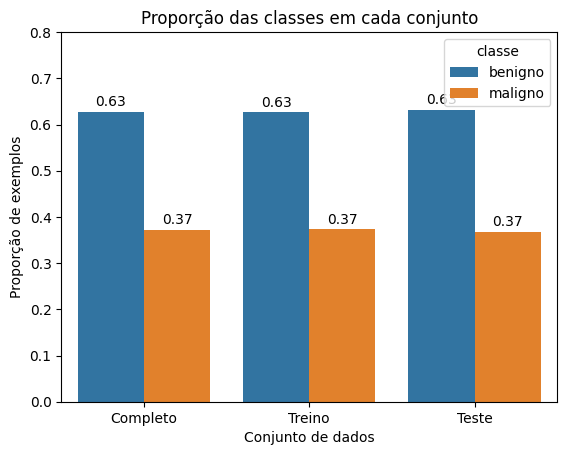

In [16]:
NOMES_CLASSES = {"B": "benigno", "M": "maligno"}

# verificando as proporções das classes em cada divisão
proporcoes = pd.DataFrame({"Completo": dados["Diagnosis"].value_counts(normalize=True),
    "Treino": dados_treino["Diagnosis"].value_counts(normalize=True),
    "Teste": dados_teste["Diagnosis"].value_counts(normalize=True),
    }).rename(index=NOMES_CLASSES)

df_prop = (
    proporcoes.reset_index(names="classe")
    .melt(id_vars="classe", var_name="conjunto", value_name="proporção")
)

# plotando o gráfico de comparação
eixo = sns.barplot(df_prop, x="conjunto", y="proporção", hue="classe")

# adicionando a porcentagem sobre os eixos
for porcentagens in eixo.containers:
    eixo.bar_label(porcentagens, fmt="%.2f", padding=2)

eixo.set(
    xlabel="Conjunto de dados",
    ylabel="Proporção de exemplos",
    title="Proporção das classes em cada conjunto",
    ylim=(0, 0.8)
);

#### Distribuição de 'Targets' entre os Atributos

In [17]:
# verificando o quanto de cada classe existe em cada atributo e sua distribuição
dados_targets = dados_treino.copy()
dados_targets["classe"] = dados_targets["Diagnosis"].map(NOMES_CLASSES)

ATRIBUTOS_MEDIA = [a for a in ATRIBUTOS if a.endswith("1")]

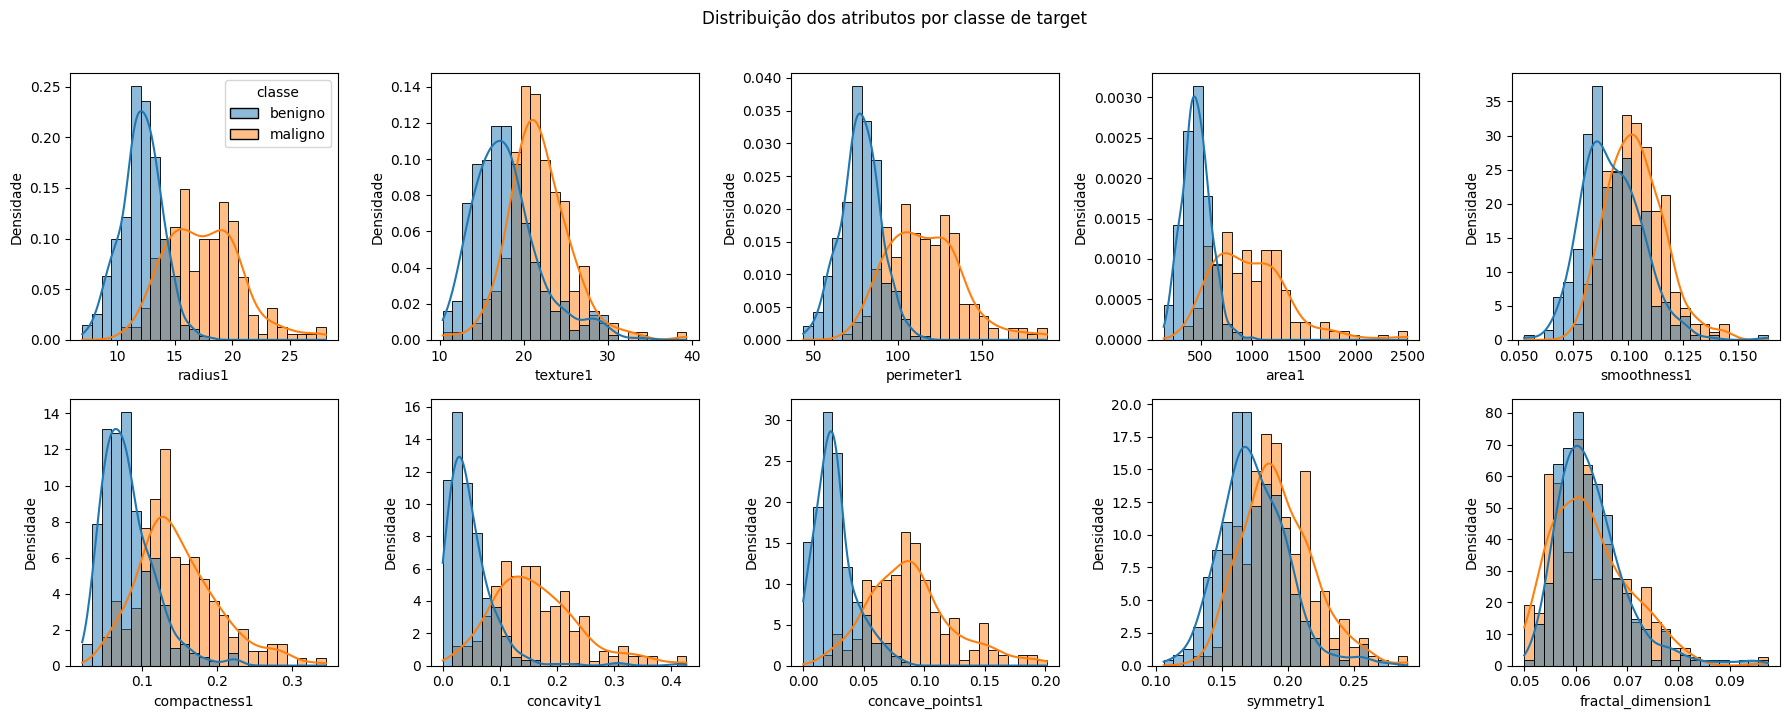

In [18]:
# plotando os gráficos de cada atributo lado a lado
fig, eixos = plt.subplots(2, 5, figsize=(18, 7))

for eixo, atributo in zip(eixos.ravel(), ATRIBUTOS_MEDIA):
    sns.histplot(
        dados_targets, x=atributo, hue="classe", stat="density", common_norm=False,
        kde=True, bins=25, ax=eixo, legend=(atributo == ATRIBUTOS_MEDIA[0]),
    )
    eixo.set(xlabel=atributo, ylabel="Densidade")

fig.suptitle("Distribuição dos atributos por classe de target", y=1.02)
fig.tight_layout();

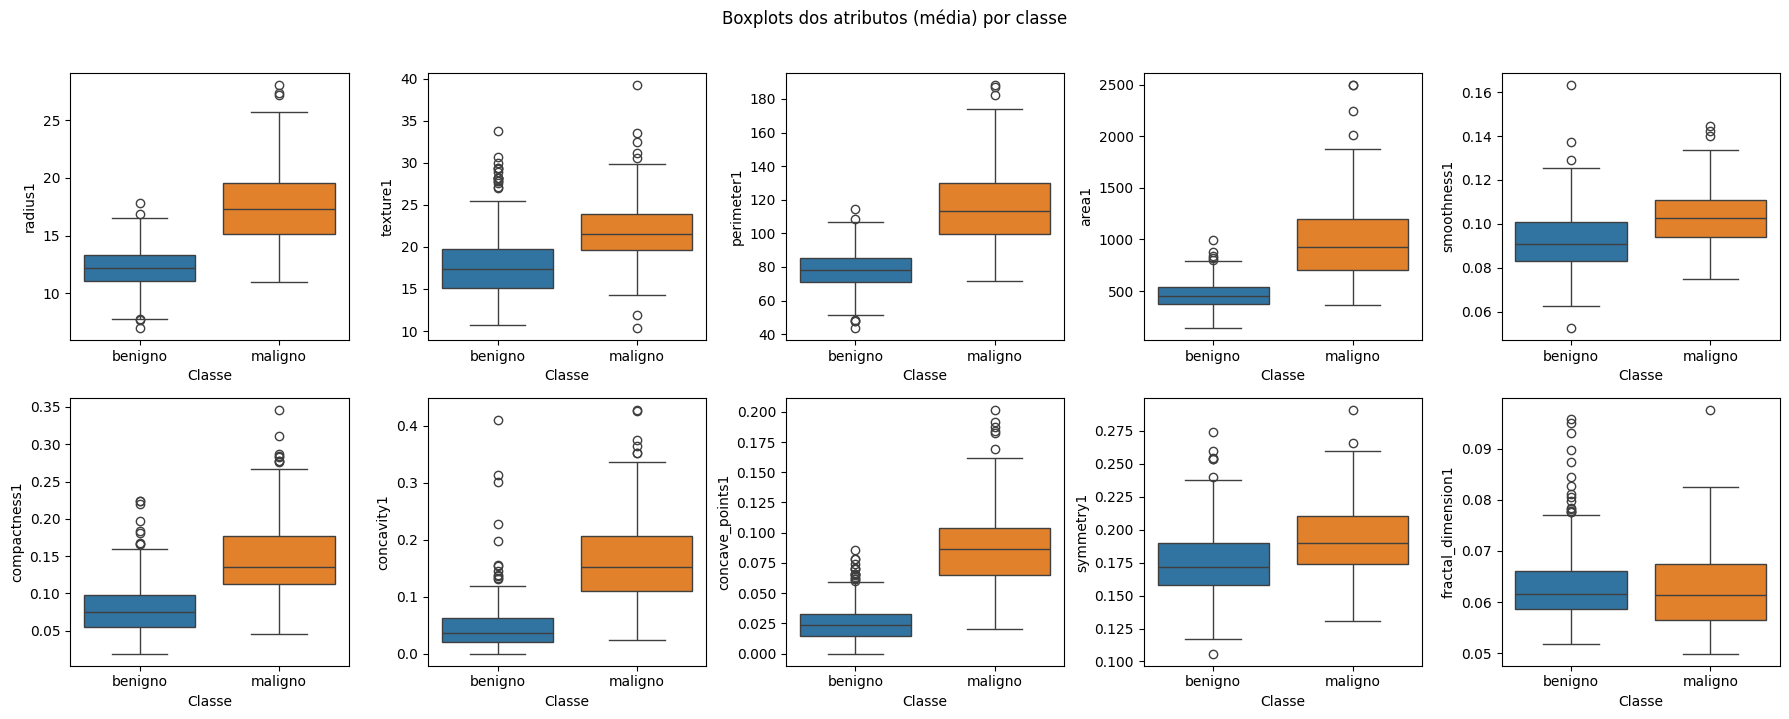

In [19]:
# plotando bloxplots para cada atributo
fig, eixos = plt.subplots(2, 5, figsize=(18, 7))

for eixo, atributo in zip(eixos.ravel(), ATRIBUTOS_MEDIA):
    sns.boxplot(
        dados_targets, x="classe", y=atributo, hue="classe",
        order=["benigno", "maligno"], hue_order=["benigno", "maligno"],
        legend=False, ax=eixo,
    )
    eixo.set(xlabel="Classe", ylabel=atributo)

fig.suptitle("Boxplots dos atributos (média) por classe", y=1.02)
fig.tight_layout();

#### O poder de separação de cada atributo isoladamente

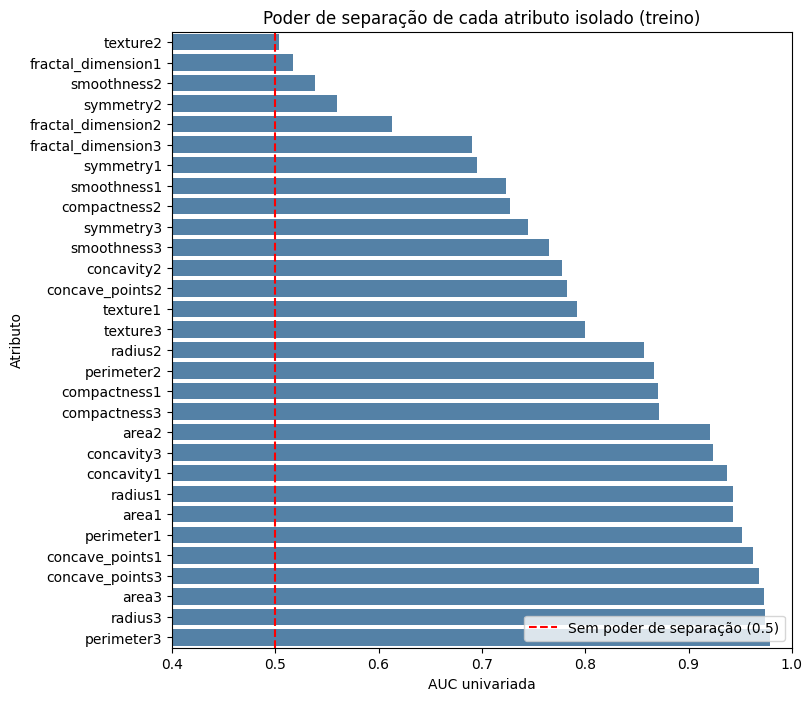

In [20]:
# AUC de cada atributo isolado
auc_univariada = pd.Series(
    {atributo: roc_auc_score(y_treino, X_treino[atributo]) for atributo in ATRIBUTOS}
)

# =considerando a informação de um atributo que classifica a classe contrária
auc_univariada = auc_univariada.apply(lambda v: max(v, 1 - v)).sort_values()

# plotando o gráfico de barras
fig, eixo = plt.subplots(figsize=(8, 8))
sns.barplot(x=auc_univariada.values, y=auc_univariada.index, ax=eixo, color="steelblue")
eixo.axvline(0.5, color="red", linestyle="--", label="Sem poder de separação (0.5)")
eixo.set(
    xlim=(0.4, 1),
    xlabel="AUC univariada",
    ylabel="Atributo",
    title="Poder de separação de cada atributo isolado (treino)",
)
eixo.legend(loc="lower right");

#### Relação entre os pares de atributos de maior correlação

In [21]:
# Calculando a correlação entre os atributos e o target
correlacao_target = (dados_treino[ATRIBUTOS + TARGET].corr()["Diagnosis_num"].drop("Diagnosis_num").abs().sort_values(ascending=False))
correlacao_target

concave_points3       0.795231
perimeter3            0.784531
radius3               0.778085
concave_points1       0.772685
perimeter1            0.746447
area3                 0.734148
radius1               0.733968
area1                 0.710041
concavity1            0.694095
concavity3            0.664819
compactness1          0.605255
compactness3          0.604340
radius2               0.548767
perimeter2            0.538422
area2                 0.532355
texture3              0.477772
texture1              0.436044
smoothness3           0.435835
symmetry3             0.426378
concave_points2       0.389724
smoothness1           0.359971
fractal_dimension3    0.327703
symmetry1             0.325345
compactness2          0.288076
concavity2            0.242393
smoothness2           0.073049
fractal_dimension2    0.064920
symmetry2             0.023931
texture2              0.021538
fractal_dimension1    0.015683
Name: Diagnosis_num, dtype: float64

Text(0.5, 1.0, 'Correlação entre os atributos (treino)')

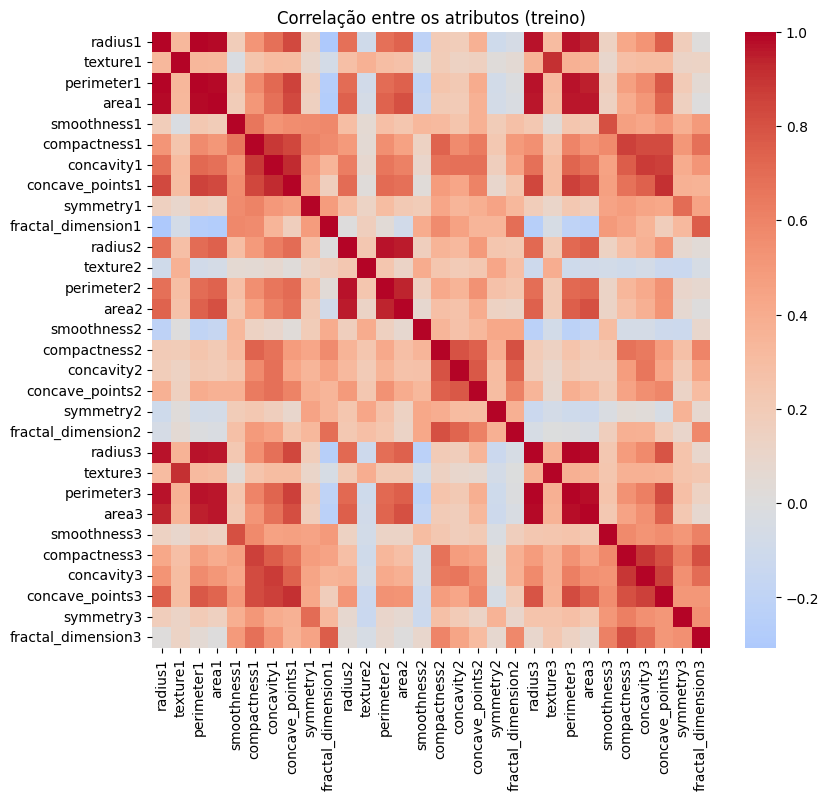

In [22]:
# gerando um heatmap com as correlações entre os atributos e o target
plt.figure(figsize=(9, 8))
sns.heatmap(dados_treino[ATRIBUTOS].corr(), cmap="coolwarm", center=0)
plt.title("Correlação entre os atributos (treino)")

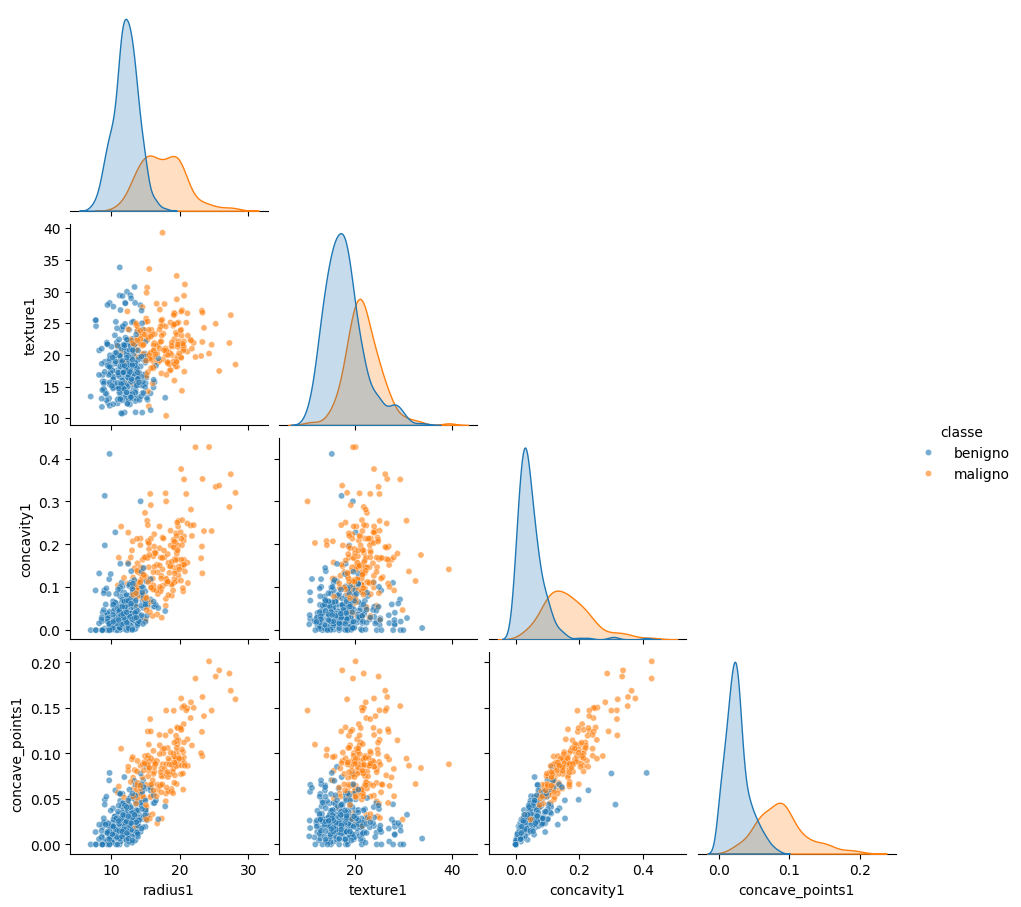

In [23]:
# avaliando como os dados se distribuem com base em 2 atributos
sns.pairplot(
    dados_targets, vars=["radius1", "texture1", "concavity1", "concave_points1"],
    hue="classe", corner=True, plot_kws={"alpha": 0.6, "s": 20}, height=2.3,
);

### Definindo as métricas e estratégias de validação

In [24]:
# métricas de desempenho
METRICAS = {
    "acuracia": "accuracy",
    "precisao": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
    "f2": make_scorer(fbeta_score, beta=2, zero_division=0),
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
}

NOMES_METRICAS = {
    "acuracia": "Acurácia",
    "precisao": "Precisão",
    "recall": "Recall",
    "f1": "F1",
    "f2": "F2",
    "roc_auc": "ROC-AUC",
    "pr_auc": "PR-AUC",
}

# normalizadores utilizados
NORMALIZADORES = {
    "sem normalizador": None,
    "normalizador padrão": StandardScaler,
    "máximo absoluto": MaxAbsScaler,
    "máximo e mínimo": MinMaxScaler,
}

# quantidade de folds para a validação cruzada
NUM_FOLDS = 10

# validação cruzada estratificada e embaralhada, com semente fixa
cv_estratificado = StratifiedKFold(n_splits=NUM_FOLDS, shuffle=True, random_state=SEMENTE_ALEATORIA)

# validação cruzada repetida, usada na comparação final de cada modelo (outra semente para não reaproveitar as partições)
cv_comparacao = RepeatedStratifiedKFold(n_splits=NUM_FOLDS, n_repeats=3, random_state=SEMENTE_ALEATORIA + 1)


#### Verificando a escala dos atributos

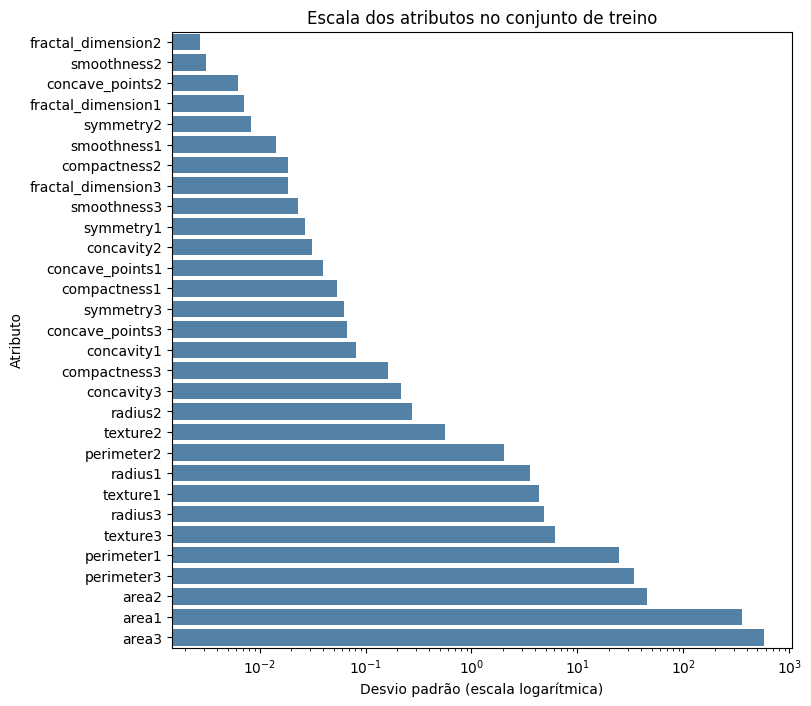

In [25]:
# desvio padrão de cada atributo, em escala logarítmica
desvios = X_treino.std().sort_values()

fig, eixo = plt.subplots(figsize=(8, 8))
sns.barplot(x=desvios.values, y=desvios.index, ax=eixo, color="steelblue")
eixo.set(
    xscale="log",
    xlabel="Desvio padrão (escala logarítmica)",
    ylabel="Atributo",
    title="Escala dos atributos no conjunto de treino",
);

### Modelo Baseline

In [26]:
# instanciando o modelo Baseline
modelo_baseline = DummyClassifier(strategy='prior')

# treinando o modelo
modelo_baseline.fit(X_treino, y_treino)

# obtendo o melhor modelo a partir do método de validação cruzada
resultados_baseline = cross_validate(modelo_baseline, X_treino, y_treino, cv=cv_estratificado, scoring=METRICAS)

In [27]:
# avaliando as métricas de desempenho obtidas para o modelo Baseline
metricas_baseline = (
    pd.DataFrame({k.replace("test_", ""): v for k, v in resultados_baseline.items() if k.startswith("test_")})
    .agg(["mean", "std"])
    .T.rename(index=NOMES_METRICAS)
)

metricas_baseline

,mean,std
Acurácia,0.626961,0.004649
Precisão,0.000000,0.000000
Recall,0.000000,0.000000
F1,0.000000,0.000000
F2,0.000000,0.000000
ROC-AUC,0.500000,0.000000
PR-AUC,0.373039,0.004649


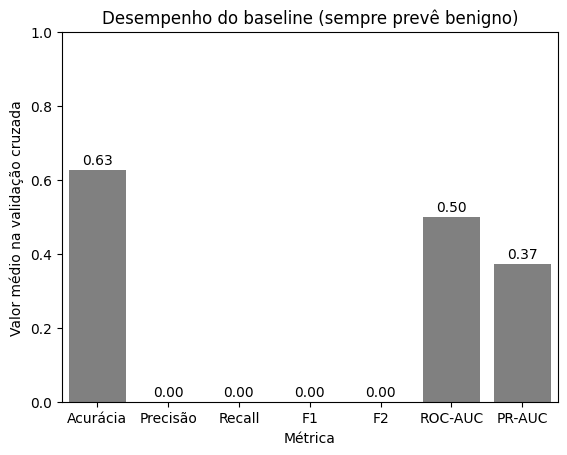

In [28]:
# gerando um gráfico com as métricas de desempenho do modelo baseline
medias_baseline = metricas_baseline["mean"]

eixo = sns.barplot(x=medias_baseline.index, y=medias_baseline.values, color="gray")

for container in eixo.containers:
    eixo.bar_label(container, fmt="%.2f", padding=2)

eixo.set(
    xlabel="Métrica",
    ylabel="Valor médio na validação cruzada",
    title="Desempenho do baseline (sempre prevê benigno)",
    ylim=(0, 1),
);

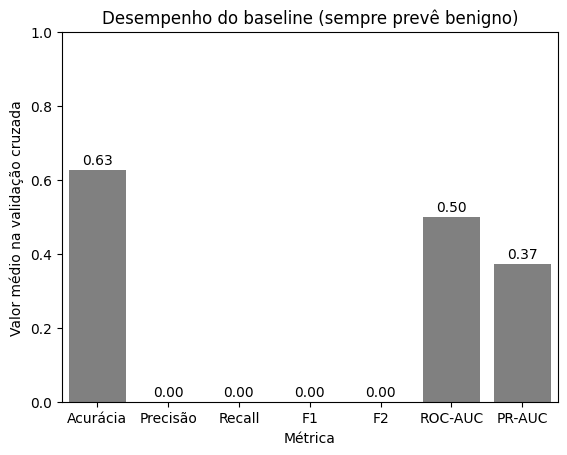

In [29]:
# avaliando o valor médio de cada métrica na validação cruzada
medias_baseline = metricas_baseline["mean"]

eixo = sns.barplot(x=medias_baseline.index, y=medias_baseline.values, color="gray")

for container in eixo.containers:
    eixo.bar_label(container, fmt="%.2f", padding=2)

eixo.set(
    xlabel="Métrica",
    ylabel="Valor médio na validação cruzada",
    title="Desempenho do baseline (sempre prevê benigno)",
    ylim=(0, 1),
);

### Modelo K-NN

#### K-NN sem normalizador

In [30]:
# definindo a ordem das colunas para a matriz de confusão
ordem_labels = [0, 1]

In [31]:
# definindo o número inicial de vizinhos avaliados
NUM_VIZINHOS = 21

# instanciando um pipeline para o modelo KNN sem normalização
pipeline_knn_sem_norm = make_pipeline(KNeighborsClassifier(n_neighbors=NUM_VIZINHOS))

# treinando o modelo
pipeline_knn_sem_norm.fit(X_treino, y_treino)

X_verdadeiro = X_treino
y_verdadeiro = y_treino

# realizando a validação cruzada estratificada
y_previsto_knn_sem_norm = cross_val_predict(pipeline_knn_sem_norm, X_verdadeiro, y_verdadeiro, cv=cv_estratificado)

[Text(0, 0.5, 'Benigno'), Text(0, 1.5, 'Maligno')]

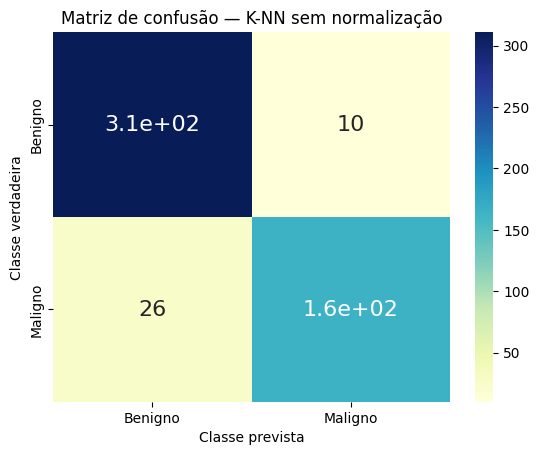

In [32]:
# plotando a matriz de confusão
matriz_conf = confusion_matrix(y_verdadeiro, y_previsto_knn_sem_norm, labels=ordem_labels)
df_conf = pd.DataFrame(matriz_conf, ordem_labels, ordem_labels)

matriz_conf_baseline_sem_norm = sns.heatmap(df_conf, annot=True, annot_kws={"size": 16}, cmap="YlGnBu");

matriz_conf_baseline_sem_norm.set_xlabel("Classe prevista")
matriz_conf_baseline_sem_norm.set_ylabel("Classe verdadeira")
matriz_conf_baseline_sem_norm.set_title("Matriz de confusão — K-NN sem normalização")

matriz_conf_baseline_sem_norm.set_xticklabels(["Benigno", "Maligno"])
matriz_conf_baseline_sem_norm.set_yticklabels(["Benigno", "Maligno"])

In [33]:
# verificando algumas das melhores métricas de desempenho obtidas
acuracia_knn_sem_norm = accuracy_score(y_verdadeiro, y_previsto_knn_sem_norm)
f1_knn_sem_norm = f1_score(y_verdadeiro, y_previsto_knn_sem_norm)
f2_knn_sem_norm = fbeta_score(y_verdadeiro, y_previsto_knn_sem_norm, beta=2, zero_division=0)

print(f"Acurácia = {(acuracia_knn_sem_norm*100):.2f}%")
print(f"F1_score = {f1_knn_sem_norm*100:.2f}%")
print(f"F2_score = {f2_knn_sem_norm*100:.2f}%")

Acurácia = 92.97%
F1_score = 90.16%
F2_score = 87.86%


In [34]:
# verificando as médias e desvios padrões das métricas de desemepnho obtidas durante a validação cruzada
resultados_knn_sem_norm = cross_validate(pipeline_knn_sem_norm, X_treino, y_treino, cv=NUM_FOLDS, scoring=METRICAS)

metricas_knn_sem_norm = (
    pd.DataFrame({k.replace("test_", ""): v for k, v in resultados_knn_sem_norm.items() if k.startswith("test_")})
    .agg(["mean", "std"])
    .T.rename(index=NOMES_METRICAS)
)

metricas_knn_sem_norm

,mean,std
Acurácia,0.931787,0.033104
Precisão,0.949878,0.040100
Recall,0.864211,0.085725
F1,0.902642,0.050139
F2,0.878683,0.071211
ROC-AUC,0.975982,0.018576
PR-AUC,0.961654,0.025619


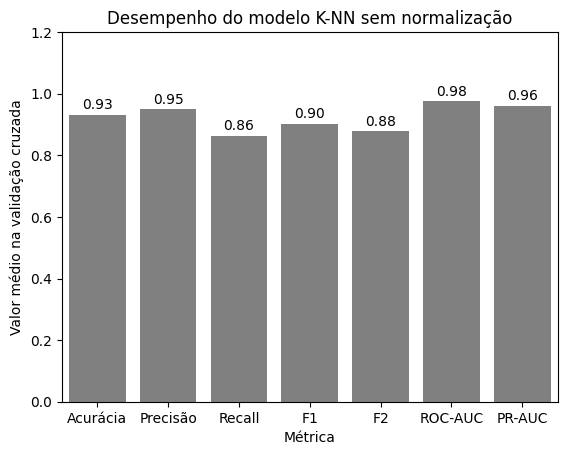

In [35]:
# plotando um gráfico de barras com as médias obtidas para as métricas de desempenho
medias_knn_sem_norm = metricas_knn_sem_norm["mean"]

eixo = sns.barplot(x=medias_knn_sem_norm.index, y=medias_knn_sem_norm.values, color="gray")

for container in eixo.containers:
    eixo.bar_label(container, fmt="%.2f", padding=2)

eixo.set(
    xlabel="Métrica",
    ylabel="Valor médio na validação cruzada",
    title="Desempenho do modelo K-NN sem normalização",
    ylim=(0, 1.2),
);

#### K-NN com normalizador padrão

In [36]:
# instanciando o modelo em um pipeline
pipeline_knn_norm_pad = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=NUM_VIZINHOS))

# treinando o modelo
pipeline_knn_norm_pad.fit(X_treino, y_treino)

X_verdadeiro = X_treino
y_verdadeiro = y_treino

# realizando a validação cruzada estratificada
y_previsto_knn_norm_pad = cross_val_predict(pipeline_knn_norm_pad, X_verdadeiro, y_verdadeiro, cv=cv_estratificado)

[Text(0, 0.5, 'Benigno'), Text(0, 1.5, 'Maligno')]

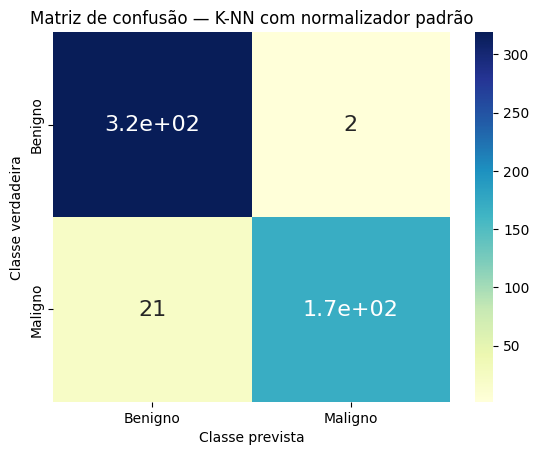

In [37]:
# plotando a matriz de confusão
matriz_conf = confusion_matrix(y_verdadeiro, y_previsto_knn_norm_pad, labels=ordem_labels)
df_conf = pd.DataFrame(matriz_conf, ordem_labels, ordem_labels)

matriz_conf_baseline_norm_pad = sns.heatmap(df_conf, annot=True, annot_kws={"size": 16}, cmap="YlGnBu");

matriz_conf_baseline_norm_pad.set_xlabel("Classe prevista")
matriz_conf_baseline_norm_pad.set_ylabel("Classe verdadeira")
matriz_conf_baseline_norm_pad.set_title("Matriz de confusão — K-NN com normalizador padrão")

matriz_conf_baseline_norm_pad.set_xticklabels(["Benigno", "Maligno"])
matriz_conf_baseline_norm_pad.set_yticklabels(["Benigno", "Maligno"])

In [38]:
# verificando as melhores métricas de desempenho obtidas
acuracia_knn_norm_pad = accuracy_score(y_verdadeiro, y_previsto_knn_norm_pad)
f1_knn_norm_pad = f1_score(y_verdadeiro, y_previsto_knn_norm_pad)
f2_knn_norm_pad = fbeta_score(y_verdadeiro, y_previsto_knn_norm_pad, beta=2, zero_division=0)

print(f"Acurácia = {(acuracia_knn_norm_pad*100):.2f}%")
print(f"F1_score = {f1_knn_norm_pad*100:.2f}%")
print(f"F2_score = {f2_knn_norm_pad*100:.2f}%")

Acurácia = 95.51%
F1_score = 93.66%
F2_score = 90.81%


In [39]:
# verificando as médias das métricas de desempenho obtidas durante a validação cruzada
resultados_knn_norm_pad = cross_validate(pipeline_knn_norm_pad, X_treino, y_treino, cv=NUM_FOLDS, scoring=METRICAS)

metricas_knn_norm_pad = (
    pd.DataFrame({k.replace("test_", ""): v for k, v in resultados_knn_norm_pad.items() if k.startswith("test_")})
    .agg(["mean", "std"])
    .T.rename(index=NOMES_METRICAS)
)

metricas_knn_norm_pad

,mean,std
Acurácia,0.962896,0.035082
Precisão,0.993333,0.021082
Recall,0.905526,0.081692
F1,0.946129,0.052817
F2,0.921081,0.070751
ROC-AUC,0.992888,0.009008
PR-AUC,0.988386,0.014252


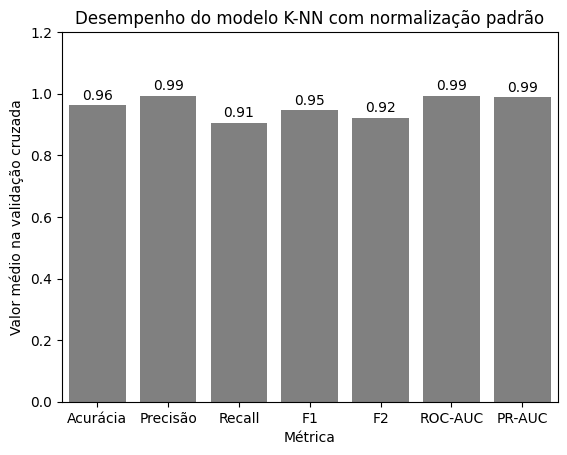

In [40]:
# plotando um gráfico de barras com as médias das métricas de desempenho
medias_knn_norm_pad = metricas_knn_norm_pad["mean"]

eixo = sns.barplot(x=medias_knn_norm_pad.index, y=medias_knn_norm_pad.values, color="gray")

for container in eixo.containers:
    eixo.bar_label(container, fmt="%.2f", padding=2)

eixo.set(
    xlabel="Métrica",
    ylabel="Valor médio na validação cruzada",
    title="Desempenho do modelo K-NN com normalização padrão",
    ylim=(0, 1.2),
);

#### K-NN com normalizador pelo máximo absoluto

In [41]:
# instanciando o modelo em um pipeline
pipeline_knn_norm_max = make_pipeline(MaxAbsScaler(), KNeighborsClassifier(n_neighbors=NUM_VIZINHOS))

# treinando o modelo
pipeline_knn_norm_max.fit(X_treino, y_treino)

X_verdadeiro = X_treino
y_verdadeiro = y_treino

# realizando a validação cruzada estratificada
y_previsto_knn_norm_max = cross_val_predict(pipeline_knn_norm_max, X_verdadeiro, y_verdadeiro, cv=cv_estratificado)

[Text(0, 0.5, 'Benigno'), Text(0, 1.5, 'Maligno')]

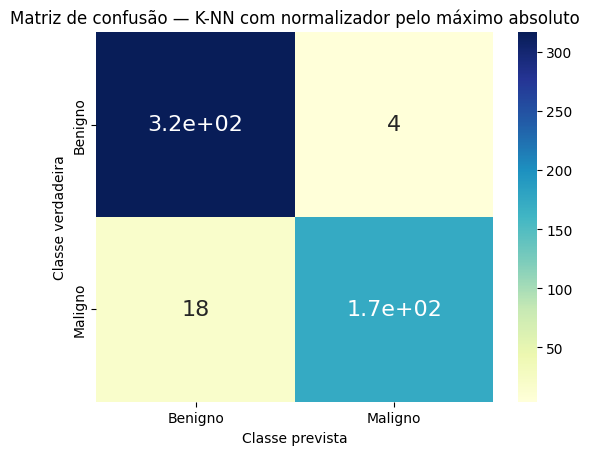

In [42]:
# plotando a matriz de confusão
matriz_conf = confusion_matrix(y_verdadeiro, y_previsto_knn_norm_max, labels=ordem_labels)
df_conf = pd.DataFrame(matriz_conf, ordem_labels, ordem_labels)

matriz_conf_baseline_norm_max = sns.heatmap(df_conf, annot=True, annot_kws={"size": 16}, cmap="YlGnBu");

matriz_conf_baseline_norm_max.set_xlabel("Classe prevista")
matriz_conf_baseline_norm_max.set_ylabel("Classe verdadeira")
matriz_conf_baseline_norm_max.set_title("Matriz de confusão — K-NN com normalizador pelo máximo absoluto")

matriz_conf_baseline_norm_max.set_xticklabels(["Benigno", "Maligno"])
matriz_conf_baseline_norm_max.set_yticklabels(["Benigno", "Maligno"])

In [43]:
# verificando algumas das melhores métricas de desempenho obtidas
acuracia_knn_norm_max = accuracy_score(y_verdadeiro, y_previsto_knn_norm_max)
f1_knn_norm_max = f1_score(y_verdadeiro, y_previsto_knn_norm_max)
f2_knn_norm_max = fbeta_score(y_verdadeiro, y_previsto_knn_norm_max, beta=2, zero_division=0)

print(f"Acurácia = {(acuracia_knn_norm_max*100):.2f}%")
print(f"F1_score = {f1_knn_norm_max*100:.2f}%")
print(f"F2_score = {f2_knn_norm_max*100:.2f}%")

Acurácia = 95.70%
F1_score = 94.02%
F2_score = 91.92%


In [44]:
# verificando as médias e desvios padrões das métricas obtidas durante a validação cruzada
resultados_knn_norm_max = cross_validate(pipeline_knn_norm_max, X_treino, y_treino, cv=NUM_FOLDS, scoring=METRICAS)

metricas_knn_norm_max = (
    pd.DataFrame({k.replace("test_", ""): v for k, v in resultados_knn_norm_max.items() if k.startswith("test_")})
    .agg(["mean", "std"])
    .T.rename(index=NOMES_METRICAS)
)

metricas_knn_norm_max

,mean,std
Acurácia,0.955128,0.033291
Precisão,0.977251,0.029620
Recall,0.900526,0.076248
F1,0.936038,0.049864
F2,0.914142,0.065995
ROC-AUC,0.992887,0.009366
PR-AUC,0.987779,0.015067


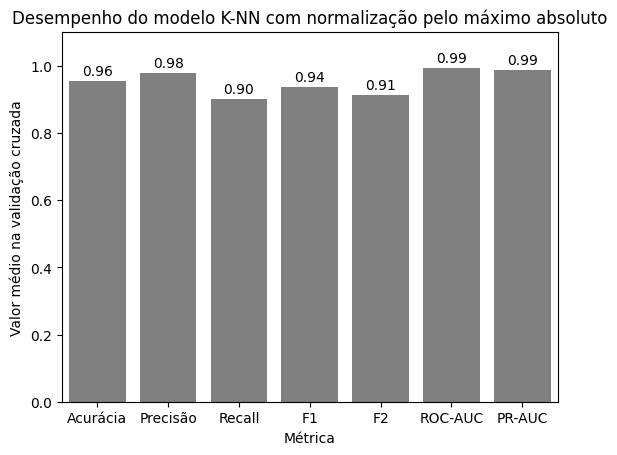

In [45]:
# plotando um gráfico de barras com a média das métricas de desempenho
medias_knn_norm_max = metricas_knn_norm_max["mean"]

eixo = sns.barplot(x=medias_knn_norm_max.index, y=medias_knn_norm_max.values, color="gray")

for container in eixo.containers:
    eixo.bar_label(container, fmt="%.2f", padding=2)

eixo.set(
    xlabel="Métrica",
    ylabel="Valor médio na validação cruzada",
    title="Desempenho do modelo K-NN com normalização pelo máximo absoluto",
    ylim=(0, 1.1),
);

#### K-NN com normalizador pelo máximo e mínimo

In [46]:
# instanciando o modelo em um pipeline
pipeline_knn_norm_min_max = make_pipeline(MinMaxScaler(), KNeighborsClassifier(n_neighbors=NUM_VIZINHOS))

# treinando o modelo
pipeline_knn_norm_min_max.fit(X_treino, y_treino)

X_verdadeiro = X_treino
y_verdadeiro = y_treino

# realizando a validação cruzada estratificada
y_previsto_knn_norm_min_max = cross_val_predict(pipeline_knn_norm_min_max, X_verdadeiro, y_verdadeiro, cv=cv_estratificado)

[Text(0, 0.5, 'Benigno'), Text(0, 1.5, 'Maligno')]

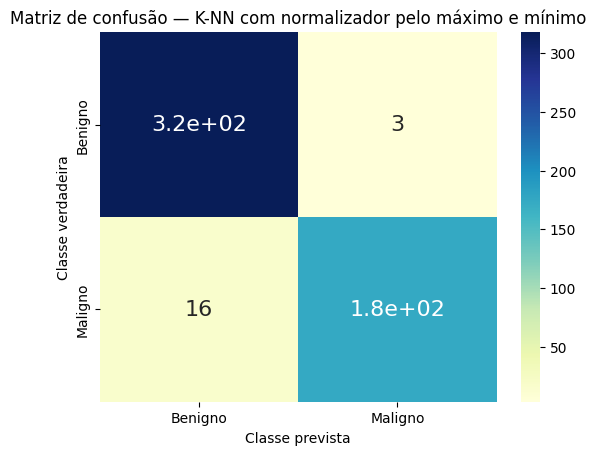

In [47]:
# plotando a matriz de confusão
matriz_conf = confusion_matrix(y_verdadeiro, y_previsto_knn_norm_min_max, labels=ordem_labels)
df_conf = pd.DataFrame(matriz_conf, ordem_labels, ordem_labels)

matriz_conf_baseline_norm_min_max = sns.heatmap(df_conf, annot=True, annot_kws={"size": 16}, cmap="YlGnBu");

matriz_conf_baseline_norm_min_max.set_xlabel("Classe prevista")
matriz_conf_baseline_norm_min_max.set_ylabel("Classe verdadeira")
matriz_conf_baseline_norm_min_max.set_title("Matriz de confusão — K-NN com normalizador pelo máximo e mínimo")

matriz_conf_baseline_norm_min_max.set_xticklabels(["Benigno", "Maligno"])
matriz_conf_baseline_norm_min_max.set_yticklabels(["Benigno", "Maligno"])

In [48]:
# verificando as melhores métricas de desemepnho obtidas
acuracia_knn_norm_min_max = accuracy_score(y_verdadeiro, y_previsto_knn_norm_min_max)
f1_knn_norm_min_max = f1_score(y_verdadeiro, y_previsto_knn_norm_min_max)
f2_knn_norm_min_max = fbeta_score(y_verdadeiro, y_previsto_knn_norm_min_max, beta=2, zero_division=0)

print(f"Acurácia = {(acuracia_knn_norm_min_max*100):.2f}%")
print(f"F1_score = {f1_knn_norm_min_max*100:.2f}%")
print(f"F2_score = {f2_knn_norm_min_max*100:.2f}%")

Acurácia = 96.29%
F1_score = 94.85%
F2_score = 92.89%


In [49]:
# verificando as médias e desvios padrões das métricas de desempenho obtidas durante a validação cruzada
resultados_knn_norm_min_max = cross_validate(pipeline_knn_norm_min_max, X_treino, y_treino, cv=NUM_FOLDS, scoring=METRICAS)

metricas_knn_norm_min_max = (
    pd.DataFrame({k.replace("test_", ""): v for k, v in resultados_knn_norm_min_max.items() if k.startswith("test_")})
    .agg(["mean", "std"])
    .T.rename(index=NOMES_METRICAS)
)

metricas_knn_norm_min_max

,mean,std
Acurácia,0.962896,0.036279
Precisão,0.983016,0.027716
Recall,0.915789,0.086660
F1,0.946555,0.054398
F2,0.927506,0.074105
ROC-AUC,0.993455,0.010191
PR-AUC,0.988856,0.017517


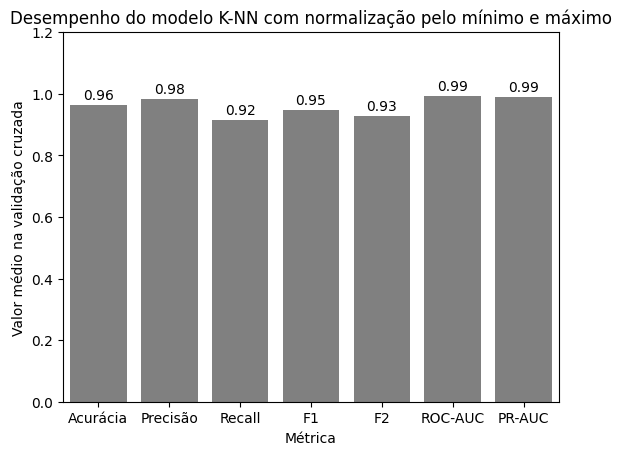

In [50]:
# plotando um gráfico de barras com as médias das métricas de desemepnho 
medias_knn_norm_min_max = metricas_knn_norm_min_max["mean"]

eixo = sns.barplot(x=medias_knn_norm_min_max.index, y=medias_knn_norm_min_max.values, color="gray")

for container in eixo.containers:
    eixo.bar_label(container, fmt="%.2f", padding=2)

eixo.set(
    xlabel="Métrica",
    ylabel="Valor médio na validação cruzada",
    title="Desempenho do modelo K-NN com normalização pelo mínimo e máximo",
    ylim=(0, 1.2),
);

#### Comparando os diferentes modelos de K-NN construídos

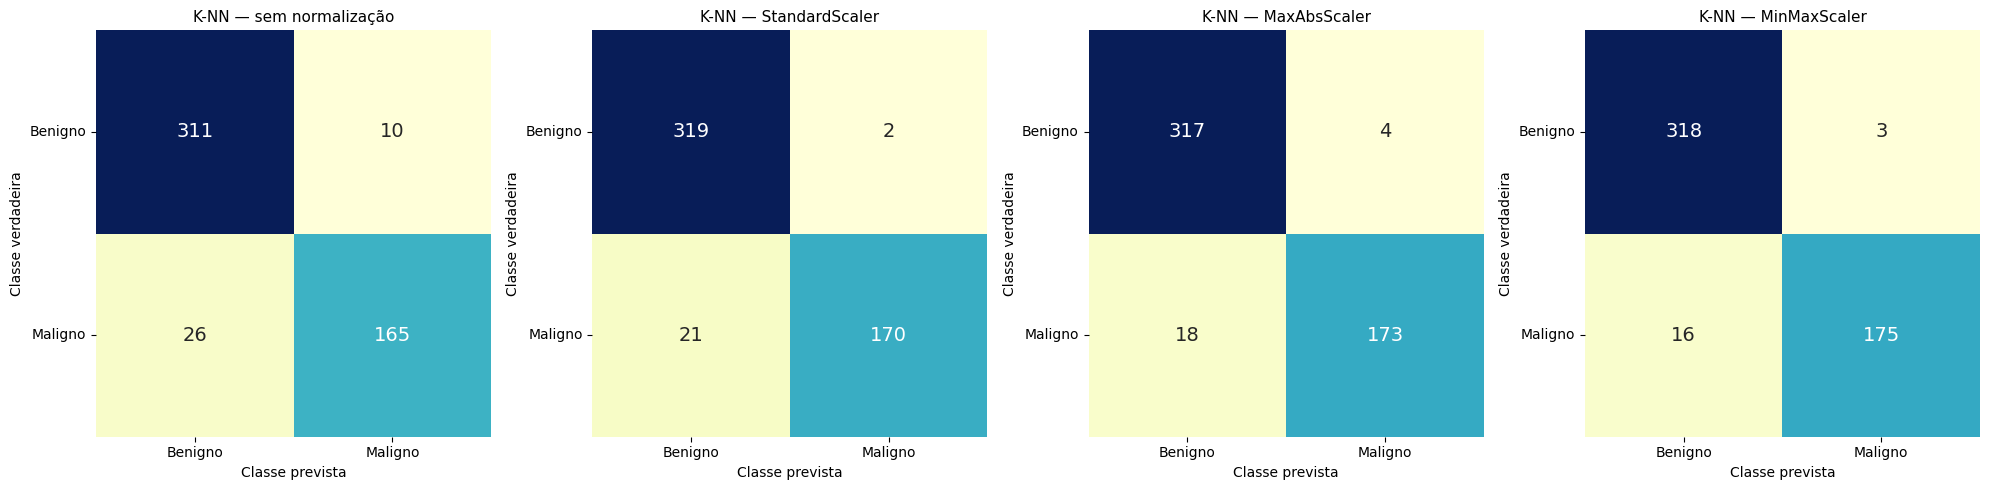

In [51]:
# quatro modelos knn's a serem comparados
modelos_knn = [
    ("K-NN — sem normalização", y_verdadeiro, y_previsto_knn_sem_norm),
    ("K-NN — StandardScaler", y_verdadeiro, y_previsto_knn_norm_pad),
    ("K-NN — MaxAbsScaler", y_verdadeiro, y_previsto_knn_norm_max),
    ("K-NN — MinMaxScaler", y_verdadeiro, y_previsto_knn_norm_min_max)
]

# plotando as matrizes de confusão lado a lado
fig, eixos = plt.subplots(1, 4, figsize=(20, 5))

for ax, (nome, y_true, y_pred) in zip(eixos, modelos_knn):

    # determinando a matriz de confusão
    matriz_conf = confusion_matrix(y_true, y_pred, labels=ordem_labels)

    df_conf = pd.DataFrame(matriz_conf, index=ordem_labels, columns=ordem_labels)

    # plotando a matriz de confusão
    sns.heatmap(
        df_conf,
        annot=True,
        annot_kws={"size": 14},
        cmap="YlGnBu",
        fmt="d",
        cbar=False,
        ax=ax
    )

    ax.set_title(nome, fontsize=11)
    ax.set_xlabel("Classe prevista", fontsize=10)
    ax.set_ylabel("Classe verdadeira", fontsize=10)
    ax.set_xticklabels(["Benigno", "Maligno"])
    ax.set_yticklabels(["Benigno", "Maligno"], rotation=0)

plt.tight_layout()

plt.show()


In [52]:
# comparando as métricas de desempenho obtidas para cada um dos modelos
pipelines_knn = {
    "Sem normalizador": pipeline_knn_sem_norm,
    "Normalizador padrão": pipeline_knn_norm_pad,
    "Máximo absoluto": pipeline_knn_norm_max,
    "Máximo e mínimo": pipeline_knn_norm_min_max,
}

resultados_knn = {}

for nome, pipeline in pipelines_knn.items():
    cv_resultado = cross_validate(pipeline, X_treino, y_treino, cv=cv_estratificado, scoring=METRICAS)
    resultados_knn[nome] = pd.DataFrame(
        {m.replace("test_", ""): v for m, v in cv_resultado.items() if m.startswith("test_")}
    )

# tabela com a média e incerteza de cada métrica
tabela_knn = pd.DataFrame(
    {
        nome: {NOMES_METRICAS[m]: f"{df_[m].mean():.3f} ± {df_[m].std():.3f}" for m in METRICAS}
        for nome, df_ in resultados_knn.items()
    }
).T

tabela_knn

,Acurácia,Precisão,Recall,F1,F2,ROC-AUC,PR-AUC
Sem normalizador,0.930 ± 0.028,0.945 ± 0.050,0.864 ± 0.055,0.902 ± 0.039,0.878 ± 0.047,0.978 ± 0.015,0.964 ± 0.032
Normalizador padrão,0.955 ± 0.026,0.988 ± 0.026,0.890 ± 0.052,0.936 ± 0.039,0.908 ± 0.047,0.993 ± 0.005,0.989 ± 0.009
Máximo absoluto,0.957 ± 0.018,0.978 ± 0.029,0.906 ± 0.033,0.940 ± 0.025,0.919 ± 0.029,0.993 ± 0.005,0.988 ± 0.009
Máximo e mínimo,0.963 ± 0.017,0.984 ± 0.026,0.916 ± 0.037,0.948 ± 0.025,0.929 ± 0.031,0.994 ± 0.005,0.990 ± 0.008


#### Testando diferentes conjuntos de hiperparâmetros

In [53]:
NUM_TENTATIVAS = 130
NUM_FOLDS_OTIMIZACAO = 5

# criando uma pasta para armazenar os estudos do optuna
PASTA_ESTUDOS = Path("estudos")
PASTA_ESTUDOS.mkdir(exist_ok=True)

# estabelecendo a estratégia de validação cruzada estratificada
cv_otimizacao = StratifiedKFold(
    n_splits=NUM_FOLDS_OTIMIZACAO,
    shuffle=True,
    random_state=SEMENTE_ALEATORIA,
)

# estabelecendo os normalizadores a serem testados
NORMALIZADORES_OPTUNA = {
    "nenhum": FunctionTransformer,
    "padrao": StandardScaler,
    "maximo_absoluto": MaxAbsScaler,
    "minimo_maximo": MinMaxScaler,
    "robusto": RobustScaler,
}


# criando um estudo do optuna
estudo_knn = create_study(
    direction="maximize",
    study_name="tiamat_knn_v2",
    storage=f"sqlite:///{PASTA_ESTUDOS / 'knn_v2.db'}",
    load_if_exists=True,
    sampler=TPESampler(
        multivariate=True,
        seed=SEMENTE_ALEATORIA,
    ),
)

concluidas = sum(
    tentativa.state == TrialState.COMPLETE
    for tentativa in estudo_knn.trials
)

# variando os hiperparâmetros do modelo KNN
for _ in range(max(0, NUM_TENTATIVAS - concluidas)):

    tentativa = estudo_knn.ask()

    try:
        num_vizinhos = tentativa.suggest_int(
            "num_vizinhos", 1, 70
        )

        pesos = tentativa.suggest_categorical(
            "pesos", ["uniform", "distance"]
        )

        metrica = tentativa.suggest_categorical(
            "metrica",
            [
                "euclidean",
                "manhattan",
                "chebyshev",
                "cosine",
                "minkowski",
            ],
        )

        if metrica == "minkowski":
            potencia_minkowski = tentativa.suggest_float(
                "potencia_minkowski", 1.0, 4.0
            )
        else:
            potencia_minkowski = 2

        nome_normalizador = tentativa.suggest_categorical(
            "normalizador",
            list(NORMALIZADORES_OPTUNA.keys()),
        )

        # Montagem do pipeline
        modelo = make_pipeline(
            NORMALIZADORES_OPTUNA[nome_normalizador](),
            KNeighborsClassifier(
                n_neighbors=num_vizinhos,
                weights=pesos,
                metric=metrica,
                p=potencia_minkowski,
            ),
        )

        # aplicando a valiadação cruzada e registrando o F2_score
        pontuacao = cross_val_score(
            modelo,
            X_treino,
            y_treino,
            scoring=METRICAS["f2"],
            cv=cv_otimizacao,
            n_jobs=1,
        ).mean()

        estudo_knn.tell(tentativa, pontuacao)

    except Exception:
        estudo_knn.tell(tentativa, state=TrialState.FAIL)
        raise

# imprimindo os hiperparâmetros que conceberam o melhor F2_score
print(
    f"Melhor F2 (validação cruzada): "
    f"{estudo_knn.best_value:.4f}"
)

print("\nMelhores hiperparâmetros:")

for nome, valor in estudo_knn.best_params.items():
    if isinstance(valor, float):
        print(f"  {nome}: {valor:.4f}")
    else:
        print(f"  {nome}: {valor}")


# verificando a importância de cada hiperparâmetro
print("\nImportância dos hiperparâmetros:")

importancias = get_param_importances(estudo_knn)

for nome, importancia in importancias.items():
    print(f"  {nome}: {importancia:.4f}")


c:\venv\ilumpy\Lib\site-packages\optuna\_experimental.py:32: ExperimentalWarning: Argument ``multivariate`` is an experimental feature. The interface can change in the future.
  warnings.warn(
[I 2026-10-18 18:45:03,039] Using an existing study with name 'tiamat_knn_v2' instead of creating a new one.


Melhor F2 (validação cruzada): 0.9608

Melhores hiperparâmetros:
  num_vizinhos: 39
  pesos: distance
  metrica: cosine
  normalizador: robusto

Importância dos hiperparâmetros:
  normalizador: 0.5115
  metrica: 0.3924
  num_vizinhos: 0.0939
  pesos: 0.0022


In [54]:
# copiando os melhores hiperparâmetros
parametros_knn = estudo_knn.best_params

# utilizando a potência de minkownski apenas para a distância de minkownski
potencia_minkowski = (
    parametros_knn.get("potencia_minkowski", 2)
    if parametros_knn["metrica"] == "minkowski"
    else 2
)

# instanciando o modelo com os melhores hiperparâmetros
melhor_knn = make_pipeline(
    NORMALIZADORES_OPTUNA[parametros_knn["normalizador"]](),
    KNeighborsClassifier(
        n_neighbors=parametros_knn["num_vizinhos"],
        weights=parametros_knn["pesos"],
        metric=parametros_knn["metrica"],
        p=potencia_minkowski,
    ),
)

# ajustando o modelo aos daods de treino
melhor_knn.fit(X_treino, y_treino)

,steps,"[('robustscaler', ...), ('kneighborsclassifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,with_centering,True
,with_scaling,True
,quantile_range,"(25.0, ...)"
,copy,True
,unit_variance,False
,n_neighbors,39
,weights,'distance'


,Validação cruzada (média ± desvio),Teste
Acurácia,0.949 ± 0.035,0.947
Precisão,0.908 ± 0.071,0.909
Recall,0.969 ± 0.047,0.952
F1,0.935 ± 0.043,0.930
F2,0.954 ± 0.040,0.943
ROC-AUC,0.990 ± 0.010,0.983
PR-AUC,0.986 ± 0.014,0.980


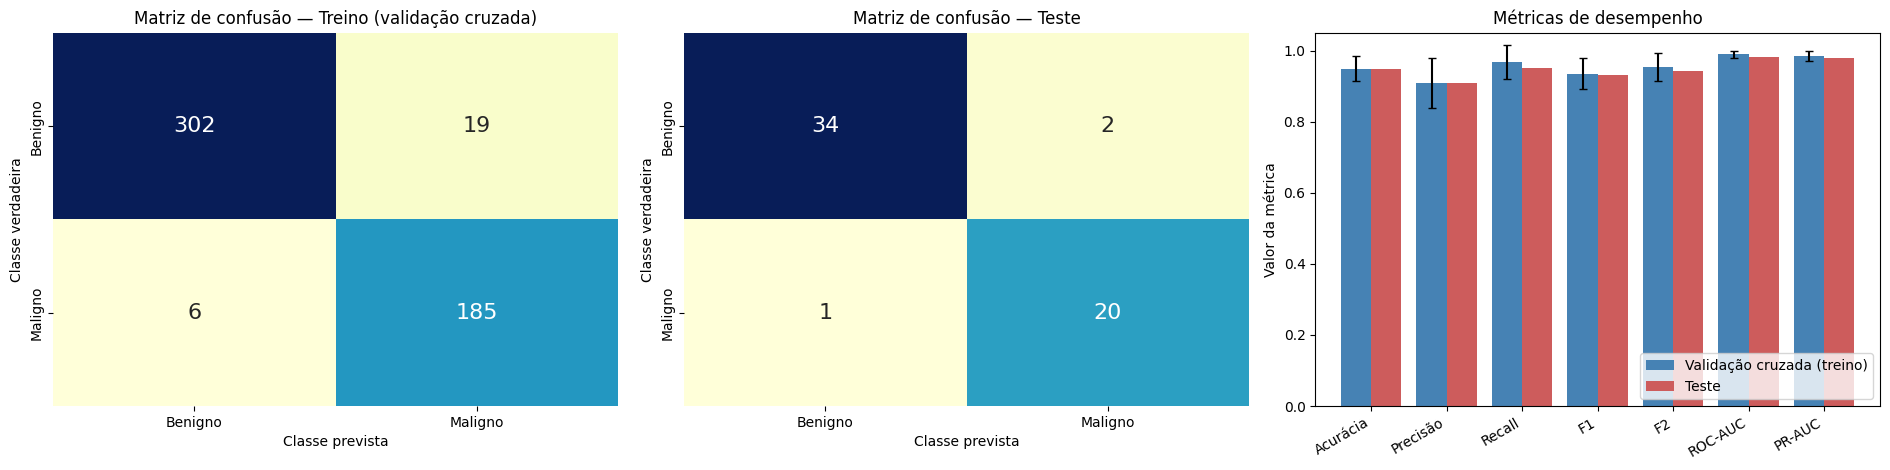

In [55]:
NOMES_ROTULOS = ["Benigno", "Maligno"]

# repetindo a validação cruzada
cv_comparacao = RepeatedStratifiedKFold(n_splits=10, n_repeats=3, random_state=SEMENTE_ALEATORIA + 1)

# desempenho da validação cruzada no treino
y_previsto_cv = cross_val_predict(melhor_knn, X_treino, y_treino, cv=cv_estratificado)

matriz_cv = confusion_matrix(y_treino, y_previsto_cv, labels=ordem_labels)

# métricas de desempenho em cada fold
cv_resultado = cross_validate(melhor_knn, X_treino, y_treino, cv=cv_comparacao, scoring=METRICAS)
metricas_cv = pd.DataFrame(
    {m.replace("test_", ""): v for m, v in cv_resultado.items() if m.startswith("test_")}
)

# previsões para o teste após eleger o melhor de cada um dos modelos
melhor_knn.fit(X_treino, y_treino)

y_previsto_teste = melhor_knn.predict(X_teste)
prob_teste = melhor_knn.predict_proba(X_teste)[:, 1]

matriz_teste = confusion_matrix(y_teste, y_previsto_teste, labels=ordem_labels)

metricas_teste = pd.Series(
    {
        "Acurácia": accuracy_score(y_teste, y_previsto_teste),
        "Precisão": precision_score(y_teste, y_previsto_teste, zero_division=0),
        "Recall": recall_score(y_teste, y_previsto_teste, zero_division=0),
        "F1": f1_score(y_teste, y_previsto_teste, zero_division=0),
        "F2": fbeta_score(y_teste, y_previsto_teste, beta=2, zero_division=0),
        "ROC-AUC": roc_auc_score(y_teste, prob_teste),
        "PR-AUC": average_precision_score(y_teste, prob_teste),
    }
)

# plotando a matriz de confusão e métricas de desempenho
fig, (eixo1, eixo2, eixo3) = plt.subplots(1, 3, figsize=(19, 4.8))

for eixo, matriz, titulo in [
    (eixo1, matriz_cv, "Treino (validação cruzada)"),
    (eixo2, matriz_teste, "Teste"),
]:
    df_conf = pd.DataFrame(matriz, NOMES_ROTULOS, NOMES_ROTULOS)
    sns.heatmap(df_conf, annot=True, annot_kws={"size": 16}, fmt="d", cmap="YlGnBu", cbar=False, ax=eixo)
    eixo.set(title=f"Matriz de confusão — {titulo}", xlabel="Classe prevista", ylabel="Classe verdadeira")

# obtendo as médias e desvios padrões das métricas de desempenho
medias_cv = metricas_cv.mean()
desvios_cv = metricas_cv.std()
nomes_cv = [NOMES_METRICAS[m] for m in medias_cv.index]

posicoes = range(len(nomes_cv))
eixo3.bar([p - 0.2 for p in posicoes], medias_cv.values, width=0.4, yerr=desvios_cv.values,
          capsize=3, label="Validação cruzada (treino)", color="steelblue")
eixo3.bar([p + 0.2 for p in posicoes], metricas_teste[nomes_cv].values, width=0.4,
          label="Teste", color="indianred")
eixo3.set_xticks(list(posicoes))
eixo3.set_xticklabels(nomes_cv, rotation=30, ha="right")
eixo3.set(ylim=(0, 1.05), ylabel="Valor da métrica", title="Métricas de desempenho")
eixo3.legend(loc="lower right")

fig.tight_layout()

# plotando uma tabela com as médias das métricas de desempenho
tabela_metricas = pd.DataFrame(
    {
        "Validação cruzada (média ± desvio)": [
            f"{metricas_cv[m].mean():.3f} ± {metricas_cv[m].std():.3f}" for m in metricas_cv.columns
        ],
        "Teste": metricas_teste[nomes_cv].round(3).values,
    },
    index=nomes_cv,
)

tabela_metricas

#### Avaliando a importância de cada atributo

,media,desvio
area2,0.0152,0.0158
radius2,0.0131,0.0085
perimeter2,0.0118,0.0084
area3,0.0074,0.0080
symmetry1,0.0057,0.0064
symmetry3,0.0057,0.0075


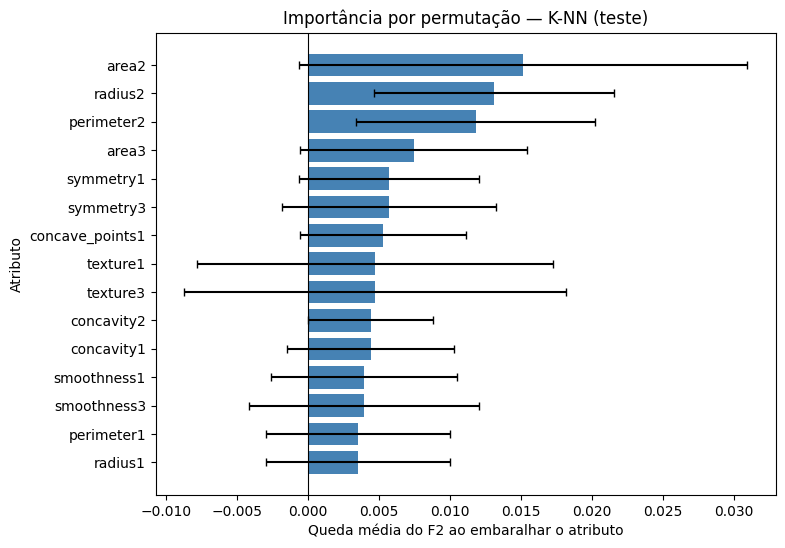

In [56]:
# quantidade de vezes que os atributos serão embaralhados
N_EMBARALHAMENTOS = 20

# verificando como cada atributo altera o F2_score
resultado_perm_knn = permutation_importance(
    melhor_knn, X_teste, y_teste,
    scoring=METRICAS["f2"],
    n_repeats=N_EMBARALHAMENTOS,
    random_state=SEMENTE_ALEATORIA,
    n_jobs=1,
)

importancia_perm_knn = pd.DataFrame(
    {"media": resultado_perm_knn.importances_mean, "desvio": resultado_perm_knn.importances_std},
    index=X_teste.columns,
).sort_values("media", ascending=False)

# plotando um gráfico para os 15 atributos mais importantes
topo_knn = importancia_perm_knn.head(15).iloc[::-1]

fig, eixo = plt.subplots(figsize=(8, 6))
eixo.barh(topo_knn.index, topo_knn["media"], xerr=topo_knn["desvio"], color="steelblue", capsize=3)
eixo.axvline(0, color="black", linewidth=0.8)
eixo.set(
    xlabel="Queda média do F2 ao embaralhar o atributo",
    ylabel="Atributo",
    title="Importância por permutação — K-NN (teste)",
)

# plotando uma tabela para os 6 atributos mais importantes
importancia_perm_knn.head(6).round(4)

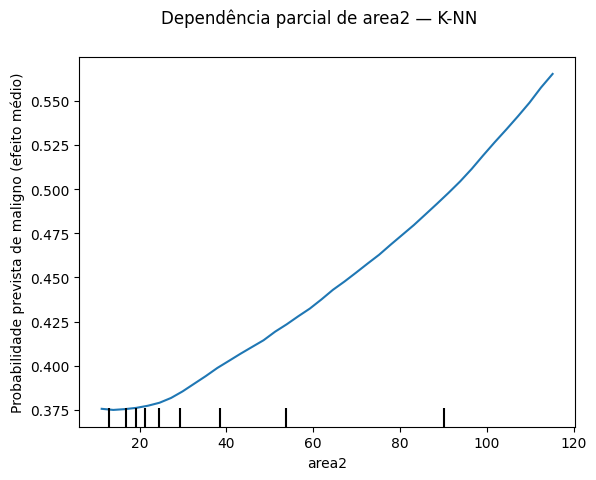

In [57]:
# fazendo um plot de dependência parcial para o atributo de maior importância na permutação
atributo_mais_importante_knn = importancia_perm_knn.index[0]

pdp_knn = PartialDependenceDisplay.from_estimator(
    melhor_knn,
    X_treino,
    features=[atributo_mais_importante_knn],
    kind="average",                  
    response_method="predict_proba", 
    grid_resolution=40,              
)
pdp_knn.figure_.suptitle(f"Dependência parcial de {atributo_mais_importante_knn} — K-NN")
pdp_knn.axes_[0, 0].set(ylabel="Probabilidade prevista de maligno (efeito médio)");

### Modelo Árvore de decisão

#### Árvore de decisão sem normalizador

In [58]:
# definindo as profundidades das árvores dee decisão
PROFUNDIDADE = 7

# instanciando o modelo em um pipeline
pipeline_arv_sem_norm = make_pipeline(DecisionTreeClassifier(max_depth=PROFUNDIDADE, random_state=SEMENTE_ALEATORIA))

# treinando o modelo
pipeline_arv_sem_norm.fit(X_treino, y_treino)

X_verdadeiro = X_treino
y_verdadeiro = y_treino

# realizando a validação cruzada estratificada
y_previsto_arv_sem_norm = cross_val_predict(pipeline_arv_sem_norm, X_verdadeiro, y_verdadeiro, cv=cv_estratificado)

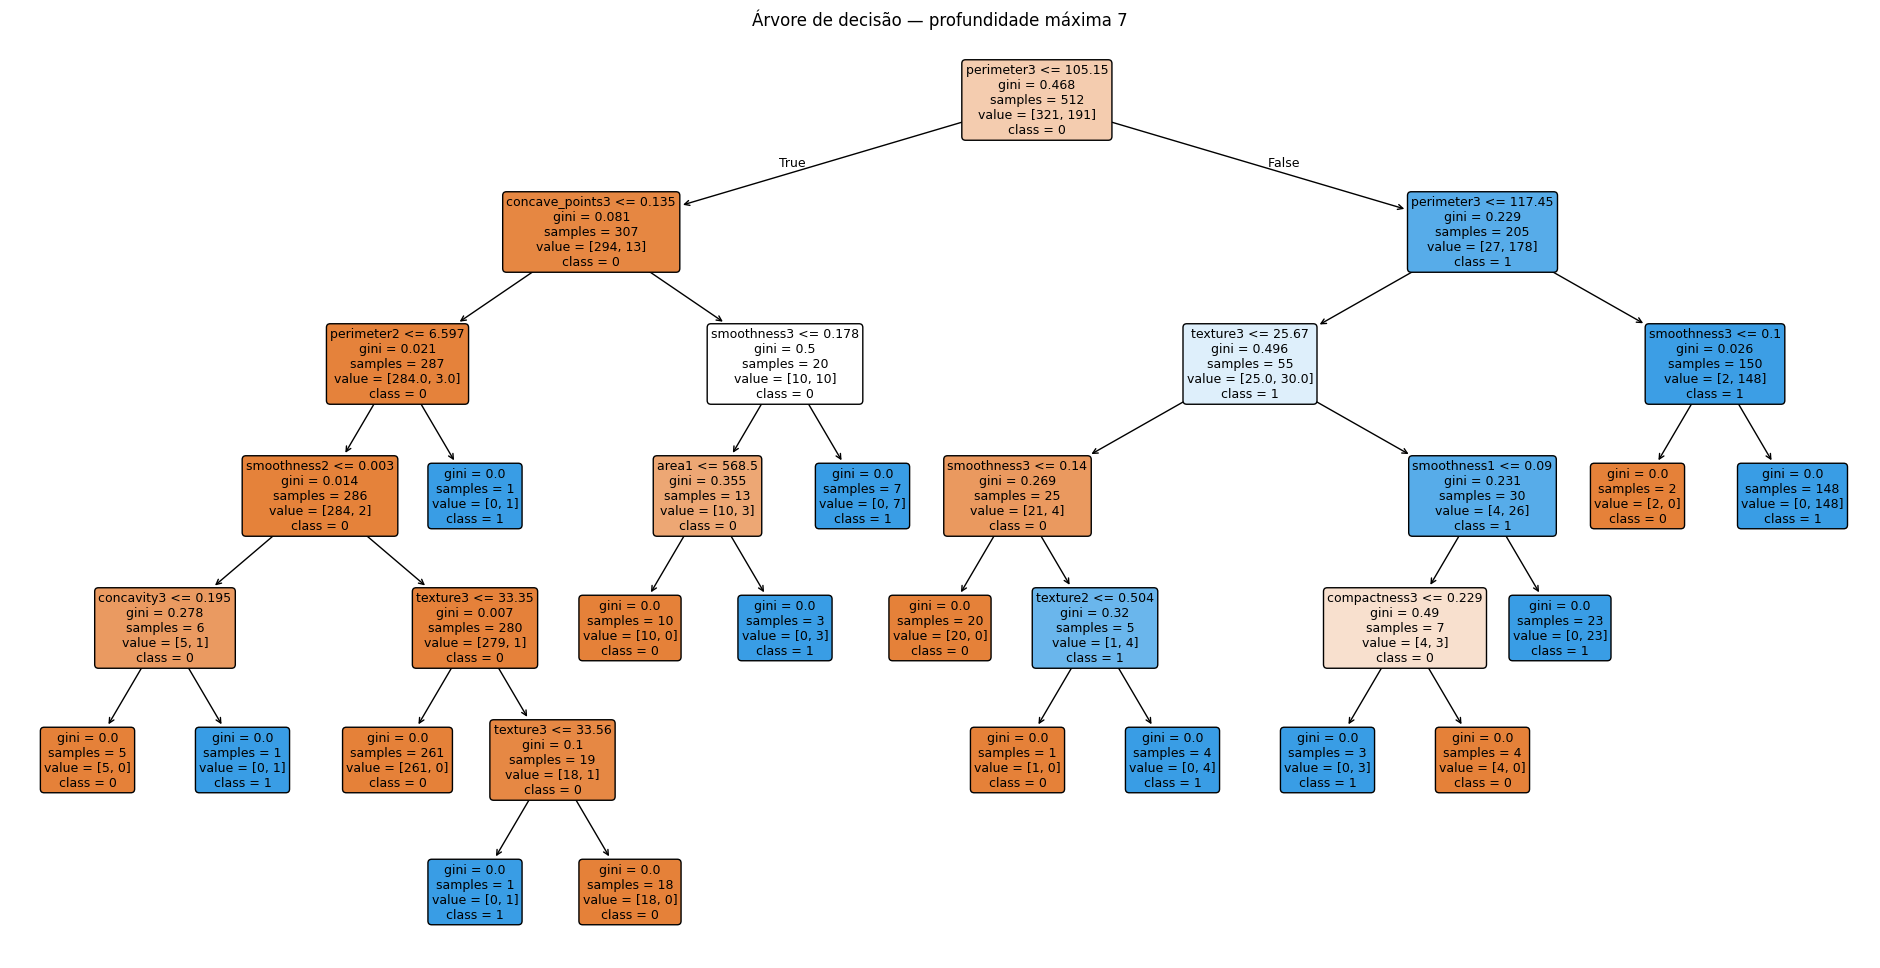

In [59]:
# acessando a árvore de decisão dentro do pipeline
arvore = pipeline_arv_sem_norm.named_steps["decisiontreeclassifier"]

# plotando a árvore de decisão
plt.figure(figsize=(24, 12))

plot_tree(
    arvore,
    feature_names=X_treino.columns,
    class_names=[str(classe) for classe in arvore.classes_],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title(f"Árvore de decisão — profundidade máxima {PROFUNDIDADE}")
plt.show()

[Text(0, 0.5, 'Benigno'), Text(0, 1.5, 'Maligno')]

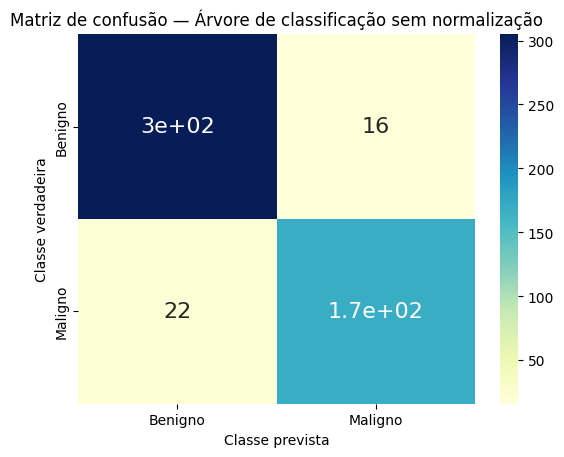

In [60]:
# plotando a matriz de confusão
matriz_conf = confusion_matrix(y_verdadeiro, y_previsto_arv_sem_norm, labels=ordem_labels)
df_conf = pd.DataFrame(matriz_conf, ordem_labels, ordem_labels)

matriz_conf_baseline_sem_norm = sns.heatmap(df_conf, annot=True, annot_kws={"size": 16}, cmap="YlGnBu");

matriz_conf_baseline_sem_norm.set_xlabel("Classe prevista")
matriz_conf_baseline_sem_norm.set_ylabel("Classe verdadeira")
matriz_conf_baseline_sem_norm.set_title("Matriz de confusão — Árvore de classificação sem normalização")

matriz_conf_baseline_sem_norm.set_xticklabels(["Benigno", "Maligno"])
matriz_conf_baseline_sem_norm.set_yticklabels(["Benigno", "Maligno"])

In [61]:
# verificando algumas das melhores métricas de desempenho
acuracia_arv_sem_norm = accuracy_score(y_verdadeiro, y_previsto_arv_sem_norm)
f1_arv_sem_norm = f1_score(y_verdadeiro, y_previsto_arv_sem_norm)
f2_arv_sem_norm = fbeta_score(y_verdadeiro, y_previsto_arv_sem_norm, beta=2, zero_division=0)

print(f"Acurácia = {(acuracia_arv_sem_norm*100):.2f}%")
print(f"F1_score = {f1_arv_sem_norm*100:.2f}%")
print(f"F2_score = {f2_arv_sem_norm*100:.2f}%")

Acurácia = 92.58%
F1_score = 89.89%
F2_score = 89.04%


In [62]:
# obtendo as médias e desvios padrões para as métricas de desempenho da validação cruzada
resultados_arv_sem_norm = cross_validate(pipeline_arv_sem_norm, X_treino, y_treino, cv=NUM_FOLDS, scoring=METRICAS)

metricas_arv_sem_norm = (
    pd.DataFrame({k.replace("test_", ""): v for k, v in resultados_arv_sem_norm.items() if k.startswith("test_")})
    .agg(["mean", "std"])
    .T.rename(index=NOMES_METRICAS)
)

metricas_arv_sem_norm

,mean,std
Acurácia,0.925867,0.035244
Precisão,0.902203,0.067857
Recall,0.906316,0.071814
F1,0.901295,0.045327
F2,0.903586,0.056817
ROC-AUC,0.921873,0.037810
PR-AUC,0.851835,0.066994


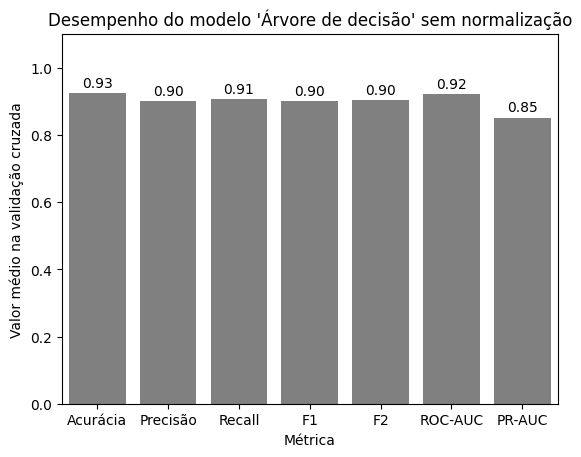

In [63]:
# plotando um gráfico de barras com as médias das métricas de desempenho
medias_arv_sem_norm = metricas_arv_sem_norm["mean"]

eixo = sns.barplot(x=medias_arv_sem_norm.index, y=medias_arv_sem_norm.values, color="gray")

for container in eixo.containers:
    eixo.bar_label(container, fmt="%.2f", padding=2)

eixo.set(
    xlabel="Métrica",
    ylabel="Valor médio na validação cruzada",
    title="Desempenho do modelo 'Árvore de decisão' sem normalização",
    ylim=(0, 1.1),
);

#### Árvore de decisão com normalizador padrão

In [64]:
# instanciando o modelo dentro de um pipeline
pipeline_arv_norm_pad = make_pipeline(StandardScaler(), DecisionTreeClassifier(max_depth=PROFUNDIDADE, random_state=SEMENTE_ALEATORIA))

# treinando o modelo
pipeline_arv_norm_pad.fit(X_treino, y_treino)

X_verdadeiro = X_treino
y_verdadeiro = y_treino

# aplicando a validação cruzada estratificada
y_previsto_arv_norm_pad = cross_val_predict(pipeline_arv_norm_pad, X_verdadeiro, y_verdadeiro, cv=cv_estratificado)

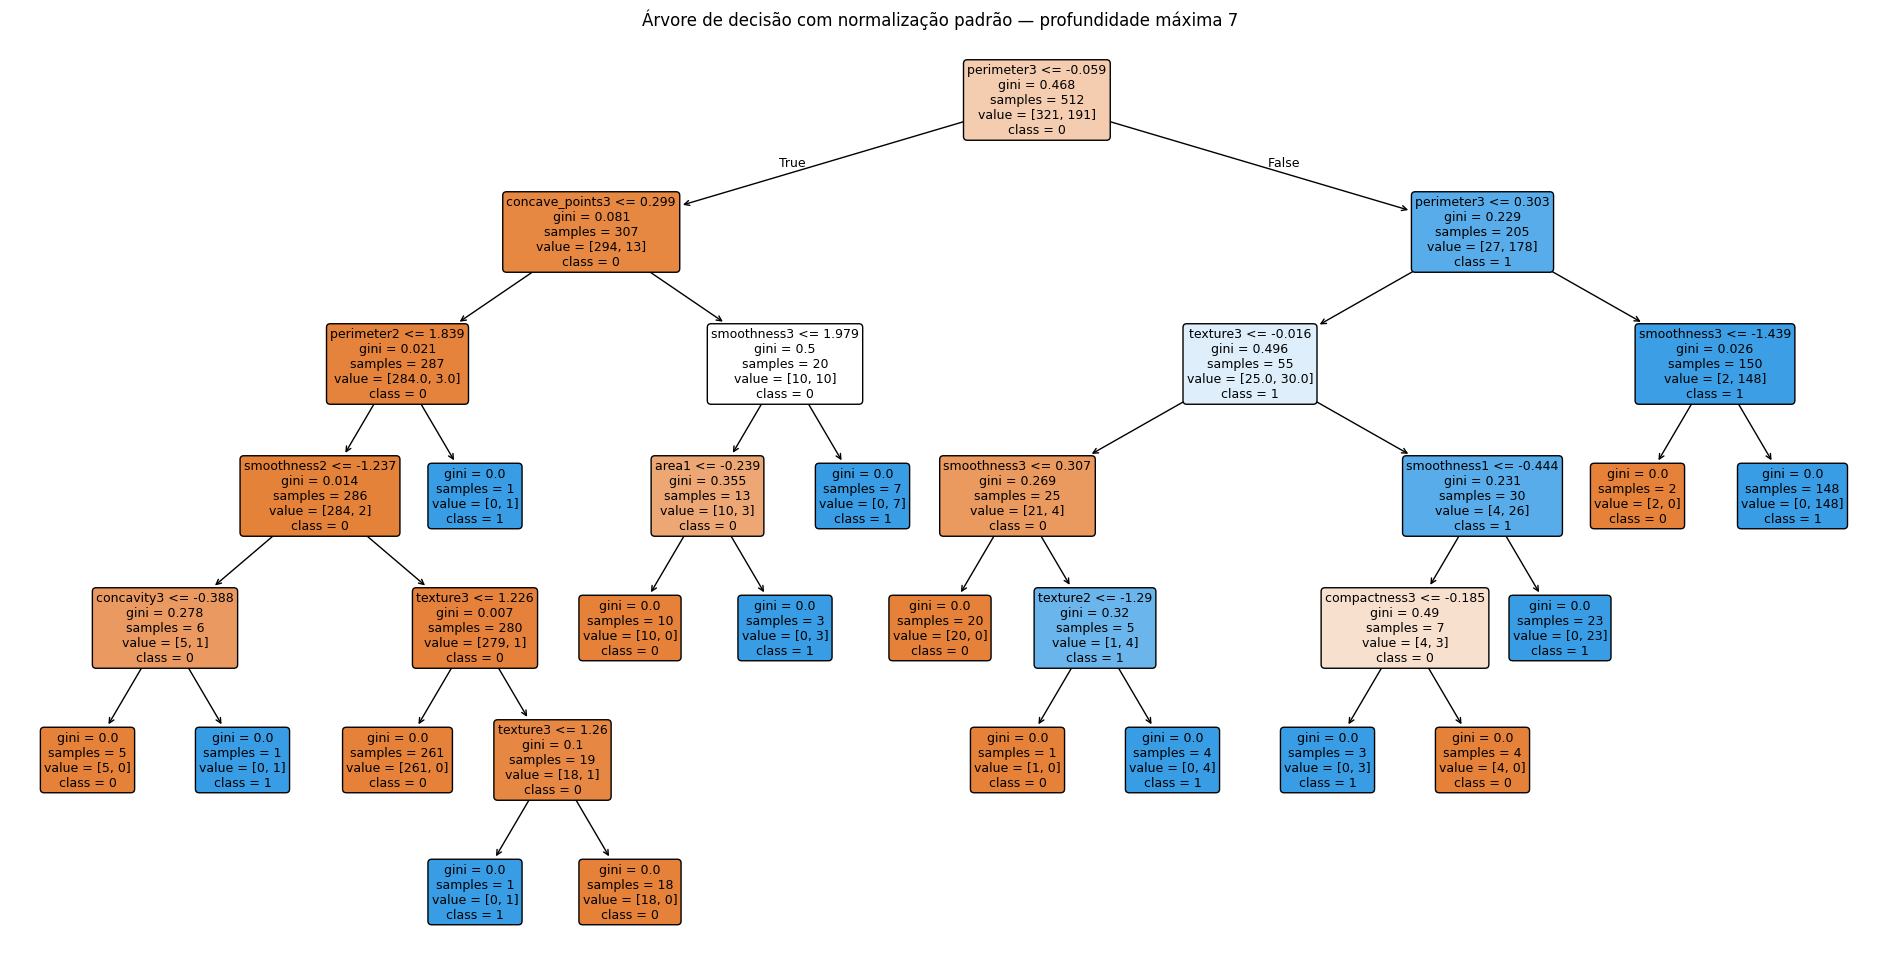

In [65]:
# acessando o modelo dentro do pipeline
arvore = pipeline_arv_norm_pad.named_steps["decisiontreeclassifier"]

# plotando a árvore de decisão
plt.figure(figsize=(24, 12))

plot_tree(
    arvore,
    feature_names=X_treino.columns,
    class_names=[str(classe) for classe in arvore.classes_],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title(f"Árvore de decisão com normalização padrão — profundidade máxima {PROFUNDIDADE}")
plt.show()

[Text(0, 0.5, 'Benigno'), Text(0, 1.5, 'Maligno')]

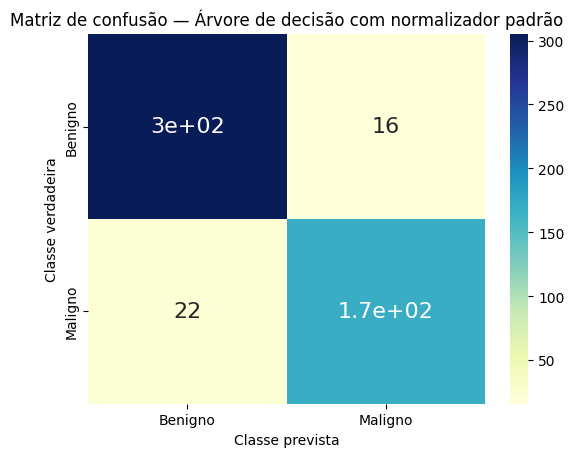

In [66]:
# plotando a matriz de confusão
matriz_conf = confusion_matrix(y_verdadeiro, y_previsto_arv_norm_pad, labels=ordem_labels)
df_conf = pd.DataFrame(matriz_conf, ordem_labels, ordem_labels)

matriz_conf_baseline_sem_norm = sns.heatmap(df_conf, annot=True, annot_kws={"size": 16}, cmap="YlGnBu");

matriz_conf_baseline_sem_norm.set_xlabel("Classe prevista")
matriz_conf_baseline_sem_norm.set_ylabel("Classe verdadeira")
matriz_conf_baseline_sem_norm.set_title("Matriz de confusão — Árvore de decisão com normalizador padrão")

matriz_conf_baseline_sem_norm.set_xticklabels(["Benigno", "Maligno"])
matriz_conf_baseline_sem_norm.set_yticklabels(["Benigno", "Maligno"])

In [67]:
# verificando algumas das melhores métricas de desemepnho obtidas
acuracia_arv_norm_pad = accuracy_score(y_verdadeiro, y_previsto_arv_norm_pad)
f1_arv_norm_pad = f1_score(y_verdadeiro, y_previsto_arv_norm_pad)
f2_arv_norm_pad = fbeta_score(y_verdadeiro, y_previsto_arv_norm_pad, beta=2, zero_division=0)

print(f"Acurácia = {(acuracia_arv_norm_pad*100):.2f}%")
print(f"F1_score = {f1_arv_norm_pad*100:.2f}%")
print(f"F2_score = {f2_arv_norm_pad*100:.2f}%")

Acurácia = 92.58%
F1_score = 89.89%
F2_score = 89.04%


In [68]:
# visualizando as médias e desvios padrões das métricas de desempenho obtidas pela validação cruzada

resultados_arv_norm_pad = cross_validate(pipeline_arv_norm_pad, X_treino, y_treino, cv=NUM_FOLDS, scoring=METRICAS)

metricas_arv_norm_pad = (
    pd.DataFrame({k.replace("test_", ""): v for k, v in resultados_arv_norm_pad.items() if k.startswith("test_")})
    .agg(["mean", "std"])
    .T.rename(index=NOMES_METRICAS)
)

metricas_arv_norm_pad

,mean,std
Acurácia,0.925867,0.035244
Precisão,0.902203,0.067857
Recall,0.906316,0.071814
F1,0.901295,0.045327
F2,0.903586,0.056817
ROC-AUC,0.921873,0.037810
PR-AUC,0.851835,0.066994


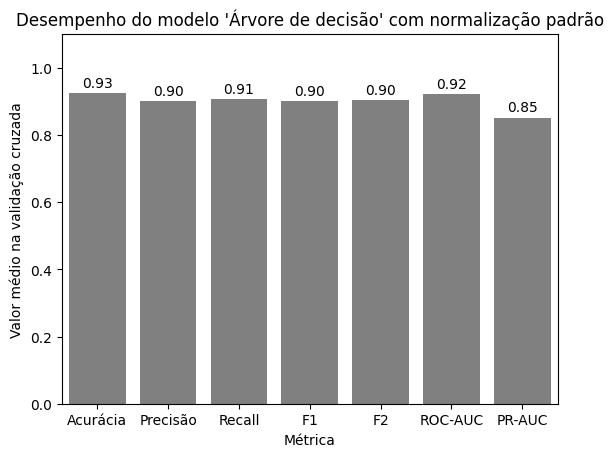

In [69]:
# plotando um gráfico de barras com as médias das métricas de desempenho
medias_arv_norm_pad = metricas_arv_norm_pad["mean"]

eixo = sns.barplot(x=medias_arv_norm_pad.index, y=medias_arv_norm_pad.values, color="gray")

for container in eixo.containers:
    eixo.bar_label(container, fmt="%.2f", padding=2)

eixo.set(
    xlabel="Métrica",
    ylabel="Valor médio na validação cruzada",
    title="Desempenho do modelo 'Árvore de decisão' com normalização padrão",
    ylim=(0, 1.1),
);

#### Árvore de decisão com normalizador pelo máximo absoluto

In [70]:
# instanciando o modelo dentro de um pipeline
pipeline_arv_norm_max = make_pipeline(MaxAbsScaler(), DecisionTreeClassifier(max_depth=PROFUNDIDADE, random_state=SEMENTE_ALEATORIA))

# treinando o modelo
pipeline_arv_norm_max.fit(X_treino, y_treino)

X_verdadeiro = X_treino
y_verdadeiro = y_treino

# aplicando a validação cruzada estratificada
y_previsto_arv_norm_max = cross_val_predict(pipeline_arv_norm_max, X_verdadeiro, y_verdadeiro, cv=cv_estratificado)

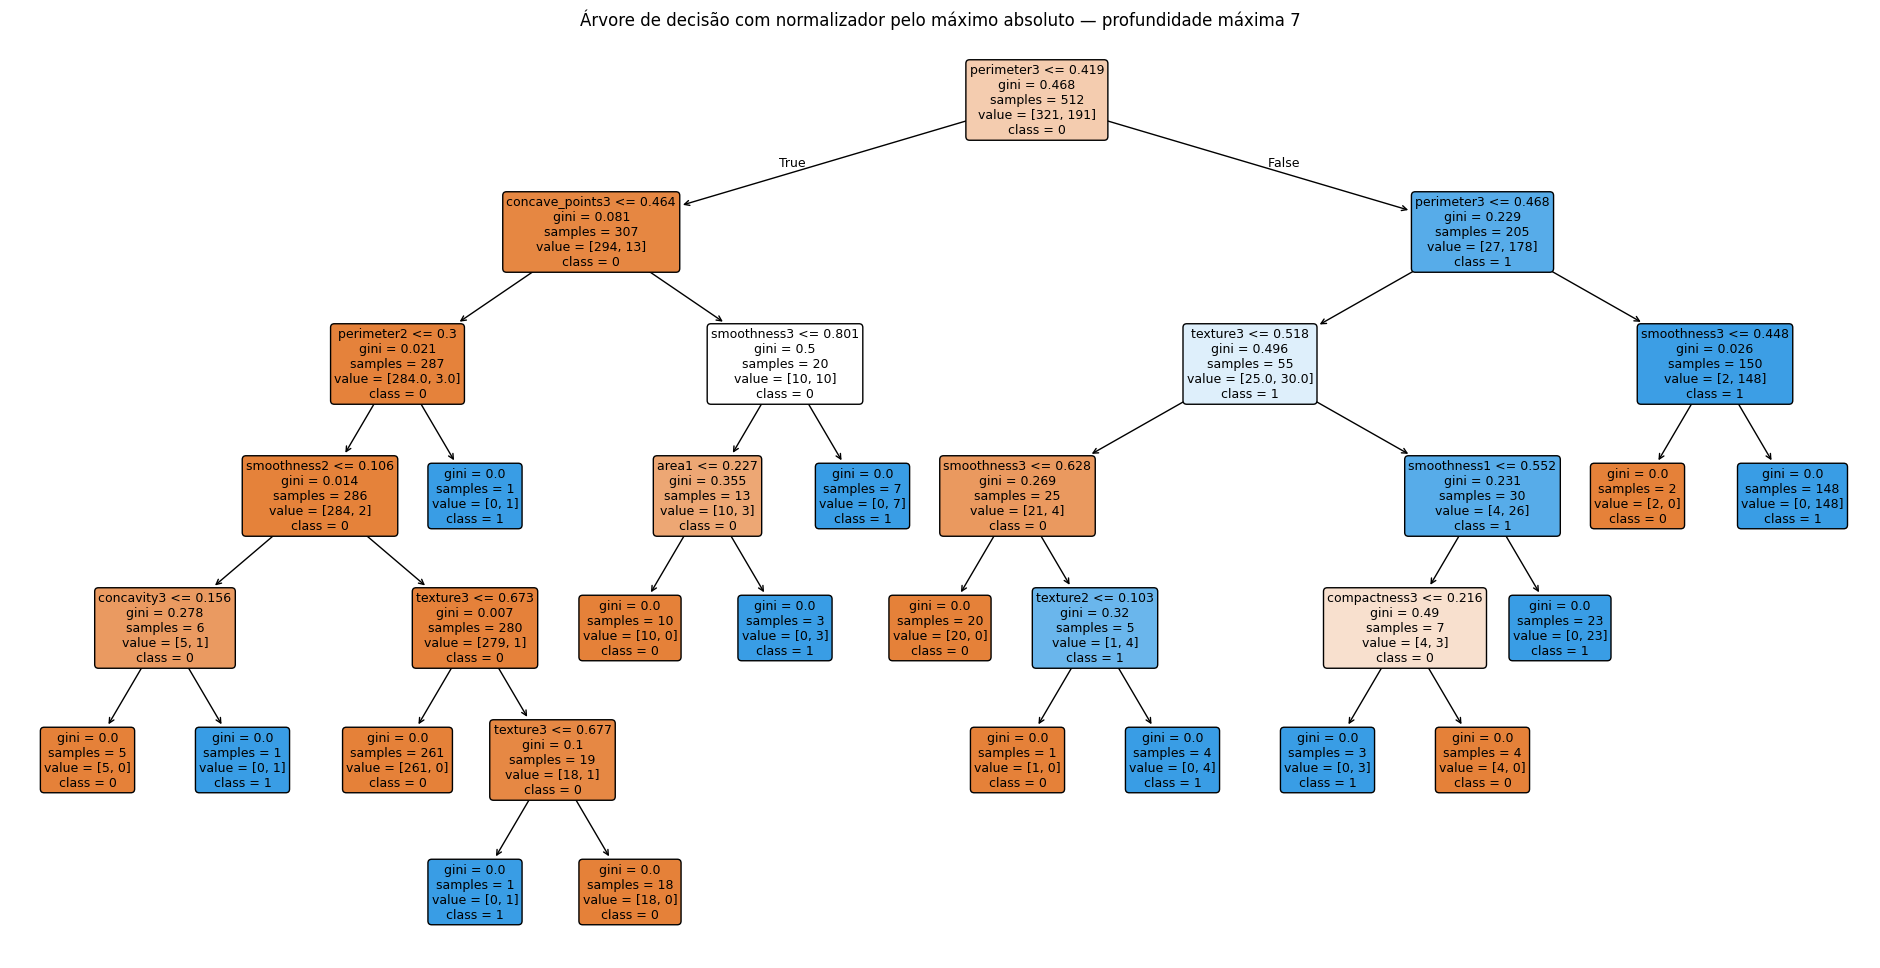

In [71]:
# acessando a árvore dentro do pipeline
arvore = pipeline_arv_norm_max.named_steps["decisiontreeclassifier"]

# plotando a árvore
plt.figure(figsize=(24, 12))

plot_tree(
    arvore,
    feature_names=X_treino.columns,
    class_names=[str(classe) for classe in arvore.classes_],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title(f"Árvore de decisão com normalizador pelo máximo absoluto — profundidade máxima {PROFUNDIDADE}")
plt.show()

[Text(0, 0.5, 'Benigno'), Text(0, 1.5, 'Maligno')]

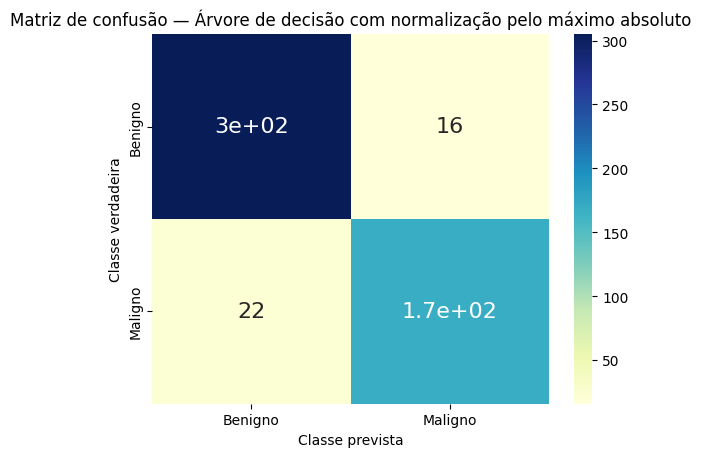

In [72]:
# plotando a matriz de desempenho
matriz_conf = confusion_matrix(y_verdadeiro, y_previsto_arv_norm_max, labels=ordem_labels)
df_conf = pd.DataFrame(matriz_conf, ordem_labels, ordem_labels)

matriz_conf_baseline_sem_norm = sns.heatmap(df_conf, annot=True, annot_kws={"size": 16}, cmap="YlGnBu");

matriz_conf_baseline_sem_norm.set_xlabel("Classe prevista")
matriz_conf_baseline_sem_norm.set_ylabel("Classe verdadeira")
matriz_conf_baseline_sem_norm.set_title("Matriz de confusão — Árvore de decisão com normalização pelo máximo absoluto")

matriz_conf_baseline_sem_norm.set_xticklabels(["Benigno", "Maligno"])
matriz_conf_baseline_sem_norm.set_yticklabels(["Benigno", "Maligno"])

In [73]:
# verificando algumas das melhores métricas de desempenho obtidas
acuracia_arv_norm_max = accuracy_score(y_verdadeiro, y_previsto_arv_norm_max)
f1_arv_norm_max = f1_score(y_verdadeiro, y_previsto_arv_norm_max)
f2_arv_norm_max = fbeta_score(y_verdadeiro, y_previsto_arv_norm_max, beta=2, zero_division=0)

print(f"Acurácia = {(acuracia_arv_norm_max*100):.2f}%")
print(f"F1_score = {f1_arv_norm_max*100:.2f}%")
print(f"F2_score = {f2_arv_norm_max*100:.2f}%")

Acurácia = 92.58%
F1_score = 89.89%
F2_score = 89.04%


In [74]:
# verificando as médias e desvios padrões obtidos pela validação cruzada
resultados_arv_norm_max = cross_validate(pipeline_arv_norm_max, X_treino, y_treino, cv=NUM_FOLDS, scoring=METRICAS)

metricas_arv_norm_max = (
    pd.DataFrame({k.replace("test_", ""): v for k, v in resultados_arv_norm_max.items() if k.startswith("test_")})
    .agg(["mean", "std"])
    .T.rename(index=NOMES_METRICAS)
)

metricas_arv_norm_max

,mean,std
Acurácia,0.925867,0.035244
Precisão,0.902203,0.067857
Recall,0.906316,0.071814
F1,0.901295,0.045327
F2,0.903586,0.056817
ROC-AUC,0.921873,0.037810
PR-AUC,0.851835,0.066994


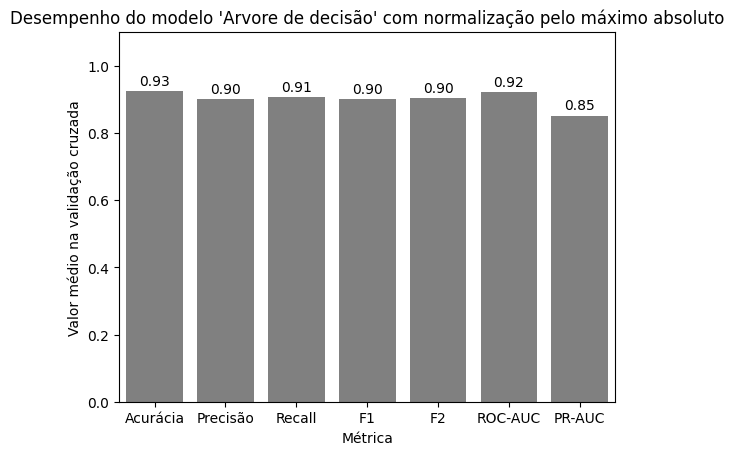

In [75]:
# plotando um gráfico de barras com as médias das métricas de desempenho
medias_arv_norm_max = metricas_arv_norm_max["mean"]

eixo = sns.barplot(x=medias_arv_norm_max.index, y=medias_arv_norm_max.values, color="gray")

for container in eixo.containers:
    eixo.bar_label(container, fmt="%.2f", padding=2)

eixo.set(
    xlabel="Métrica",
    ylabel="Valor médio na validação cruzada",
    title="Desempenho do modelo 'Arvore de decisão' com normalização pelo máximo absoluto",
    ylim=(0, 1.1),
);

#### Árvore de decisão com normalizador pelo máximo e mínimo

In [76]:
# instanciando o modelo dentro de um pipeline
pipeline_arv_norm_min_max = make_pipeline(MinMaxScaler(), DecisionTreeClassifier(max_depth=PROFUNDIDADE, random_state=SEMENTE_ALEATORIA))

# treinando o modelo
pipeline_arv_norm_min_max.fit(X_treino, y_treino)

X_verdadeiro = X_treino
y_verdadeiro = y_treino

# aplicando a validação cruzada estratificada 
y_previsto_arv_norm_min_max = cross_val_predict(pipeline_arv_norm_min_max, X_verdadeiro, y_verdadeiro, cv=cv_estratificado)

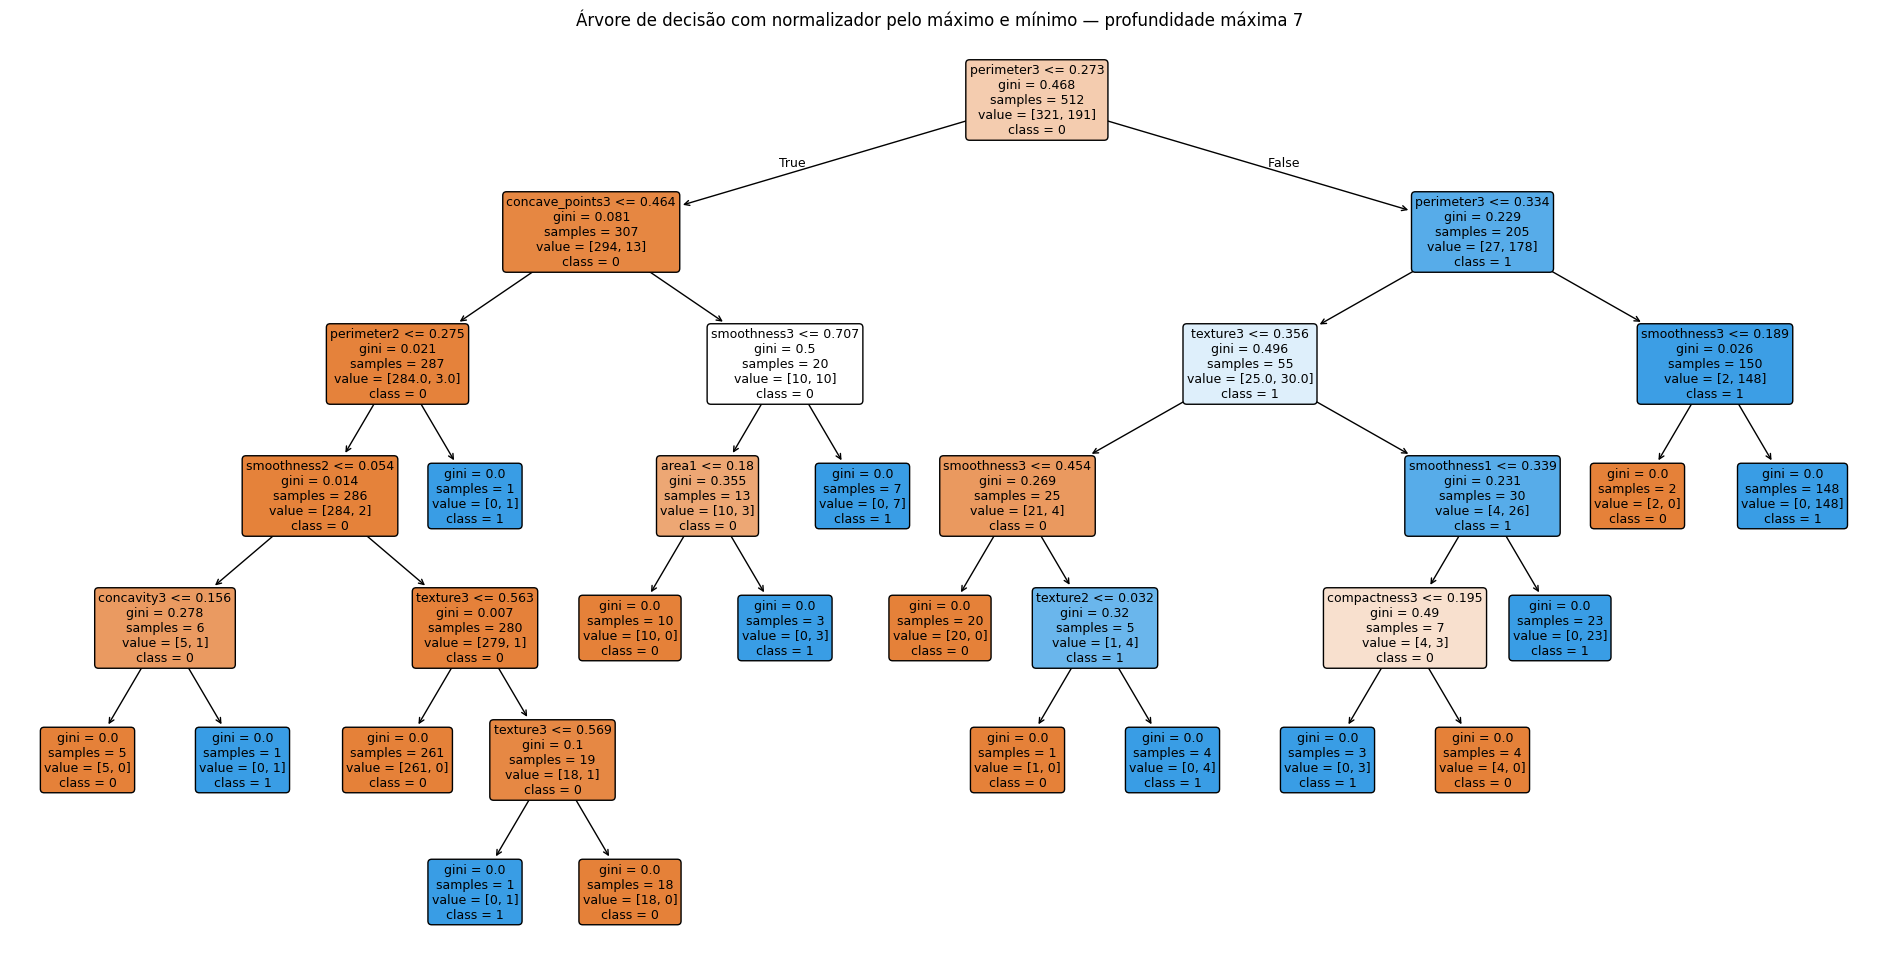

In [77]:
# acessando o modelo dentro do pipeline
arvore = pipeline_arv_norm_min_max.named_steps["decisiontreeclassifier"]

# plotando a árvore de decisão
plt.figure(figsize=(24, 12))

plot_tree(
    arvore,
    feature_names=X_treino.columns,
    class_names=[str(classe) for classe in arvore.classes_],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title(f"Árvore de decisão com normalizador pelo máximo e mínimo — profundidade máxima {PROFUNDIDADE}")
plt.show()

[Text(0, 0.5, 'Benigno'), Text(0, 1.5, 'Maligno')]

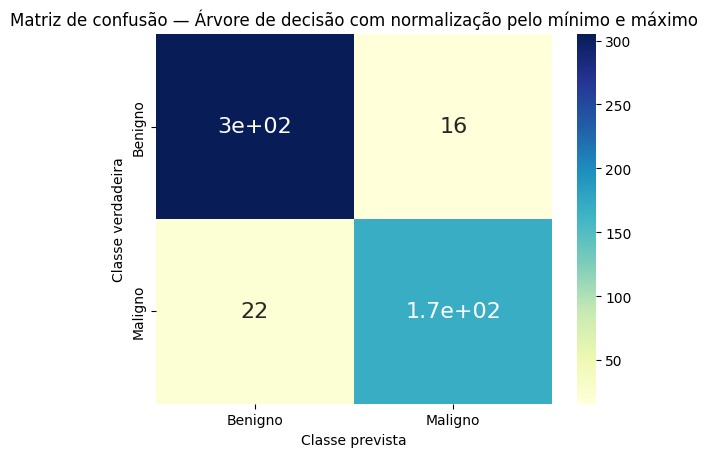

In [78]:
# plotando a matriz de confusão
matriz_conf = confusion_matrix(y_verdadeiro, y_previsto_arv_norm_min_max, labels=ordem_labels)
df_conf = pd.DataFrame(matriz_conf, ordem_labels, ordem_labels)

matriz_conf_baseline_sem_norm = sns.heatmap(df_conf, annot=True, annot_kws={"size": 16}, cmap="YlGnBu");

matriz_conf_baseline_sem_norm.set_xlabel("Classe prevista")
matriz_conf_baseline_sem_norm.set_ylabel("Classe verdadeira")
matriz_conf_baseline_sem_norm.set_title("Matriz de confusão — Árvore de decisão com normalização pelo mínimo e máximo")

matriz_conf_baseline_sem_norm.set_xticklabels(["Benigno", "Maligno"])
matriz_conf_baseline_sem_norm.set_yticklabels(["Benigno", "Maligno"])

In [79]:
# acessando algumas das melhores métricas de desempenho obtidas pela validação cruzada
acuracia_arv_norm_min_max = accuracy_score(y_verdadeiro, y_previsto_arv_norm_min_max)
f1_arv_norm_min_max = f1_score(y_verdadeiro, y_previsto_arv_norm_min_max)
f2_arv_norm_min_max = fbeta_score(y_verdadeiro, y_previsto_arv_norm_min_max, beta=2, zero_division=0)

print(f"Acurácia = {(acuracia_arv_norm_min_max*100):.2f}%")
print(f"F1_score = {f1_arv_norm_min_max*100:.2f}%")
print(f"F2_score = {f2_arv_norm_min_max*100:.2f}%")

Acurácia = 92.58%
F1_score = 89.89%
F2_score = 89.04%


In [80]:
# obtendo as médias e desvios padrões das métricas de desempenhoregistradas durante a validação cruzada
resultados_arv_norm_min_max = cross_validate(pipeline_arv_norm_min_max, X_treino, y_treino, cv=NUM_FOLDS, scoring=METRICAS)

metricas_arv_norm_min_max = (
    pd.DataFrame({k.replace("test_", ""): v for k, v in resultados_arv_norm_min_max.items() if k.startswith("test_")})
    .agg(["mean", "std"])
    .T.rename(index=NOMES_METRICAS)
)

metricas_arv_norm_min_max

,mean,std
Acurácia,0.925867,0.035244
Precisão,0.902203,0.067857
Recall,0.906316,0.071814
F1,0.901295,0.045327
F2,0.903586,0.056817
ROC-AUC,0.921873,0.037810
PR-AUC,0.851835,0.066994


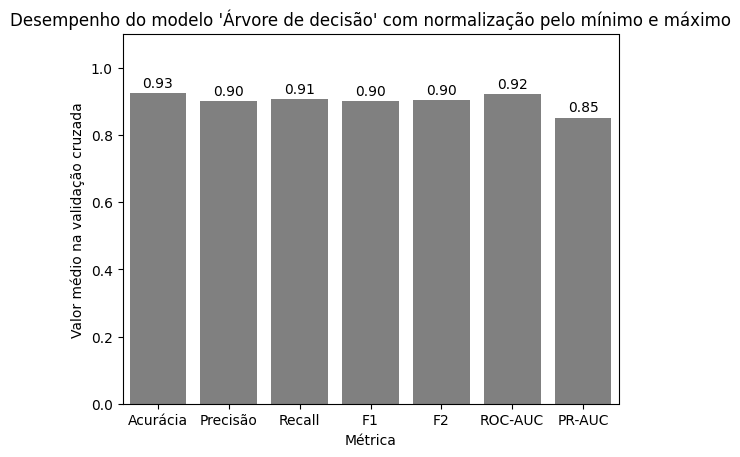

In [81]:
# plotando um gráfico de barras com as médias das métricas de desempenho
medias_arv_norm_min_max = metricas_arv_norm_min_max["mean"]

eixo = sns.barplot(x=medias_arv_norm_min_max.index, y=medias_arv_norm_min_max.values, color="gray")

for container in eixo.containers:
    eixo.bar_label(container, fmt="%.2f", padding=2)

eixo.set(
    xlabel="Métrica",
    ylabel="Valor médio na validação cruzada",
    title="Desempenho do modelo 'Árvore de decisão' com normalização pelo mínimo e máximo",
    ylim=(0, 1.1),
);

#### Comparando as diferentes árvores de decisão construídas

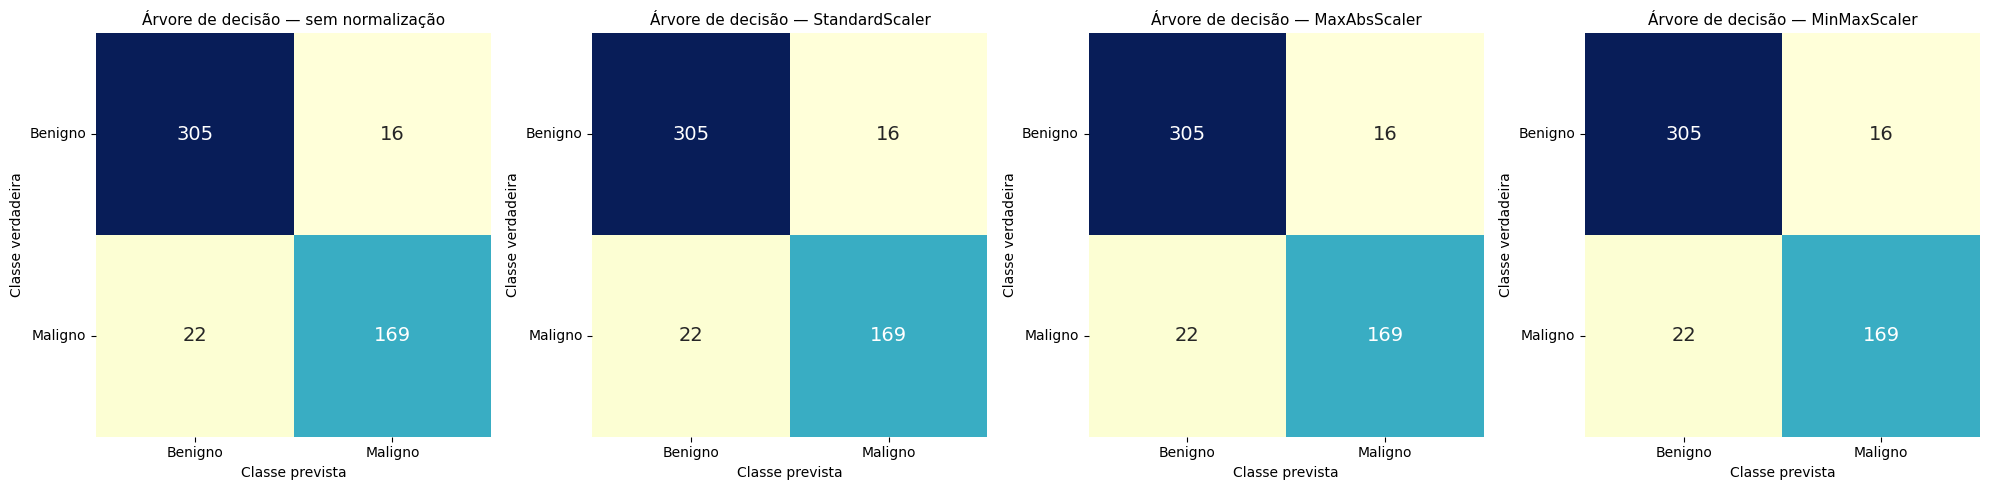

In [82]:
# árvores de decisão a serem comparadas
modelos_arvore = [
    ("Árvore de decisão — sem normalização", y_verdadeiro, y_previsto_arv_sem_norm),
    ("Árvore de decisão — StandardScaler", y_verdadeiro, y_previsto_arv_norm_pad),
    ("Árvore de decisão — MaxAbsScaler", y_verdadeiro, y_previsto_arv_norm_max),
    ("Árvore de decisão — MinMaxScaler", y_verdadeiro, y_previsto_arv_norm_min_max)
]

# plotando as matrizes lado a lado
fig, eixos = plt.subplots(1, 4, figsize=(20, 5))

for ax, (nome, y_true, y_pred) in zip(eixos, modelos_arvore):

    # obtendo a amtriz de decisão de cada modelo
    matriz_conf = confusion_matrix(y_true, y_pred, labels=ordem_labels)

    df_conf = pd.DataFrame(matriz_conf, index=ordem_labels, columns=ordem_labels)

    # plotando a matriz de confusão
    sns.heatmap(
        df_conf,
        annot=True,
        annot_kws={"size": 14},
        cmap="YlGnBu",
        fmt="d",
        cbar=False,
        ax=ax
    )

    ax.set_title(nome, fontsize=11)
    ax.set_xlabel("Classe prevista", fontsize=10)
    ax.set_ylabel("Classe verdadeira", fontsize=10)
    ax.set_xticklabels(["Benigno", "Maligno"])
    ax.set_yticklabels(["Benigno", "Maligno"], rotation=0)

plt.tight_layout()

plt.show()


In [83]:
# comparando as métricas de desempenho obtidas para cada uma da sárvores de decisão
pipelines_arv = {
    "Sem normalizador": pipeline_arv_sem_norm,
    "Normalizador padrão": pipeline_arv_norm_pad,
    "Máximo absoluto": pipeline_arv_norm_max,
    "Máximo e mínimo": pipeline_arv_norm_min_max,
}

resultados_arv = {}

for nome, pipeline in pipelines_arv.items():
    cv_resultado = cross_validate(pipeline, X_treino, y_treino, cv=cv_estratificado, scoring=METRICAS)
    resultados_arv[nome] = pd.DataFrame(
        {m.replace("test_", ""): v for m, v in cv_resultado.items() if m.startswith("test_")}
    )

# plotando a tabela com a média de cada métrica e sua incerteza
tabela_arv = pd.DataFrame(
    {
        nome: {NOMES_METRICAS[m]: f"{df_[m].mean():.3f} ± {df_[m].std():.3f}" for m in METRICAS}
        for nome, df_ in resultados_arv.items()
    }
).T

tabela_arv

,Acurácia,Precisão,Recall,F1,F2,ROC-AUC,PR-AUC
Sem normalizador,0.926 ± 0.020,0.918 ± 0.059,0.885 ± 0.049,0.899 ± 0.027,0.890 ± 0.035,0.917 ± 0.020,0.854 ± 0.045
Normalizador padrão,0.926 ± 0.020,0.918 ± 0.059,0.885 ± 0.049,0.899 ± 0.027,0.890 ± 0.035,0.917 ± 0.020,0.854 ± 0.045
Máximo absoluto,0.926 ± 0.020,0.918 ± 0.059,0.885 ± 0.049,0.899 ± 0.027,0.890 ± 0.035,0.917 ± 0.020,0.854 ± 0.045
Máximo e mínimo,0.926 ± 0.020,0.918 ± 0.059,0.885 ± 0.049,0.899 ± 0.027,0.890 ± 0.035,0.917 ± 0.020,0.854 ± 0.045


#### Testando diferentes conjuntos de hiperparâmetros

In [84]:
# criando um estudo do optuna
estudo_arvore = create_study(
    direction="maximize",
    study_name="tiamat_arvore_decisao_v2",
    storage=f"sqlite:///{PASTA_ESTUDOS}/arvore_decisao_v2.db",
    load_if_exists=True,
    sampler=TPESampler(
        multivariate=True,
        seed=SEMENTE_ALEATORIA
    ),
)

concluidas = sum(
    t.state == TrialState.COMPLETE
    for t in estudo_arvore.trials
)

# laço de otimização (ask-and-tell)
for _ in range(max(0, NUM_TENTATIVAS - concluidas)):

    tentativa = estudo_arvore.ask()

    criterion = tentativa.suggest_categorical("criterion", ["gini", "entropy", "log_loss"])

    max_depth = tentativa.suggest_int("max_depth", 1, 30)

    min_samples_split = tentativa.suggest_int("min_samples_split", 2, 30)

    min_samples_leaf = tentativa.suggest_int("min_samples_leaf", 1, 20)

    max_features = tentativa.suggest_categorical("max_features", [None, "sqrt", "log2"])

    class_weight = tentativa.suggest_categorical("class_weight", [None, "balanced"])

    ccp_alpha = tentativa.suggest_float("ccp_alpha", 1e-5, 0.05, log=True)

    # treinando o modelo
    modelo = DecisionTreeClassifier(
        criterion=criterion,
        max_depth=max_depth,
        min_samples_split=min_samples_split,
        min_samples_leaf=min_samples_leaf,
        max_features=max_features,
        class_weight=class_weight,
        ccp_alpha=ccp_alpha,
        random_state=SEMENTE_ALEATORIA
    )

    valor = cross_val_score(
        modelo,
        X_treino,
        y_treino,
        scoring=METRICAS["f2"],
        cv=cv_otimizacao,
        n_jobs=-1
    ).mean()

    estudo_arvore.tell(tentativa, valor)

# obtendo os resultados dos testes
print(
    f"Tentativas concluídas: "
    f"{sum(t.state == TrialState.COMPLETE for t in estudo_arvore.trials)}"
    f" | Melhor F2 (CV): {estudo_arvore.best_value:.4f}"
)

# printando os hiperparâmetros que obtiveram o melhor desempenho
print("\nMelhores hiperparâmetros:")
for nome, valor in estudo_arvore.best_params.items():
    print(f"  {nome}: {valor}")

# obtendo a importância de cada hiperparâmetro
print("\nImportância dos hiperparâmetros:")
print(get_param_importances(estudo_arvore))

# ajustando o melhor modelo aos dados de treino
parametros_arvore = estudo_arvore.best_params.copy()

melhor_arvore = DecisionTreeClassifier(
    **parametros_arvore,
    random_state=SEMENTE_ALEATORIA
)

melhor_arvore.fit(X_treino, y_treino)

c:\venv\ilumpy\Lib\site-packages\optuna\_experimental.py:32: ExperimentalWarning: Argument ``multivariate`` is an experimental feature. The interface can change in the future.
  warnings.warn(
[I 2026-10-18 18:45:30,143] Using an existing study with name 'tiamat_arvore_decisao_v2' instead of creating a new one.


Tentativas concluídas: 130 | Melhor F2 (CV): 0.9493

Melhores hiperparâmetros:
  criterion: log_loss
  max_depth: 28
  min_samples_split: 16
  min_samples_leaf: 4
  max_features: None
  class_weight: balanced
  ccp_alpha: 0.013302923935619852

Importância dos hiperparâmetros:
{'max_features': np.float64(0.5385952354580362), 'min_samples_leaf': np.float64(0.17561277180008447), 'criterion': np.float64(0.11549272169573775), 'min_samples_split': np.float64(0.07021601395781085), 'class_weight': np.float64(0.048923077236297095), 'max_depth': np.float64(0.03012391154190825), 'ccp_alpha': np.float64(0.021036268310125446)}


,criterion,'log_loss'
,splitter,'best'
,max_depth,28
,min_samples_split,16
,min_samples_leaf,4
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,94792
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,'balanced'


,Validação cruzada (média ± desvio),Teste
Acurácia,0.934 ± 0.041,0.912
Precisão,0.901 ± 0.070,0.864
Recall,0.928 ± 0.053,0.905
F1,0.913 ± 0.052,0.884
F2,0.922 ± 0.050,0.896
ROC-AUC,0.957 ± 0.035,0.946
PR-AUC,0.921 ± 0.063,0.940


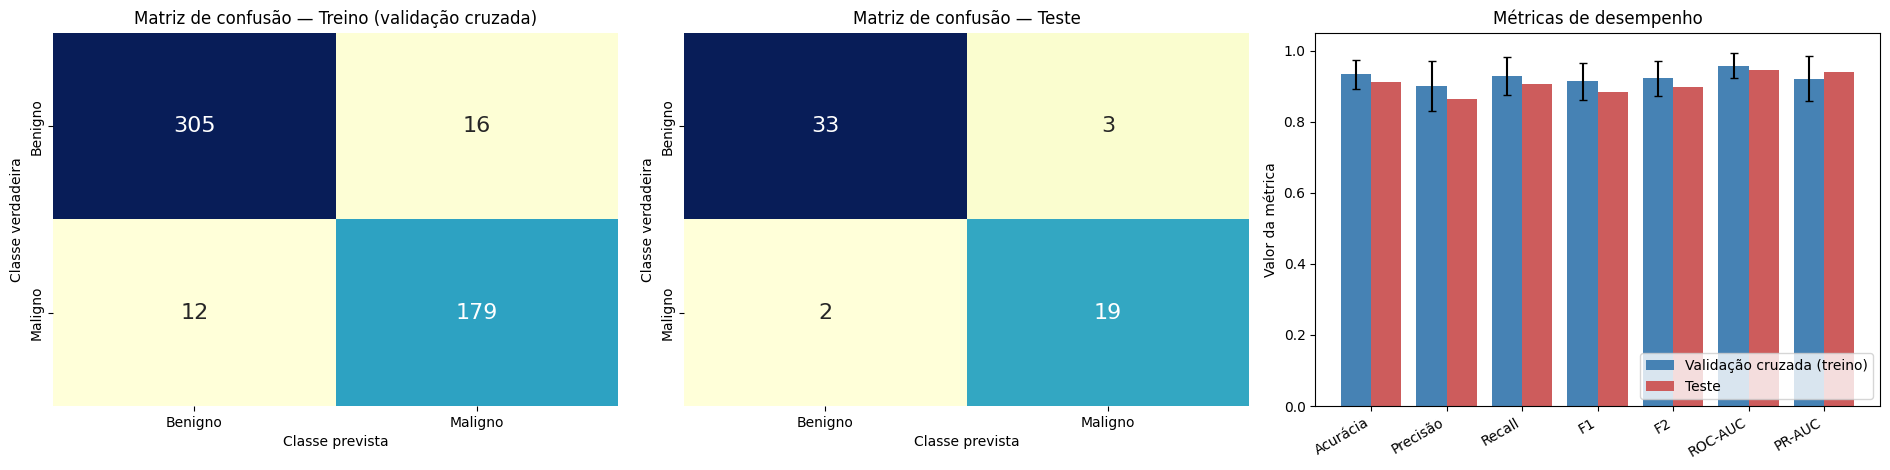

In [85]:
ordem_labels = [0, 1]
NOMES_ROTULOS = ["Benigno", "Maligno"]

# repetindo a validação cruzada
cv_comparacao = RepeatedStratifiedKFold(n_splits=10, n_repeats=3, random_state=SEMENTE_ALEATORIA + 1)

# verificando o desempenho esperado para o modelo
y_previsto_cv = cross_val_predict(melhor_arvore, X_treino, y_treino, cv=cv_estratificado)

matriz_cv = confusion_matrix(y_treino, y_previsto_cv, labels=ordem_labels)

# calculando as métricas de desempenho emc ada um dos folds
cv_resultado = cross_validate(melhor_arvore, X_treino, y_treino, cv=cv_comparacao, scoring=METRICAS)
metricas_cv = pd.DataFrame(
    {m.replace("test_", ""): v for m, v in cv_resultado.items() if m.startswith("test_")}
)

# aplicando o melhor modelo aos dados de treino
melhor_arvore.fit(X_treino, y_treino)

y_previsto_teste = melhor_arvore.predict(X_teste)
prob_teste = melhor_arvore.predict_proba(X_teste)[:, 1]

matriz_teste = confusion_matrix(y_teste, y_previsto_teste, labels=ordem_labels)

metricas_teste = pd.Series(
    {
        "Acurácia": accuracy_score(y_teste, y_previsto_teste),
        "Precisão": precision_score(y_teste, y_previsto_teste, zero_division=0),
        "Recall": recall_score(y_teste, y_previsto_teste, zero_division=0),
        "F1": f1_score(y_teste, y_previsto_teste, zero_division=0),
        "F2": fbeta_score(y_teste, y_previsto_teste, beta=2, zero_division=0),
        "ROC-AUC": roc_auc_score(y_teste, prob_teste),
        "PR-AUC": average_precision_score(y_teste, prob_teste),
    }
)

# plotando a matriz de confusão e as métricas de desempenho obtidas
fig, (eixo1, eixo2, eixo3) = plt.subplots(1, 3, figsize=(19, 4.8))

for eixo, matriz, titulo in [
    (eixo1, matriz_cv, "Treino (validação cruzada)"),
    (eixo2, matriz_teste, "Teste"),
]:
    df_conf = pd.DataFrame(matriz, NOMES_ROTULOS, NOMES_ROTULOS)
    sns.heatmap(df_conf, annot=True, annot_kws={"size": 16}, fmt="d", cmap="YlGnBu", cbar=False, ax=eixo)
    eixo.set(title=f"Matriz de confusão — {titulo}", xlabel="Classe prevista", ylabel="Classe verdadeira")

# obtendo as médias e desvios padrões das métricas de desempenho
medias_cv = metricas_cv.mean()
desvios_cv = metricas_cv.std()
nomes_cv = [NOMES_METRICAS[m] for m in medias_cv.index]

posicoes = range(len(nomes_cv))
eixo3.bar([p - 0.2 for p in posicoes], medias_cv.values, width=0.4, yerr=desvios_cv.values,
          capsize=3, label="Validação cruzada (treino)", color="steelblue")
eixo3.bar([p + 0.2 for p in posicoes], metricas_teste[nomes_cv].values, width=0.4,
          label="Teste", color="indianred")
eixo3.set_xticks(list(posicoes))
eixo3.set_xticklabels(nomes_cv, rotation=30, ha="right")
eixo3.set(ylim=(0, 1.05), ylabel="Valor da métrica", title="Métricas de desempenho")
eixo3.legend(loc="lower right")

fig.tight_layout()

# gerando uma tabela com as médias e incertezas das métricas de desempenho
tabela_metricas = pd.DataFrame(
    {
        "Validação cruzada (média ± desvio)": [
            f"{metricas_cv[m].mean():.3f} ± {metricas_cv[m].std():.3f}" for m in metricas_cv.columns
        ],
        "Teste": metricas_teste[nomes_cv].round(3).values,
    },
    index=nomes_cv,
)

tabela_metricas

#### Verificando a importância de cada atributo

In [86]:
# permutando os atributos para verificar como eles afetam F2
resultado_perm_arvore = permutation_importance(
    melhor_arvore,
    X_teste,
    y_teste,
    scoring=METRICAS["f2"],
    n_repeats=N_EMBARALHAMENTOS,
    random_state=SEMENTE_ALEATORIA,
    n_jobs=1
)

importancia_perm_arvore = pd.DataFrame(
    {
        "media": resultado_perm_arvore.importances_mean,
        "desvio": resultado_perm_arvore.importances_std
    },
    index=X_teste.columns
).sort_values("media", ascending=False)

# plotando um gráfico com os 15 atributos mais importantes
topo_arvore = importancia_perm_arvore.head(15).iloc[::-1]

fig, eixo = plt.subplots(figsize=(8, 6))

eixo.barh(
    topo_arvore.index,
    topo_arvore["media"],
    xerr=topo_arvore["desvio"],
    color="forestgreen",
    capsize=3
)

eixo.axvline(0, color="black", linewidth=0.8)

eixo.set(
    xlabel="Queda média do F2 ao embaralhar o atributo",
    ylabel="Atributo",
    title="Importância por permutação — Árvore de decisão (teste)"
)

plt.tight_layout()

plt.show()

# plotando uma tabela com os 6 atributos mais importantes
display(importancia_perm_arvore.head(6).round(4))


KeyboardInterrupt: 

In [ ]:
# verificando a importância de cada atributo com base na redução da impureza
importancia_pureza_arvore = pd.DataFrame({
    "atributo": X_treino.columns,
    "importancia": melhor_arvore.feature_importances_
}).sort_values("importancia", ascending=False)

# obtendo os 15 atributos mais importantes
topo_pureza = importancia_pureza_arvore.head(15).iloc[::-1]

# plotando um gráfico para os atributos mais importantes
fig, eixo = plt.subplots(figsize=(8, 6))

eixo.barh(
    topo_pureza["atributo"],
    topo_pureza["importancia"]
)

eixo.set_xlabel("Importância baseada na redução da impureza")
eixo.set_ylabel("Atributo")
eixo.set_title("Importância dos atributos — Árvore de decisão")

plt.tight_layout()

plt.show()

# plotando uma tabela com os 6 atributos mais importantes
display(
    importancia_pureza_arvore.head(6).round(4)
)

### Modelo Floresta aleatória

#### Floresta aleatória sem normalizador

In [ ]:
# instanciando o modelo dentro de um pipeline
pipeline_floresta_sem_norm = make_pipeline(RandomForestClassifier(random_state=SEMENTE_ALEATORIA))

# treinando o modelo
pipeline_floresta_sem_norm.fit(X_treino, y_treino)

X_verdadeiro = X_treino
y_verdadeiro = y_treino

# aplicando a validação cruzada estratificada
y_previsto_floresta_sem_norm = cross_val_predict(pipeline_floresta_sem_norm, X_verdadeiro, y_verdadeiro, cv=cv_estratificado)

In [ ]:
# plotando a matriz de confusão
matriz_conf = confusion_matrix(y_verdadeiro, y_previsto_floresta_sem_norm, labels=ordem_labels)
df_conf = pd.DataFrame(matriz_conf, ordem_labels, ordem_labels)

matriz_conf_baseline_sem_norm = sns.heatmap(df_conf, annot=True, annot_kws={"size": 16}, cmap="YlGnBu");

matriz_conf_baseline_sem_norm.set_xlabel("Classe prevista")
matriz_conf_baseline_sem_norm.set_ylabel("Classe verdadeira")
matriz_conf_baseline_sem_norm.set_title("Matriz de confusão — Floresta aleatória sem normalização")

matriz_conf_baseline_sem_norm.set_xticklabels(["Benigno", "Maligno"])
matriz_conf_baseline_sem_norm.set_yticklabels(["Benigno", "Maligno"])

In [ ]:
# avaliando algumas das melhores métricas de desempenho obtidas
acuracia_floresta_sem_norm = accuracy_score(y_verdadeiro, y_previsto_floresta_sem_norm)
f1_floresta_sem_norm = f1_score(y_verdadeiro, y_previsto_floresta_sem_norm)
f2_floresta_sem_norm = fbeta_score(y_verdadeiro, y_previsto_floresta_sem_norm, beta=2, zero_division=0)

print(f"Acurácia = {(acuracia_floresta_sem_norm*100):.2f}%")
print(f"F1_score = {f1_floresta_sem_norm*100:.2f}%")
print(f"F2_score = {f2_floresta_sem_norm*100:.2f}%")

In [ ]:
# verificando a média e desvio padrão das métricas obtidas durante a validação cruzada
resultados_floresta_sem_norm = cross_validate(pipeline_floresta_sem_norm, X_treino, y_treino, cv=NUM_FOLDS, scoring=METRICAS)

metricas_floresta_sem_norm = (
    pd.DataFrame({k.replace("test_", ""): v for k, v in resultados_floresta_sem_norm.items() if k.startswith("test_")})
    .agg(["mean", "std"])
    .T.rename(index=NOMES_METRICAS)
)

metricas_floresta_sem_norm

In [ ]:
# verificando a média das métricas de desempenho
medias_floresta_sem_norm = metricas_floresta_sem_norm["mean"]

eixo = sns.barplot(x=medias_floresta_sem_norm.index, y=medias_floresta_sem_norm.values, color="gray")

for container in eixo.containers:
    eixo.bar_label(container, fmt="%.2f", padding=2)

eixo.set(
    xlabel="Métrica",
    ylabel="Valor médio na validação cruzada",
    title="Desempenho do modelo 'Floresta aleatória' sem normalização",
    ylim=(0, 1.1),
);

#### Floresta aleatória com normalizador padrão

In [ ]:
# instanciando o modelo em um pipeline
pipeline_floresta_norm_pad = make_pipeline(StandardScaler(), RandomForestClassifier(random_state=SEMENTE_ALEATORIA))

# treinando o modelo
pipeline_floresta_norm_pad.fit(X_treino, y_treino)

X_verdadeiro = X_treino
y_verdadeiro = y_treino

# aplicando a validação cruzada estratificada
y_previsto_floresta_norm_pad = cross_val_predict(pipeline_floresta_norm_pad, X_verdadeiro, y_verdadeiro, cv=cv_estratificado)

In [ ]:
# plotando a matriz de confusão
matriz_conf = confusion_matrix(y_verdadeiro, y_previsto_floresta_norm_pad, labels=ordem_labels)
df_conf = pd.DataFrame(matriz_conf, ordem_labels, ordem_labels)

matriz_conf_baseline_sem_norm = sns.heatmap(df_conf, annot=True, annot_kws={"size": 16}, cmap="YlGnBu");

matriz_conf_baseline_sem_norm.set_xlabel("Classe prevista")
matriz_conf_baseline_sem_norm.set_ylabel("Classe verdadeira")
matriz_conf_baseline_sem_norm.set_title("Matriz de confusão — Floresta aleatória com normalizador padrão")

matriz_conf_baseline_sem_norm.set_xticklabels(["Benigno", "Maligno"])
matriz_conf_baseline_sem_norm.set_yticklabels(["Benigno", "Maligno"])

In [ ]:
# avaliando algumas das melhores métricas de desempenho obtidas
acuracia_floresta_norm_pad = accuracy_score(y_verdadeiro, y_previsto_floresta_norm_pad)
f1_floresta_norm_pad = f1_score(y_verdadeiro, y_previsto_floresta_norm_pad)
f2_floresta_norm_pad = fbeta_score(y_verdadeiro, y_previsto_floresta_norm_pad, beta=2, zero_division=0)

print(f"Acurácia = {(acuracia_floresta_norm_pad*100):.2f}%")
print(f"F1_score = {f1_floresta_norm_pad*100:.2f}%")
print(f"F2_score = {f2_floresta_norm_pad*100:.2f}%")

In [ ]:
# avaliando as médias e desvios padrões das métricas registradas durante a validação cruzada estratificada
resultados_floresta_norm_pad = cross_validate(pipeline_floresta_norm_pad, X_treino, y_treino, cv=NUM_FOLDS, scoring=METRICAS)

metricas_floresta_norm_pad = (
    pd.DataFrame({k.replace("test_", ""): v for k, v in resultados_floresta_norm_pad.items() if k.startswith("test_")})
    .agg(["mean", "std"])
    .T.rename(index=NOMES_METRICAS)
)

metricas_floresta_norm_pad

In [ ]:
# plotando um gráfico de barras para avaliar a média das métricas de desempenho
medias_floresta_norm_pad = metricas_floresta_norm_pad["mean"]

eixo = sns.barplot(x=medias_floresta_norm_pad.index, y=medias_floresta_norm_pad.values, color="gray")

for container in eixo.containers:
    eixo.bar_label(container, fmt="%.2f", padding=2)

eixo.set(
    xlabel="Métrica",
    ylabel="Valor médio na validação cruzada",
    title="Desempenho do modelo 'Floresta aleatória' com normalização padrão",
    ylim=(0, 1.1),
);

#### Floresta aleatória com normalizador pelo máximo absoluto

In [ ]:
# instanciando o modelo em um pipeline
pipeline_floresta_norm_max = make_pipeline(MaxAbsScaler(), RandomForestClassifier(random_state=SEMENTE_ALEATORIA))

# treinando o modelo
pipeline_floresta_norm_max.fit(X_treino, y_treino)

X_verdadeiro = X_treino
y_verdadeiro = y_treino

# aplicando a validação cruzada estratificada
y_previsto_floresta_norm_max = cross_val_predict(pipeline_floresta_norm_max, X_verdadeiro, y_verdadeiro, cv=cv_estratificado)

In [ ]:
# plotando a matriz de confusão
matriz_conf = confusion_matrix(y_verdadeiro, y_previsto_floresta_norm_max, labels=ordem_labels)
df_conf = pd.DataFrame(matriz_conf, ordem_labels, ordem_labels)

matriz_conf_baseline_sem_norm = sns.heatmap(df_conf, annot=True, annot_kws={"size": 16}, cmap="YlGnBu");

matriz_conf_baseline_sem_norm.set_xlabel("Classe prevista")
matriz_conf_baseline_sem_norm.set_ylabel("Classe verdadeira")
matriz_conf_baseline_sem_norm.set_title("Matriz de confusão — Floresta aleatória com normalização pelo máximo absoluto")

matriz_conf_baseline_sem_norm.set_xticklabels(["Benigno", "Maligno"])
matriz_conf_baseline_sem_norm.set_yticklabels(["Benigno", "Maligno"])

In [ ]:
# avaliando algumas das melhores métricas de desempenho obtidas durante a validação cruzada
acuracia_floresta_norm_max = accuracy_score(y_verdadeiro, y_previsto_floresta_norm_max)
f1_floresta_norm_max = f1_score(y_verdadeiro, y_previsto_floresta_norm_max)
f2_floresta_norm_max = fbeta_score(y_verdadeiro, y_previsto_floresta_norm_max, beta=2, zero_division=0)

print(f"Acurácia = {(acuracia_floresta_norm_max*100):.2f}%")
print(f"F1_score = {f1_floresta_norm_max*100:.2f}%")
print(f"F2_score = {f2_floresta_norm_max*100:.2f}%")

In [ ]:
# avaliando as médias e desvios padrões das métricas de desempenho registradas durante a validação cruzada estratificada
resultados_floresta_norm_max = cross_validate(pipeline_floresta_norm_max, X_treino, y_treino, cv=NUM_FOLDS, scoring=METRICAS)

metricas_floresta_norm_max = (
    pd.DataFrame({k.replace("test_", ""): v for k, v in resultados_floresta_norm_max.items() if k.startswith("test_")})
    .agg(["mean", "std"])
    .T.rename(index=NOMES_METRICAS)
)

metricas_floresta_norm_max

In [ ]:
# plotando um gráfico de barras com a média das métricas de desempenho
medias_floresta_norm_max = metricas_floresta_norm_max["mean"]

eixo = sns.barplot(x=medias_floresta_norm_max.index, y=medias_floresta_norm_max.values, color="gray")

for container in eixo.containers:
    eixo.bar_label(container, fmt="%.2f", padding=2)

eixo.set(
    xlabel="Métrica",
    ylabel="Valor médio na validação cruzada",
    title="Desempenho do modelo 'Floresta aleatória' com normalização pelo máximo absoluto",
    ylim=(0, 1.1),
);

#### Floresta aleatória com normalizador pelo máximo e mínimo

In [ ]:
# instanciando a árvore em um normalizador
pipeline_floresta_norm_min_max = make_pipeline(MinMaxScaler(), RandomForestClassifier(random_state=SEMENTE_ALEATORIA))

# treinando o modelo
pipeline_floresta_norm_min_max.fit(X_treino, y_treino)

X_verdadeiro = X_treino
y_verdadeiro = y_treino

# aplicando a validação cruzada estratificada
y_previsto_floresta_norm_min_max = cross_val_predict(pipeline_floresta_norm_min_max, X_verdadeiro, y_verdadeiro, cv=cv_estratificado)

In [ ]:
# plotando a matriz de confusão
matriz_conf = confusion_matrix(y_verdadeiro, y_previsto_floresta_norm_min_max, labels=ordem_labels)
df_conf = pd.DataFrame(matriz_conf, ordem_labels, ordem_labels)

matriz_conf_baseline_sem_norm = sns.heatmap(df_conf, annot=True, annot_kws={"size": 16}, cmap="YlGnBu");

matriz_conf_baseline_sem_norm.set_xlabel("Classe prevista")
matriz_conf_baseline_sem_norm.set_ylabel("Classe verdadeira")
matriz_conf_baseline_sem_norm.set_title("Matriz de confusão — Floresta aleatória com normalização pelo mínimo e máximo")

matriz_conf_baseline_sem_norm.set_xticklabels(["Benigno", "Maligno"])
matriz_conf_baseline_sem_norm.set_yticklabels(["Benigno", "Maligno"])

In [ ]:
# avaliando algumas das melhores métricas de desempenho obtidas
acuracia_floresta_norm_min_max = accuracy_score(y_verdadeiro, y_previsto_floresta_norm_min_max)
f1_floresta_norm_min_max = f1_score(y_verdadeiro, y_previsto_floresta_norm_min_max)
f2_floresta_norm_min_max = fbeta_score(y_verdadeiro, y_previsto_floresta_norm_max, beta=2, zero_division=0)

print(f"Acurácia = {(acuracia_floresta_norm_min_max*100):.2f}%")
print(f"F1_score = {f1_floresta_norm_min_max*100:.2f}%")
print(f"F2_score = {f2_floresta_norm_min_max*100:.2f}%")

In [ ]:
# avaliando a média e desvio padrão das métricas de desempenho registradas durante a validação cruzada
resultados_floresta_norm_min_max = cross_validate(pipeline_floresta_norm_min_max, X_treino, y_treino, cv=NUM_FOLDS, scoring=METRICAS)

metricas_floresta_norm_min_max = (
    pd.DataFrame({k.replace("test_", ""): v for k, v in resultados_floresta_norm_min_max.items() if k.startswith("test_")})
    .agg(["mean", "std"])
    .T.rename(index=NOMES_METRICAS)
)

metricas_floresta_norm_min_max

In [ ]:
# plotando um gráfico de barras com a média das métricas de desempenho
medias_floresta_norm_min_max = metricas_floresta_norm_min_max["mean"]

eixo = sns.barplot(x=medias_floresta_norm_min_max.index, y=medias_floresta_norm_min_max.values, color="gray")

for container in eixo.containers:
    eixo.bar_label(container, fmt="%.2f", padding=2)

eixo.set(
    xlabel="Métrica",
    ylabel="Valor médio na validação cruzada",
    title="Desempenho do modelo 'Floresta aleatória' com normalização pelo mínimo e máximo",
    ylim=(0, 1.1),
);

#### Comparando as florestas aleatórias obtidas

In [ ]:
# estabelecendo uma lista com os modelos da comparação
modelos_floresta = [
    ("Floresta Aleatória — sem normalização", y_verdadeiro, y_previsto_floresta_sem_norm),
    ("Floresta Aleatória — StandScaler", y_verdadeiro, y_previsto_floresta_norm_pad),
    ("Floresta Aleatória — MaxAbsScaler", y_verdadeiro, y_previsto_floresta_norm_max),
    ("Floresta Aleatória — MinMaxScaler", y_verdadeiro, y_previsto_floresta_norm_min_max)
]

# colocando as matrizes de confusão lado a lado
fig, eixos = plt.subplots(1, 4, figsize=(20, 5))

# plotando as matrizes de confusão
for ax, (nome, y_true, y_pred) in zip(eixos, modelos_floresta):

    matriz_conf = confusion_matrix(
        y_true,
        y_pred,
        labels=ordem_labels
    )

    df_conf = pd.DataFrame(
        matriz_conf,
        index=ordem_labels,
        columns=ordem_labels
    )

    sns.heatmap(
        df_conf,
        annot=True,
        annot_kws={"size": 14},
        cmap="YlGnBu",
        fmt="d",
        cbar=False,
        ax=ax
    )

    ax.set_title(nome, fontsize=11)
    ax.set_xlabel("Classe prevista", fontsize=10)
    ax.set_ylabel("Classe verdadeira", fontsize=10)
    ax.set_xticklabels(["Benigno", "Maligno"])
    ax.set_yticklabels(["Benigno", "Maligno"], rotation=0)

plt.tight_layout()
plt.show()

In [ ]:
# comparando as métricas de desempenho de cada modelo
pipelines_floresta = {
    "Sem normalizador": pipeline_floresta_sem_norm,
    "Normalizador padrão": pipeline_floresta_norm_pad,
    "Máximo absoluto": pipeline_floresta_norm_max,
    "Máximo e mínimo": pipeline_floresta_norm_min_max,
}

resultados_floresta = {}

for nome, pipeline in pipelines_floresta.items():
    cv_resultado = cross_validate(pipeline, X_treino, y_treino, cv=cv_estratificado, scoring=METRICAS)
    resultados_floresta[nome] = pd.DataFrame(
        {m.replace("test_", ""): v for m, v in cv_resultado.items() if m.startswith("test_")}
    )

tabela_floresta = pd.DataFrame(
    {
        nome: {NOMES_METRICAS[m]: f"{df_[m].mean():.3f} ± {df_[m].std():.3f}" for m in METRICAS}
        for nome, df_ in resultados_floresta.items()
    }
).T

tabela_floresta

#### Testando diferentes conjuntos de hiperparâmetros

In [ ]:
N_TENTATIVAS = 130
N_FOLDS = 5

cv = StratifiedKFold(
    n_splits=N_FOLDS,
    shuffle=True,
    random_state=SEMENTE_ALEATORIA
)

def objetivo_floresta(trial):
    """Função objetivo que contêm os hiperparâmetros a serem variados para o modelo Floresta Aleatória.
    
    Args:
        trial: tentativa realizada pelo Optuna

    Return: a média das métricas de desempenho obtida com os hiperparâmetros escolhidos
    """

    parametros = {
        "n_estimators": trial.suggest_int(
            "n_estimators", 200, 1000, step=100
        ),
        "criterion": trial.suggest_categorical(
            "criterion", ["gini", "entropy", "log_loss"]
        ),
        "max_depth": trial.suggest_categorical(
            "max_depth", [None, 5, 10, 15, 20, 30, 40]
        ),
        "min_samples_split": trial.suggest_int(
            "min_samples_split", 2, 30
        ),
        "min_samples_leaf": trial.suggest_int(
            "min_samples_leaf", 1, 20
        ),
        "max_features": trial.suggest_categorical(
            "max_features", ["sqrt", "log2", None]
        ),
        "class_weight": trial.suggest_categorical(
            "class_weight", [None, "balanced", "balanced_subsample"]
        ),
        "max_samples": trial.suggest_float(
            "max_samples", 0.60, 1.00
        ),
        "bootstrap": True,
        "random_state": SEMENTE_ALEATORIA,
        "n_jobs": -1
    }

    # treinando o modelo
    modelo = RandomForestClassifier(**parametros)

    # aplicando a validação cruzada e registrando as métricas de desempenho
    scores = cross_val_score(
        modelo,
        X_treino,
        y_treino,
        cv=cv_estratificado,
        scoring=METRICAS["f2"],
        n_jobs=1
    )

    return scores.mean()

# criando o estudo do Optuna
estudo_floresta = create_study(
      study_name="floresta_aleatoria_v2", direction="maximize",
      storage=f"sqlite:///{PASTA_ESTUDOS}/floresta_aleatoria_v2.db", load_if_exists=True,
      sampler=TPESampler(multivariate=True, seed=SEMENTE_ALEATORIA),
  )

concluidas = sum(t.state == TrialState.COMPLETE for t in estudo_floresta.trials)

estudo_floresta.optimize(objetivo_floresta, n_trials=max(0, NUM_TENTATIVAS - concluidas))

# Obtendo os hiperparâmetros que conceberam o melhor F2_score
print("Melhor F2 médio:", round(estudo_floresta.best_value, 4))
print("Melhores hiperparâmetros:")
print(estudo_floresta.best_params)

melhor_parametros_floresta = estudo_floresta.best_params.copy()

# instanciando o modelo com os melhores hiperparâmetros
melhor_floresta = RandomForestClassifier(
    **melhor_parametros_floresta,
    bootstrap=True,
    random_state=SEMENTE_ALEATORIA,
    n_jobs= 1
)

# treinando o modelo
melhor_floresta.fit(X_treino, y_treino)


In [ ]:
NOMES_ROTULOS = ["Benigno", "Maligno"]

# repetindo a validação cruzada
cv_comparacao = RepeatedStratifiedKFold(n_splits=10, n_repeats=3, random_state=SEMENTE_ALEATORIA + 1)

# obtendo os resultados esperados ao aplicar o modelo aos dados de treino
y_previsto_cv = cross_val_predict(melhor_floresta, X_treino, y_treino, cv=cv_estratificado)

matriz_cv = confusion_matrix(y_treino, y_previsto_cv, labels=ordem_labels)

# obtendo as métricas de desempenho de cada fold da validação cruzada
cv_resultado = cross_validate(melhor_floresta, X_treino, y_treino, cv=cv_comparacao, scoring=METRICAS)
metricas_cv = pd.DataFrame(
    {m.replace("test_", ""): v for m, v in cv_resultado.items() if m.startswith("test_")}
)

# aplicando o modelo aos dados de teste
melhor_floresta.fit(X_treino, y_treino)

y_previsto_teste = melhor_floresta.predict(X_teste)
prob_teste = melhor_floresta.predict_proba(X_teste)[:, 1]

# plotando a matriz de confusão
matriz_teste = confusion_matrix(y_teste, y_previsto_teste, labels=ordem_labels)

# obtendo as métricas de desempenho do melhor modelo
metricas_teste = pd.Series(
    {
        "Acurácia": accuracy_score(y_teste, y_previsto_teste),
        "Precisão": precision_score(y_teste, y_previsto_teste, zero_division=0),
        "Recall": recall_score(y_teste, y_previsto_teste, zero_division=0),
        "F1": f1_score(y_teste, y_previsto_teste, zero_division=0),
        "F2": fbeta_score(y_teste, y_previsto_teste, beta=2, zero_division=0),
        "ROC-AUC": roc_auc_score(y_teste, prob_teste),
        "PR-AUC": average_precision_score(y_teste, prob_teste),
    }
)

# plotando a matriz de confusão
fig, (eixo1, eixo2, eixo3) = plt.subplots(1, 3, figsize=(19, 4.8))

for eixo, matriz, titulo in [
    (eixo1, matriz_cv, "Treino (validação cruzada)"),
    (eixo2, matriz_teste, "Teste"),
]:
    df_conf = pd.DataFrame(matriz, NOMES_ROTULOS, NOMES_ROTULOS)
    sns.heatmap(df_conf, annot=True, annot_kws={"size": 16}, fmt="d", cmap="YlGnBu", cbar=False, ax=eixo)
    eixo.set(title=f"Matriz de confusão — {titulo}", xlabel="Classe prevista", ylabel="Classe verdadeira")

# gerando uma tabela com a média das métricas de desempenho
medias_cv = metricas_cv.mean()
desvios_cv = metricas_cv.std()
nomes_cv = [NOMES_METRICAS[m] for m in medias_cv.index]

posicoes = range(len(nomes_cv))
eixo3.bar([p - 0.2 for p in posicoes], medias_cv.values, width=0.4, yerr=desvios_cv.values,
          capsize=3, label="Validação cruzada (treino)", color="steelblue")
eixo3.bar([p + 0.2 for p in posicoes], metricas_teste[nomes_cv].values, width=0.4,
          label="Teste", color="indianred")
eixo3.set_xticks(list(posicoes))
eixo3.set_xticklabels(nomes_cv, rotation=30, ha="right")
eixo3.set(ylim=(0, 1.05), ylabel="Valor da métrica", title="Métricas de desempenho")
eixo3.legend(loc="lower right")

fig.tight_layout()

tabela_metricas = pd.DataFrame(
    {
        "Validação cruzada (média ± desvio)": [
            f"{metricas_cv[m].mean():.3f} ± {metricas_cv[m].std():.3f}" for m in metricas_cv.columns
        ],
        "Teste": metricas_teste[nomes_cv].round(3).values,
    },
    index=nomes_cv,
)

tabela_metricas

#### Verificando a importância de cada atributo

In [ ]:
# quantidade de vezes que os atributos serão embaralhados
N_EMBARALHAMENTOS = 20

# avaliando a importância de cada atributo ao permutá-los
resultado_perm_floresta = permutation_importance(
    melhor_floresta,
    X_teste,
    y_teste,
    scoring=METRICAS["f2"],
    n_repeats=N_EMBARALHAMENTOS,
    random_state=SEMENTE_ALEATORIA,
    n_jobs=1
)

importancia_perm_floresta = pd.DataFrame(
    {
        "media": resultado_perm_floresta.importances_mean,
        "desvio": resultado_perm_floresta.importances_std
    },
    index=X_teste.columns
).sort_values("media", ascending=False)

# plotando um gráfico com os 15 atributos eleitos como mais importantes
topo_floresta = importancia_perm_floresta.head(15).iloc[::-1]

fig, eixo = plt.subplots(figsize=(8, 6))

eixo.barh(
    topo_floresta.index,
    topo_floresta["media"],
    xerr=topo_floresta["desvio"],
    color="forestgreen",
    capsize=3
)

eixo.axvline(0, color="black", linewidth=0.8)

eixo.set(
    xlabel="Queda média do F2 ao embaralhar o atributo",
    ylabel="Atributo",
    title="Importância por permutação — Floresta aleatória (teste)"
)

plt.tight_layout()

plt.show()

# gerando uma tabela com os 6 atributos mais importantes e suas médias de contribuição
display(importancia_perm_floresta.head(6).round(4))

In [ ]:
# avaliando a importância de cada atributo de acordo com seu papel na redução da impureza de cada vértice
importancia_pureza_floresta = pd.DataFrame({
    "atributo": X_treino.columns,
    "importancia": melhor_floresta.feature_importances_
}).sort_values("importancia", ascending=False)

# obtendo os 15 atributos de maior relevância para reduzir a impureza
topo_pureza = importancia_pureza_floresta.head(15).iloc[::-1]

# plotando um gráfico de barras com a contribuição de cada atributo
fig, eixo = plt.subplots(figsize=(8, 6))

eixo.barh(
    topo_pureza["atributo"],
    topo_pureza["importancia"]
)

eixo.set_xlabel("Importância baseada na redução da impureza")
eixo.set_ylabel("Atributo")
eixo.set_title("Importância dos atributos — Floresta aleatória")

plt.tight_layout()

plt.show()

# obtendo uma tabela com a importância de cada atributo
display(
    importancia_pureza_floresta.head(6).round(4)
)

In [ ]:
# ordenando todos os atributos de acordo com sua contribuição na redução da impureza
importancias_floresta = pd.DataFrame({
    "atributo": X_treino.columns,
    "importancia": melhor_floresta.feature_importances_
}).sort_values("importancia", ascending=False)

display(importancias_floresta.head(15).round(4))

### Modelo Regressão logística

#### Regressão logística sem normalização

In [ ]:
# instanciando o modelo em um pipeline
pipeline_rlog_sem_norm = make_pipeline(LogisticRegression(max_iter=10000, random_state=SEMENTE_ALEATORIA))

# treinando o modelo
pipeline_rlog_sem_norm.fit(X_treino, y_treino)

X_verdadeiro = X_treino
y_verdadeiro = y_treino

# aplicando a validação cruzada estratificada
y_previsto_rlog_sem_norm = cross_val_predict(pipeline_rlog_sem_norm, X_verdadeiro, y_verdadeiro, cv=cv_estratificado)

In [ ]:
# plotando a matriz de confusão
matriz_conf = confusion_matrix(y_verdadeiro, y_previsto_rlog_sem_norm, labels=ordem_labels)
df_conf = pd.DataFrame(matriz_conf, ordem_labels, ordem_labels)

matriz_conf_baseline_sem_norm = sns.heatmap(df_conf, annot=True, annot_kws={"size": 16}, cmap="YlGnBu");

matriz_conf_baseline_sem_norm.set_xlabel("Classe prevista")
matriz_conf_baseline_sem_norm.set_ylabel("Classe verdadeira")
matriz_conf_baseline_sem_norm.set_title("Matriz de confusão — Regressão Logística sem normalização")

matriz_conf_baseline_sem_norm.set_xticklabels(["Benigno", "Maligno"])
matriz_conf_baseline_sem_norm.set_yticklabels(["Benigno", "Maligno"])

In [ ]:
# verificando algumas das melhores métricas de desempenho obtidas durante a validação cruzada
acuracia_rlog_sem_norm = accuracy_score(y_verdadeiro, y_previsto_rlog_sem_norm)
f1_rlog_sem_norm = f1_score(y_verdadeiro, y_previsto_rlog_sem_norm)
f2_rlog_sem_norm = fbeta_score(y_verdadeiro, y_previsto_rlog_sem_norm, beta=2, zero_division=0)

print(f"Acurácia = {(acuracia_rlog_sem_norm*100):.2f}%")
print(f"F1_score = {f1_rlog_sem_norm*100:.2f}%")
print(f"F2_score = {f2_rlog_sem_norm*100:.2f}%")

In [ ]:
# avaliando as probabilidades associadas a cada escolha do modelo
prob_cv = cross_val_predict(pipeline_rlog_sem_norm, X_treino, y_treino, cv=cv_estratificado, method="predict_proba")

for real, previsto, prob in zip(y_treino[:10], y_previsto_rlog_sem_norm[:10], prob_cv[:10]):
    print(f"Era {real} e previu {previsto}. Prob. de ser {previsto}: {prob[ordem_labels.index(previsto)]:.3f}.")

In [ ]:
# probabilidades previstas de ser maligno
probabilidades = cross_val_predict(
    pipeline_rlog_sem_norm, X_treino, y_treino, cv=cv_estratificado, method="predict_proba"
)[:, 1]

df_prob = pd.DataFrame({"probabilidade": probabilidades, "classe": pd.Series(y_treino).map({0: "benigno", 1: "maligno"})})

eixo = sns.histplot(df_prob, x="probabilidade", hue="classe", bins=20, multiple="stack", linewidth=0)
eixo.axvline(0.5, color="black", linestyle="--")
eixo.set(
    xlabel="Probabilidade prevista de ser maligno",
    ylabel="Número de exemplos",
    title="Regressão logística sem normalização: probabilidades na validação cruzada",
);

In [ ]:
# obtendo as médias e desvios padrões das métricas de desempenho registradas durante a validação cruzada
resultados_rlog_sem_norm = cross_validate(pipeline_rlog_sem_norm, X_treino, y_treino, cv=NUM_FOLDS, scoring=METRICAS)

metricas_rlog_sem_norm = (
    pd.DataFrame({k.replace("test_", ""): v for k, v in resultados_rlog_sem_norm.items() if k.startswith("test_")})
    .agg(["mean", "std"])
    .T.rename(index=NOMES_METRICAS)
)

metricas_rlog_sem_norm

In [ ]:
# plotando um gráfico de barras com as médias das métricas de desempenho
medias_rlog_sem_norm = metricas_rlog_sem_norm["mean"]

eixo = sns.barplot(x=medias_rlog_sem_norm.index, y=medias_rlog_sem_norm.values, color="gray")

for container in eixo.containers:
    eixo.bar_label(container, fmt="%.2f", padding=2)

eixo.set(
    xlabel="Métrica",
    ylabel="Valor médio na validação cruzada",
    title="Desempenho do modelo 'Regressão logística' sem normalização",
    ylim=(0, 1.1),
);

#### Regressão logística com normalização padrão

In [ ]:
# instanciando o modelo em um pipeline
pipeline_rlog_norm_pad = make_pipeline(StandardScaler(), LogisticRegression(max_iter=10000, random_state=SEMENTE_ALEATORIA))

# treinando o modelo
pipeline_rlog_norm_pad.fit(X_treino, y_treino)

X_verdadeiro = X_treino
y_verdadeiro = y_treino

# aplicando a validação cruzada estratificada
y_previsto_rlog_norm_pad = cross_val_predict(pipeline_rlog_norm_pad, X_verdadeiro, y_verdadeiro, cv=cv_estratificado)

In [ ]:
# plotando a matriz de confusão
matriz_conf = confusion_matrix(y_verdadeiro, y_previsto_rlog_norm_pad, labels=ordem_labels)
df_conf = pd.DataFrame(matriz_conf, ordem_labels, ordem_labels)

matriz_conf_baseline_norm_pad = sns.heatmap(df_conf, annot=True, annot_kws={"size": 16}, cmap="YlGnBu");

matriz_conf_baseline_norm_pad.set_xlabel("Classe prevista")
matriz_conf_baseline_norm_pad.set_ylabel("Classe verdadeira")
matriz_conf_baseline_norm_pad.set_title("Matriz de confusão — Regressão Logística com normalização padrão")

matriz_conf_baseline_norm_pad.set_xticklabels(["Benigno", "Maligno"])
matriz_conf_baseline_norm_pad.set_yticklabels(["Benigno", "Maligno"])

In [ ]:
# verificando algumas das melhores métricas de desempenho obtidas durante a validação cruzada
acuracia_rlog_norm_pad = accuracy_score(y_verdadeiro, y_previsto_rlog_norm_pad)
f1_rlog_norm_pad = f1_score(y_verdadeiro, y_previsto_rlog_norm_pad)
f2_rlog_norm_pad = fbeta_score(y_verdadeiro, y_previsto_floresta_norm_pad, beta=2, zero_division=0)

print(f"Acurácia = {(acuracia_rlog_norm_pad*100):.2f}%")
print(f"F1_score = {f1_rlog_norm_pad*100:.2f}%")
print(f"F2_score = {f2_rlog_norm_pad*100:.2f}%")

In [ ]:
# avaliando as probabilidades associadas a cada escolha do modelo
prob_cv = cross_val_predict(pipeline_rlog_norm_pad, X_treino, y_treino, cv=cv_estratificado, method="predict_proba")

for real, previsto, prob in zip(y_treino[:10], y_previsto_rlog_norm_pad[:10], prob_cv[:10]):
    print(f"Era {real} e previu {previsto}. Prob. de ser {previsto}: {prob[ordem_labels.index(previsto)]:.3f}.")

In [ ]:
# plotando um gráfico com as probabilidades previstas de ser maligno
probabilidades = cross_val_predict(
    pipeline_rlog_norm_pad, X_treino, y_treino, cv=cv_estratificado, method="predict_proba"
)[:, 1]

df_prob = pd.DataFrame({"probabilidade": probabilidades, "classe": pd.Series(y_treino).map({0: "benigno", 1: "maligno"})})

eixo = sns.histplot(df_prob, x="probabilidade", hue="classe", bins=20, multiple="stack", linewidth=0)
eixo.axvline(0.5, color="black", linestyle="--")
eixo.set(
    xlabel="Probabilidade prevista de ser maligno",
    ylabel="Número de exemplos",
    title="Regressão logística normalização padrão: probabilidades na validação cruzada",
);

In [ ]:
# avaliando as médias e desvios padrões das métricas registradas pela validação cruzada
resultados_rlog_norm_pad = cross_validate(pipeline_rlog_norm_pad, X_treino, y_treino, cv=NUM_FOLDS, scoring=METRICAS)

metricas_rlog_norm_pad = (
    pd.DataFrame({k.replace("test_", ""): v for k, v in resultados_rlog_norm_pad.items() if k.startswith("test_")})
    .agg(["mean", "std"])
    .T.rename(index=NOMES_METRICAS)
)

metricas_rlog_norm_pad

In [ ]:
# plotando um gráfico de barras com as médias das métricas de desempenho
medias_rlog_norm_pad = metricas_rlog_norm_pad["mean"]

eixo = sns.barplot(x=medias_rlog_norm_pad.index, y=medias_rlog_norm_pad.values, color="gray")

for container in eixo.containers:
    eixo.bar_label(container, fmt="%.2f", padding=2)

eixo.set(
    xlabel="Métrica",
    ylabel="Valor médio na validação cruzada",
    title="Desempenho do modelo 'Regressão logística' com normalização padrão",
    ylim=(0, 1.1),
);

#### Regressão logística com normalização pelo máximo absoluto

In [ ]:
# instanciando o modelo
pipeline_rlog_norm_max = make_pipeline(MaxAbsScaler(), LogisticRegression(max_iter=10000, random_state=SEMENTE_ALEATORIA))

# treinando o modelo
pipeline_rlog_norm_max.fit(X_treino, y_treino)

X_verdadeiro = X_treino
y_verdadeiro = y_treino

# aplicando a validação cruzada estratificada
y_previsto_rlog_norm_max = cross_val_predict(pipeline_rlog_norm_max, X_verdadeiro, y_verdadeiro, cv=cv_estratificado)

In [ ]:
# plotando a matriz de confusão
matriz_conf = confusion_matrix(y_verdadeiro, y_previsto_rlog_norm_max, labels=ordem_labels)
df_conf = pd.DataFrame(matriz_conf, ordem_labels, ordem_labels)

matriz_conf_baseline_norm_max = sns.heatmap(df_conf, annot=True, annot_kws={"size": 16}, cmap="YlGnBu");

matriz_conf_baseline_norm_max.set_xlabel("Classe prevista")
matriz_conf_baseline_norm_max.set_ylabel("Classe verdadeira")
matriz_conf_baseline_norm_max.set_title("Matriz de confusão — Regressão Logística com normalização pelo máximo absoluto")

matriz_conf_baseline_norm_max.set_xticklabels(["Benigno", "Maligno"])
matriz_conf_baseline_norm_max.set_yticklabels(["Benigno", "Maligno"])

In [ ]:
# verificando algumas das melhores métricas de desempenho obtidas durante a validação cruzada
acuracia_rlog_norm_max = accuracy_score(y_verdadeiro, y_previsto_rlog_norm_max)
f1_rlog_norm_max = f1_score(y_verdadeiro, y_previsto_rlog_norm_max)
f2_rlog_norm_max = fbeta_score(y_verdadeiro, y_previsto_floresta_norm_max, beta=2, zero_division=0)

print(f"Acurácia = {(acuracia_rlog_norm_max*100):.2f}%")
print(f"F1_score = {f1_rlog_norm_max*100:.2f}%")
print(f"F2_score = {f2_rlog_norm_max*100:.2f}%")

In [ ]:
# obtendo as probabilidades associadas a cada predição feita pelo modelo
prob_cv = cross_val_predict(pipeline_rlog_norm_max, X_treino, y_treino, cv=cv_estratificado, method="predict_proba")

for real, previsto, prob in zip(y_treino[:10], y_previsto_rlog_norm_max[:10], prob_cv[:10]):
    print(f"Era {real} e previu {previsto}. Prob. de ser {previsto}: {prob[ordem_labels.index(previsto)]:.3f}.")

In [ ]:
# plotando um gráfico de barras com as probabilidades previstas de que um tumor seja maligno
probabilidades = cross_val_predict(
    pipeline_rlog_norm_max, X_treino, y_treino, cv=cv_estratificado, method="predict_proba"
)[:, 1]

df_prob = pd.DataFrame({"probabilidade": probabilidades, "classe": pd.Series(y_treino).map({0: "benigno", 1: "maligno"})})

eixo = sns.histplot(df_prob, x="probabilidade", hue="classe", bins=20, multiple="stack", linewidth=0)
eixo.axvline(0.5, color="black", linestyle="--")
eixo.set(
    xlabel="Probabilidade prevista de ser maligno",
    ylabel="Número de exemplos",
    title="Regressão logística normalização pelo máximo absoluto: probabilidades na validação cruzada",
);

In [ ]:
# obtendo as médias e desvios padrões das métricas de desempenho registradas durante a validação cruzada
resultados_rlog_norm_max = cross_validate(pipeline_rlog_norm_max, X_treino, y_treino, cv=NUM_FOLDS, scoring=METRICAS)

metricas_rlog_norm_max = (
    pd.DataFrame({k.replace("test_", ""): v for k, v in resultados_rlog_norm_max.items() if k.startswith("test_")})
    .agg(["mean", "std"])
    .T.rename(index=NOMES_METRICAS)
)

metricas_rlog_norm_max

In [ ]:
# plotando um gráfico de barras com as médias das métricas de desempenho
medias_rlog_norm_max = metricas_rlog_norm_max["mean"]

eixo = sns.barplot(x=medias_rlog_norm_max.index, y=medias_rlog_norm_max.values, color="gray")

for container in eixo.containers:
    eixo.bar_label(container, fmt="%.2f", padding=2)

eixo.set(
    xlabel="Métrica",
    ylabel="Valor médio na validação cruzada",
    title="Desempenho do modelo 'Regressão logística' com normalização padrão",
    ylim=(0, 1.1),
);

#### Regressão logística com normalização pelo máximo e mínimo

In [ ]:
# instanciando o modelo em um pipeline
pipeline_rlog_norm_min_max = make_pipeline(MinMaxScaler(), LogisticRegression(max_iter=10000, random_state=SEMENTE_ALEATORIA))

# treinando o modelo
pipeline_rlog_norm_min_max.fit(X_treino, y_treino)

X_verdadeiro = X_treino
y_verdadeiro = y_treino

# aplicando a validação cruzada estratificada
y_previsto_rlog_norm_min_max = cross_val_predict(pipeline_rlog_norm_min_max, X_verdadeiro, y_verdadeiro, cv=cv_estratificado)

In [ ]:
# plotando a matriz de confusão
matriz_conf = confusion_matrix(y_verdadeiro, y_previsto_rlog_norm_min_max, labels=ordem_labels)
df_conf = pd.DataFrame(matriz_conf, ordem_labels, ordem_labels)

matriz_conf_baseline_norm_min_max = sns.heatmap(df_conf, annot=True, annot_kws={"size": 16}, cmap="YlGnBu");

matriz_conf_baseline_norm_min_max.set_xlabel("Classe prevista")
matriz_conf_baseline_norm_min_max.set_ylabel("Classe verdadeira")
matriz_conf_baseline_norm_min_max.set_title("Matriz de confusão — Regressão Logística com normalização pelo mínimo e máximo")

matriz_conf_baseline_norm_min_max.set_xticklabels(["Benigno", "Maligno"])
matriz_conf_baseline_norm_min_max.set_yticklabels(["Benigno", "Maligno"])

In [ ]:
# verificando algumas das melhores métricas de desempenho obtidas durante a validação cruzada
acuracia_rlog_norm_min_max = accuracy_score(y_verdadeiro, y_previsto_rlog_norm_min_max)
f1_rlog_norm_min_max = f1_score(y_verdadeiro, y_previsto_rlog_norm_min_max)
f2_rlog_norm_min_max = fbeta_score(y_verdadeiro, y_previsto_floresta_norm_min_max, beta=2, zero_division=0)

print(f"Acurácia = {(acuracia_rlog_norm_min_max*100):.2f}%")
print(f"F1_score = {f1_rlog_norm_min_max*100:.2f}%")
print(f"F2_score = {f2_rlog_norm_min_max*100:.2f}%")

In [ ]:
# obtendo as probabilidades associadas às previsões feitas pelo modelo
prob_cv = cross_val_predict(pipeline_rlog_norm_min_max, X_treino, y_treino, cv=cv_estratificado, method="predict_proba")

for real, previsto, prob in zip(y_treino[:10], y_previsto_rlog_norm_min_max[:10], prob_cv[:10]):
    print(f"Era {real} e previu {previsto}. Prob. de ser {previsto}: {prob[ordem_labels.index(previsto)]:.3f}.")

In [ ]:
# plotando um gráfico de barras com probabilidades previstas de que um tumor seja maligno
probabilidades = cross_val_predict(
    pipeline_rlog_norm_min_max, X_treino, y_treino, cv=cv_estratificado, method="predict_proba"
)[:, 1]

df_prob = pd.DataFrame({"probabilidade": probabilidades, "classe": pd.Series(y_treino).map({0: "benigno", 1: "maligno"})})

eixo = sns.histplot(df_prob, x="probabilidade", hue="classe", bins=20, multiple="stack", linewidth=0)
eixo.axvline(0.5, color="black", linestyle="--")
eixo.set(
    xlabel="Probabilidade prevista de ser maligno",
    ylabel="Número de exemplos",
    title="Regressão logística normalização pelo máximo e mínimo: probabilidades na validação cruzada",
);

In [ ]:
# obtendo as médias e desvios padrões das métricas de desemepenho registradas durante a validação cruzada
resultados_rlog_norm_min_max = cross_validate(pipeline_rlog_norm_min_max, X_treino, y_treino, cv=NUM_FOLDS, scoring=METRICAS)

metricas_rlog_norm_min_max = (
    pd.DataFrame({k.replace("test_", ""): v for k, v in resultados_rlog_norm_min_max.items() if k.startswith("test_")})
    .agg(["mean", "std"])
    .T.rename(index=NOMES_METRICAS)
)

metricas_rlog_norm_min_max

In [ ]:
# plotando um gráfico de barras com a média da smétricas de desempenho
medias_rlog_norm_min_max = metricas_rlog_norm_min_max["mean"]

eixo = sns.barplot(x=medias_rlog_norm_min_max.index, y=medias_rlog_norm_min_max.values, color="gray")

for container in eixo.containers:
    eixo.bar_label(container, fmt="%.2f", padding=2)

eixo.set(
    xlabel="Métrica",
    ylabel="Valor médio na validação cruzada",
    title="Desempenho do modelo 'Regressão logística' com normalização pelo mínimo e máximo",
    ylim=(0, 1.1),
);

#### Comparando as regressões logísticas construídas

In [ ]:
# criando uma lista com as regressões a serem comparadas
modelos_rlog = [
    ("Regressão Logística — sem normalização", y_verdadeiro, y_previsto_rlog_sem_norm),
    ("Regressão Logística — StandardScaler", y_verdadeiro, y_previsto_rlog_norm_pad),
    ("Regressão Logística — MaxAbsScaler", y_verdadeiro, y_previsto_rlog_norm_max),
    ("Regressão Logística — MinMaxScaler", y_verdadeiro, y_previsto_rlog_norm_min_max)
]

# colocando as quatro matrizes de confusão lado a lado
fig, eixos = plt.subplots(1, 4, figsize=(20, 5))

# plotando as matrizes de desempenho
for ax, (nome, y_true, y_pred) in zip(eixos, modelos_rlog):


    matriz_conf = confusion_matrix(y_true, y_pred,labels=ordem_labels)

    df_conf = pd.DataFrame(matriz_conf, index=ordem_labels, columns=ordem_labels)

    sns.heatmap(
        df_conf,
        annot=True,
        annot_kws={"size": 14},
        cmap="YlGnBu",
        fmt="d",
        cbar=False,
        ax=ax
    )

    ax.set_title(nome, fontsize=11)
    ax.set_xlabel("Classe prevista", fontsize=10)
    ax.set_ylabel("Classe verdadeira", fontsize=10)
    ax.set_xticklabels(["Benigno", "Maligno"])
    ax.set_yticklabels(["Benigno", "Maligno"], rotation=0)

plt.tight_layout()
plt.show()

In [ ]:
# comparando as métricas de desempenho de cada uma das regressões logísticas
pipelines_rlog = {
    "Sem normalizador": pipeline_rlog_sem_norm,
    "Normalizador padrão": pipeline_rlog_norm_pad,
    "Máximo absoluto": pipeline_rlog_norm_max,
    "Máximo e mínimo": pipeline_rlog_norm_min_max,
}

resultados_rlog = {}

for nome, pipeline in pipelines_rlog.items():
    cv_resultado = cross_validate(pipeline, X_treino, y_treino, cv=cv_estratificado, scoring=METRICAS)
    resultados_rlog[nome] = pd.DataFrame(
        {m.replace("test_", ""): v for m, v in cv_resultado.items() if m.startswith("test_")}
    )

# tabela: média ± desvio padrão de cada métrica
tabela_rlog = pd.DataFrame(
    {
        nome: {NOMES_METRICAS[m]: f"{df_[m].mean():.3f} ± {df_[m].std():.3f}" for m in METRICAS}
        for nome, df_ in resultados_rlog.items()
    }
).T

tabela_rlog

#### Testando diferentes conjuntos de hiperparâmetros

In [ ]:

N_TENTATIVAS = 130
N_FOLDS = 5

cv = StratifiedKFold(
    n_splits=N_FOLDS,
    shuffle=True,
    random_state=SEMENTE_ALEATORIA
)

def objetivo_regressao_logistica(trial):
    """Função objetivo para variação dos hiperparâmetros de uma regressão logística com Optuna.
    
    Args:
        trial: tentativa realizada pelo Optuna

    Return: média das métricas de desempenho do modelo construído
    """

    solver = trial.suggest_categorical(
        "solver", ["liblinear", "lbfgs"]
    )

    # Combinações compatíveis com cada solver
    if solver == "liblinear":
        penalty = trial.suggest_categorical(
            "penalty", ["l1", "l2"]
        )
    else:
        penalty = "l2"

    parametros = {
        "C": trial.suggest_float(
            "C", 1e-4, 1e3, log=True
        ),
        "penalty": penalty,
        "solver": solver,
        "class_weight": trial.suggest_categorical(
            "class_weight", [None, "balanced"]
        ),
        "max_iter": 5000,
        "random_state": SEMENTE_ALEATORIA
    }

    # instanciando o modelo
    modelo = Pipeline([
        ("scaler", StandardScaler()),
        ("classificador", LogisticRegression(**parametros))
    ])

    # obtendo as métricas de desempenho
    scores = cross_val_score(
        modelo,
        X_treino,
        y_treino,
        cv=cv_estratificado,
        scoring=METRICAS["f2"],
        n_jobs=4
    )

    return scores.mean()

# criando um estudo do optuna
estudo_logistica = create_study(
    study_name="losgistica_aleatoria_f2_v1", 
    direction="maximize",
    storage="sqlite:///regressao_logistica_f2_v1.db",
    load_if_exists=True,
    sampler=TPESampler(multivariate=True, seed=SEMENTE_ALEATORIA),
) 
concluidas = sum(t.state == TrialState.COMPLETE for t in estudo_logistica.trials)

estudo_logistica.optimize(
  objetivo_regressao_logistica,
  n_trials=max(0, NUM_TENTATIVAS - concluidas)
)

# imprimindo os hiperparâmetros que registraram o melhor F2
print("Melhor F2 médio:", round(estudo_logistica.best_value, 4))
print("Melhores hiperparâmetros:")
print(estudo_logistica.best_params)

In [ ]:
# resgatando os melhores hiperparâmetros
melhores_parametros = estudo_logistica.best_params.copy()

# instanciando o melhor modelo
melhor_logistica = Pipeline([
    ("scaler", StandardScaler()),
    ("classificador", LogisticRegression(
        **melhores_parametros,
        max_iter=5000,
        random_state=SEMENTE_ALEATORIA
    ))
])

# treinando o melhor modelo
melhor_logistica.fit(X_treino, y_treino)

In [ ]:
NOMES_ROTULOS = ["Benigno", "Maligno"]

# repetindo a validação cruzada
cv_comparacao = RepeatedStratifiedKFold(n_splits=10, n_repeats=3, random_state=SEMENTE_ALEATORIA + 1)

# verificando o desempenho esperado para o modelo nos dados de treino
y_previsto_cv = cross_val_predict(melhor_logistica, X_treino, y_treino, cv=cv_estratificado)

matriz_cv = confusion_matrix(y_treino, y_previsto_cv, labels=ordem_labels)

# obtendo as métricas de desempenho registradas em cada fold
cv_resultado = cross_validate(melhor_logistica, X_treino, y_treino, cv=cv_comparacao, scoring=METRICAS)
metricas_cv = pd.DataFrame(
    {m.replace("test_", ""): v for m, v in cv_resultado.items() if m.startswith("test_")}
)

# aplicando o modelo aos dados de teste
melhor_logistica.fit(X_treino, y_treino)

y_previsto_teste = melhor_logistica.predict(X_teste)
prob_teste = melhor_logistica.predict_proba(X_teste)[:, 1]

matriz_teste = confusion_matrix(y_teste, y_previsto_teste, labels=ordem_labels)

# obtendo as métricas de desempenho
metricas_teste = pd.Series(
    {
        "Acurácia": accuracy_score(y_teste, y_previsto_teste),
        "Precisão": precision_score(y_teste, y_previsto_teste, zero_division=0),
        "Recall": recall_score(y_teste, y_previsto_teste, zero_division=0),
        "F1": f1_score(y_teste, y_previsto_teste, zero_division=0),
        "F2": fbeta_score(y_teste, y_previsto_teste, beta=2, zero_division=0),
        "ROC-AUC": roc_auc_score(y_teste, prob_teste),
        "PR-AUC": average_precision_score(y_teste, prob_teste),
    }
)

# plotando a matriz de confusão
fig, (eixo1, eixo2, eixo3) = plt.subplots(1, 3, figsize=(19, 4.8))

for eixo, matriz, titulo in [
    (eixo1, matriz_cv, "Treino (validação cruzada)"),
    (eixo2, matriz_teste, "Teste"),
]:
    df_conf = pd.DataFrame(matriz, NOMES_ROTULOS, NOMES_ROTULOS)
    sns.heatmap(df_conf, annot=True, annot_kws={"size": 16}, fmt="d", cmap="YlGnBu", cbar=False, ax=eixo)
    eixo.set(title=f"Matriz de confusão — {titulo}", xlabel="Classe prevista", ylabel="Classe verdadeira")

# obtendo as métricas de desempenho após a validação cruzada
medias_cv = metricas_cv.mean()
desvios_cv = metricas_cv.std()
nomes_cv = [NOMES_METRICAS[m] for m in medias_cv.index]

posicoes = range(len(nomes_cv))
eixo3.bar([p - 0.2 for p in posicoes], medias_cv.values, width=0.4, yerr=desvios_cv.values,
          capsize=3, label="Validação cruzada (treino)", color="steelblue")
eixo3.bar([p + 0.2 for p in posicoes], metricas_teste[nomes_cv].values, width=0.4,
          label="Teste", color="indianred")
eixo3.set_xticks(list(posicoes))
eixo3.set_xticklabels(nomes_cv, rotation=30, ha="right")
eixo3.set(ylim=(0, 1.05), ylabel="Valor da métrica", title="Métricas de desempenho")
eixo3.legend(loc="lower right")

fig.tight_layout()

# gerando uma tabela com as métricas de desempenho do modelo
tabela_metricas = pd.DataFrame(
    {
        "Validação cruzada (média ± desvio)": [
            f"{metricas_cv[m].mean():.3f} ± {metricas_cv[m].std():.3f}" for m in metricas_cv.columns
        ],
        "Teste": metricas_teste[nomes_cv].round(3).values,
    },
    index=nomes_cv,
)

tabela_metricas

#### Verificando a importância de cada atributo

In [ ]:
# quantidade de embaralhamentos aos quais os atributos serão sujeitos
N_EMBARALHAMENTOS = 20

# avaliando o desemepnho do modelo ao permutar os atributos
resultado_perm_logistica = permutation_importance(
    melhor_logistica,
    X_teste,
    y_teste,
    scoring=METRICAS["f2"],
    n_repeats=N_EMBARALHAMENTOS,
    random_state=SEMENTE_ALEATORIA,
    n_jobs=1
)

importancia_perm_logistica = pd.DataFrame(
    {
        "media": resultado_perm_logistica.importances_mean,
        "desvio": resultado_perm_logistica.importances_std
    },
    index=X_teste.columns
).sort_values("media", ascending=False)

# plotando um gráfico de barras com os 15 atributos de maior relevância durante a permutação
topo_logistica = importancia_perm_logistica.head(15).iloc[::-1]

fig, eixo = plt.subplots(figsize=(8, 6))

eixo.barh(
    topo_logistica.index,
    topo_logistica["media"],
    xerr=topo_logistica["desvio"],
    color="forestgreen",
    capsize=3
)

eixo.axvline(0, color="black", linewidth=0.8)

eixo.set(
    xlabel="Queda média do F2 ao embaralhar o atributo",
    ylabel="Atributo",
    title="Importância por permutação — Regressão Logística (teste)"
)

plt.tight_layout()

plt.show()

# printando uma tabela com os 6 atributos de maior contribuição e sua importância
display(importancia_perm_logistica.head(6).round(4))

In [ ]:
# obtendo os coeficientes da melhor regressão logística
modelo_lr = melhor_logistica.named_steps["classificador"]

coeficientes = pd.DataFrame({
    "Atributo": X_treino.columns,
    "Coeficiente": modelo_lr.coef_[0]
})

# ordenando os atributos do modelo de acordo com os coeficientes da regressão
coeficientes = coeficientes.sort_values("Coeficiente", ascending=True)

cores = [
    "steelblue" if valor < 0 else "firebrick"
    for valor in coeficientes["Coeficiente"]
]

# plotando um gráfico com a contribuição de cada atributo de acordo com o coeficiente da regressão
altura = max(8, len(coeficientes) * 0.35)

fig, ax = plt.subplots(figsize=(11, altura))

ax.barh(
    coeficientes["Atributo"],
    coeficientes["Coeficiente"],
    color=cores
)

ax.axvline(0, color="black", linewidth=0.9)
ax.set_xlabel(
    "Coeficiente (atributos padronizados)"
)
ax.set_ylabel("Atributo")
ax.set_title(
    "Contribuição de todos os atributos — Regressão Logística"
)
ax.grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()

plt.show()

display(
    coeficientes[["Atributo", "Coeficiente"]].head(8).round(5)
)


### Modelo XGBoost

In [ ]:
from pathlib import Path
from xgboost import XGBClassifier

# criando uma pasta para armazenar o estudo do Optuna
PASTA_ESTUDOS = Path("estudos")
PASTA_ESTUDOS.mkdir(exist_ok=True)

NUM_TENTATIVAS = 130
NUM_FOLDS_OTIMIZACAO = 5

cv_otimizacao = StratifiedKFold(
    n_splits=NUM_FOLDS_OTIMIZACAO,
    shuffle=True,
    random_state=SEMENTE_ALEATORIA
)

# definindo a principal métrica de desempenho
scorer_f2 = make_scorer(
    fbeta_score,
    beta=2,
    pos_label=1,
    zero_division=0
)


def objetivo_xgboost(trial):
    """Função objetivo para variação dos hiperparâmetros do modelo XGBoost com Optuna.
    
    Args:
        trial: tentativa realizada pelo Optuna

    Return: média das métricas de desempenho registradas durante as etapas da validação cruzada
    
    """

    parametros = {
        "n_estimators": trial.suggest_int(
            "n_estimators", 100, 600, step=50
        ),
        "max_depth": trial.suggest_int(
            "max_depth", 2, 10
        ),
        "learning_rate": trial.suggest_float(
            "learning_rate", 0.01, 0.3, log=True
        ),
        "min_child_weight": trial.suggest_float(
            "min_child_weight", 1, 10
        ),
        "subsample": trial.suggest_float(
            "subsample", 0.6, 1.0
        ),
        "colsample_bytree": trial.suggest_float(
            "colsample_bytree", 0.6, 1.0
        ),
        "gamma": trial.suggest_float(
            "gamma", 0.0, 5.0
        ),
        "reg_alpha": trial.suggest_float(
            "reg_alpha", 1e-4, 10.0, log=True
        ),
        "reg_lambda": trial.suggest_float(
            "reg_lambda", 1e-3, 20.0, log=True
        ),
        "random_state": SEMENTE_ALEATORIA,
        "objective": "binary:logistic",
        "eval_metric": "logloss",
        "tree_method": "hist",
        "n_jobs": 1,
        "verbosity": 0
    }

    # instanciando o modelo com os hiperparâmetros escolhidos
    modelo = XGBClassifier(**parametros)

    # realizando a validação cruzada estratificada
    resultados = cross_val_score(
        modelo,
        X_treino,
        y_treino,
        cv=cv_otimizacao,
        scoring=scorer_f2,
        n_jobs=1
    )

    return resultados.mean()


caminho_banco = (PASTA_ESTUDOS / "xgboost.db").resolve()
storage = f"sqlite:///{caminho_banco.as_posix()}"

# criando um estudo do optuna
estudo_xgboost = optuna.create_study(
    study_name="tiamat_xgboost",
    storage=storage,
    direction="maximize",
    sampler=optuna.samplers.TPESampler(
        seed=SEMENTE_ALEATORIA
    ),
    load_if_exists=True
)

concluidas = sum(
    trial.state == optuna.trial.TrialState.COMPLETE
    for trial in estudo_xgboost.trials
)

faltantes = max(0, NUM_TENTATIVAS - concluidas)

if faltantes > 0:
    estudo_xgboost.optimize(
        objetivo_xgboost,
        n_trials=faltantes
    )

# obtendo os hiperparâmetros que conceberam o melhor F2_score
print("Melhor F2-score médio:", estudo_xgboost.best_value)
print("\nMelhores hiperparâmetros:")

for parametro, valor in estudo_xgboost.best_params.items():
    print(f"{parametro}: {valor}")

In [ ]:
# instanciando o modelo com os melhores hiperparâmetros
melhor_xgboost = XGBClassifier(
    **estudo_xgboost.best_params,
    random_state=SEMENTE_ALEATORIA,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    n_jobs=1,
    verbosity=0
)

# treinando o modelo
melhor_xgboost.fit(X_treino, y_treino)

# aplicando o modelo aos dados de teste
y_pred_xgboost = melhor_xgboost.predict(X_teste)

prob_xgboost = melhor_xgboost.predict_proba(X_teste)[
    :, list(melhor_xgboost.classes_).index(1)
]

tn, fp, fn, tp = confusion_matrix(
    y_teste, y_pred_xgboost, labels=[0, 1]
).ravel()

resultados_xgboost = {
    "Acurácia": accuracy_score(y_teste, y_pred_xgboost),
    "Precisão": precision_score(
        y_teste, y_pred_xgboost, pos_label=1, zero_division=0
    ),
    "Recall": recall_score(
        y_teste, y_pred_xgboost, pos_label=1, zero_division=0
    ),
    "F1-score": f1_score(
        y_teste, y_pred_xgboost, pos_label=1, zero_division=0
    ),
    "F2-score": fbeta_score(
        y_teste, y_pred_xgboost,
        beta=2, pos_label=1, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_teste, prob_xgboost),
    "PR-AUC": average_precision_score(y_teste, prob_xgboost),
    "Verdadeiros negativos": tn,
    "Falsos positivos": fp,
    "Falsos negativos": fn,
    "Verdadeiros positivos": tp
}

print("\nResultados do XGBoost no teste:")
display(pd.DataFrame(
    resultados_xgboost.items(),
    columns=["Métrica", "Resultado"]
))

In [ ]:
# repetindo a validação cruzada
cv_comparacao = RepeatedStratifiedKFold(n_splits=10, n_repeats=3, random_state=SEMENTE_ALEATORIA + 1)

# aplicando a validação cruzada aos dados de treino
y_previsto_cv = cross_val_predict(melhor_xgboost, X_treino, y_treino, cv=cv_estratificado)

matriz_cv = confusion_matrix(y_treino, y_previsto_cv, labels=ordem_labels)

# registrando as métricas de desempenho obtidas em cada fold dos dados de treino
cv_resultado = cross_validate(melhor_xgboost, X_treino, y_treino, cv=cv_comparacao, scoring=METRICAS)
metricas_cv = pd.DataFrame(
    {m.replace("test_", ""): v for m, v in cv_resultado.items() if m.startswith("test_")}
)

# treinando o modelo
melhor_xgboost.fit(X_treino, y_treino)

# aplicando o modelo aos dados de teste
y_previsto_teste = melhor_xgboost.predict(X_teste)
prob_teste = melhor_xgboost.predict_proba(X_teste)[:, 1]

# plotando a matriz de desempenho
matriz_teste = confusion_matrix(y_teste, y_previsto_teste, labels=ordem_labels)

# avaliando as métricas de desempenho registradas
metricas_teste = pd.Series(
    {
        "Acurácia": accuracy_score(y_teste, y_previsto_teste),
        "Precisão": precision_score(y_teste, y_previsto_teste, zero_division=0),
        "Recall": recall_score(y_teste, y_previsto_teste, zero_division=0),
        "F1": f1_score(y_teste, y_previsto_teste, zero_division=0),
        "F2": fbeta_score(y_teste, y_previsto_teste, beta=2, zero_division=0),
        "ROC-AUC": roc_auc_score(y_teste, prob_teste),
        "PR-AUC": average_precision_score(y_teste, prob_teste),
    }
)

fig, (eixo1, eixo2, eixo3) = plt.subplots(1, 3, figsize=(19, 4.8))

# plotando a matriz de confusão
for eixo, matriz, titulo in [
    (eixo1, matriz_cv, "Treino (validação cruzada)"),
    (eixo2, matriz_teste, "Teste"),
]:
    df_conf = pd.DataFrame(matriz, NOMES_ROTULOS, NOMES_ROTULOS)
    sns.heatmap(df_conf, annot=True, annot_kws={"size": 16}, fmt="d", cmap="YlGnBu", cbar=False, ax=eixo)
    eixo.set(title=f"Matriz de confusão — {titulo}", xlabel="Classe prevista", ylabel="Classe verdadeira")

# obtendo as médias e desvios padrões das métricas de desempenho
medias_cv = metricas_cv.mean()
desvios_cv = metricas_cv.std()
nomes_cv = [NOMES_METRICAS[m] for m in medias_cv.index]

posicoes = range(len(nomes_cv))
eixo3.bar([p - 0.2 for p in posicoes], medias_cv.values, width=0.4, yerr=desvios_cv.values,
          capsize=3, label="Validação cruzada (treino)", color="steelblue")
eixo3.bar([p + 0.2 for p in posicoes], metricas_teste[nomes_cv].values, width=0.4,
          label="Teste", color="indianred")
eixo3.set_xticks(list(posicoes))
eixo3.set_xticklabels(nomes_cv, rotation=30, ha="right")
eixo3.set(ylim=(0, 1.05), ylabel="Valor da métrica", title="Métricas de desempenho")
eixo3.legend(loc="lower right")

fig.tight_layout()

# gerando uma tabela com a média e desvio padrão das métricas de desempenho no treino e teste
tabela_metricas = pd.DataFrame(
    {
        "Validação cruzada (média ± desvio)": [
            f"{metricas_cv[m].mean():.3f} ± {metricas_cv[m].std():.3f}" for m in metricas_cv.columns
        ],
        "Teste": metricas_teste[nomes_cv].round(3).values,
    },
    index=nomes_cv,
)

tabela_metricas

#### Verificando a importância de cada atributo

In [ ]:
# quantidade de vezes que os atributos serão embaralhados
N_EMBARALHAMENTOS = 20

# avaliando o quanto cada atributo influencia o F2_score
resultado_perm_xgboost = permutation_importance(
    melhor_xgboost,
    X_teste,
    y_teste,
    scoring=METRICAS["f2"],
    n_repeats=N_EMBARALHAMENTOS,
    random_state=SEMENTE_ALEATORIA,
    n_jobs=1
)

importancia_perm_xgboost = pd.DataFrame(
    {
        "media": resultado_perm_xgboost.importances_mean,
        "desvio": resultado_perm_xgboost.importances_std
    },
    index=X_teste.columns
).sort_values("media", ascending=False)

# plotando um gráfico de barras para os 15 atributos mais importantes
topo_xgboost = importancia_perm_xgboost.head(15).iloc[::-1]

fig, eixo = plt.subplots(figsize=(8, 6))

eixo.barh(
    topo_xgboost.index,
    topo_xgboost["media"],
    xerr=topo_xgboost["desvio"],
    color="forestgreen",
    capsize=3
)

eixo.axvline(0, color="black", linewidth=0.8)

eixo.set(
    xlabel="Queda média do F2 ao embaralhar o atributo",
    ylabel="Atributo",
    title="Importância por permutação — xgBoost (teste)"
)

plt.tight_layout()

plt.show()

# gerando uma tabela com os 6 atributos mais importantes e suas respectivas contribuições
display(importancia_perm_floresta.head(6).round(4))

In [ ]:
# importância de cada atributo no XGBoost (ganho médio nas divisões, calculado no treino)
importancias = melhor_xgboost.feature_importances_

# organizando o atributo e sua respectiva importância em um dataframe
df_importancia_xgboost = pd.DataFrame({
    "Atributo": X_treino.columns,
    "Importância": importancias
}).sort_values(by="Importância", ascending=True)

# gráfico de barras com a importância de cada atributo
plt.figure(figsize=(10, max(6, len(X_treino.columns) * 0.35)))
plt.barh(df_importancia_xgboost["Atributo"], df_importancia_xgboost["Importância"], color="steelblue")
plt.xlabel("Importância relativa (ganho)")
plt.ylabel("Atributo")
plt.title("Importância dos atributos — XGBoost")
plt.tight_layout()
plt.show()

# os 6 atributos mais importantes
df_importancia_xgboost.sort_values(by="Importância", ascending=False).head(6).round(4)

### Modelo Naive Bayes

In [ ]:
def objetivo_naive_bayes(trial):
    """Função objetivo para variar os hiperparâmetros do modelo Naive Bayes pelo Optuna.
    
    Args: 
        trial: tentativa realizada pelo Optuna

    Return: média das métricas de desempenho registradas em cada fold da validação cruzada
    """

    parametros = {
        "var_smoothing": trial.suggest_float(
            "var_smoothing",
            1e-12,
            1e-6,
            log=True
        )
    }

    # instanciando o modelo
    modelo = GaussianNB(**parametros)

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=SEMENTE_ALEATORIA
    )

    # realizando a validaçao cruzada estratificada e armazenando as métricas de desempenho
    scores = cross_val_score(
        modelo,
        X_treino,
        y_treino,
        cv=cv,
        scoring=METRICAS["f2"],
        n_jobs=1
    )

    return scores.mean()



N_TENTATIVAS = 130

# criando um estudo do optuna
estudo_naive_bayes = optuna.create_study(
    study_name="naive_bayes_f2_v1",
    direction="maximize",
    storage="sqlite:///naive_bayes_f2_v1.db",
    load_if_exists=True,
    sampler=TPESampler(multivariate=True, seed=SEMENTE_ALEATORIA)
)

concluidas = sum(t.state == TrialState.COMPLETE for t in estudo_floresta.trials)

estudo_naive_bayes.optimize(
    objetivo_naive_bayes,
    n_trials=max(0, NUM_TENTATIVAS - concluidas)
)

# imprimindo os hiperparâmetros que conceberam o melhor F2_score
print(
    "Melhor F2 médio:",
    round(estudo_naive_bayes.best_value, 4)
)

print("Melhor hiperparâmetro:")
print(estudo_naive_bayes.best_params)

In [ ]:
# instanciando o modelo com os melhores hiperparâmetros
melhor_naive_bayes = GaussianNB(
    **estudo_naive_bayes.best_params
)

# treinando o modelo
melhor_naive_bayes.fit(X_treino, y_treino)

# aplicando o modelo aos dados de teste
y_previsto_nb = melhor_naive_bayes.predict(X_teste)

In [ ]:
# repetindo a validação cruzada estratificada
cv_comparacao = RepeatedStratifiedKFold(n_splits=10, n_repeats=3, random_state=SEMENTE_ALEATORIA + 1)

# avaliando o desempenho do modelo nos dados de treino
y_previsto_cv = cross_val_predict(melhor_naive_bayes, X_treino, y_treino, cv=cv_estratificado)

# gerando a matriz de confusão para os dados de treino
matriz_cv = confusion_matrix(y_treino, y_previsto_cv, labels=ordem_labels)

# avaliando as métricas de desempenho nos dados de treino
cv_resultado = cross_validate(melhor_naive_bayes, X_treino, y_treino, cv=cv_comparacao, scoring=METRICAS)
metricas_cv = pd.DataFrame(
    {m.replace("test_", ""): v for m, v in cv_resultado.items() if m.startswith("test_")}
)

# aplicando o modelo aos dados de teste
melhor_naive_bayes.fit(X_treino, y_treino)

y_previsto_teste = melhor_naive_bayes.predict(X_teste)
prob_teste = melhor_naive_bayes.predict_proba(X_teste)[:, 1]

# gerando a matriz de confusão apra os dados de teste
matriz_teste = confusion_matrix(y_teste, y_previsto_teste, labels=ordem_labels)

# avaliando as métricas de desempenho do modelo nos dados de teste
metricas_teste = pd.Series(
    {
        "Acurácia": accuracy_score(y_teste, y_previsto_teste),
        "Precisão": precision_score(y_teste, y_previsto_teste, zero_division=0),
        "Recall": recall_score(y_teste, y_previsto_teste, zero_division=0),
        "F1": f1_score(y_teste, y_previsto_teste, zero_division=0),
        "F2": fbeta_score(y_teste, y_previsto_teste, beta=2, zero_division=0),
        "ROC-AUC": roc_auc_score(y_teste, prob_teste),
        "PR-AUC": average_precision_score(y_teste, prob_teste),
    }
)

# plotando as matrizes de confusão
fig, (eixo1, eixo2, eixo3) = plt.subplots(1, 3, figsize=(19, 4.8))

for eixo, matriz, titulo in [
    (eixo1, matriz_cv, "Treino (validação cruzada)"),
    (eixo2, matriz_teste, "Teste"),
]:
    df_conf = pd.DataFrame(matriz, NOMES_ROTULOS, NOMES_ROTULOS)
    sns.heatmap(df_conf, annot=True, annot_kws={"size": 16}, fmt="d", cmap="YlGnBu", cbar=False, ax=eixo)
    eixo.set(title=f"Matriz de confusão — {titulo}", xlabel="Classe prevista", ylabel="Classe verdadeira")

# obtendo as médias e desvios padrões das métricas de desempenho em cada fold
medias_cv = metricas_cv.mean()
desvios_cv = metricas_cv.std()
nomes_cv = [NOMES_METRICAS[m] for m in medias_cv.index]

posicoes = range(len(nomes_cv))
eixo3.bar([p - 0.2 for p in posicoes], medias_cv.values, width=0.4, yerr=desvios_cv.values,
          capsize=3, label="Validação cruzada (treino)", color="steelblue")
eixo3.bar([p + 0.2 for p in posicoes], metricas_teste[nomes_cv].values, width=0.4,
          label="Teste", color="indianred")
eixo3.set_xticks(list(posicoes))
eixo3.set_xticklabels(nomes_cv, rotation=30, ha="right")
eixo3.set(ylim=(0, 1.05), ylabel="Valor da métrica", title="Métricas de desempenho")
eixo3.legend(loc="lower right")

fig.tight_layout()

# gerando uma tabela de comparação das métricas de desempenho
tabela_metricas = pd.DataFrame(
    {
        "Validação cruzada (média ± desvio)": [
            f"{metricas_cv[m].mean():.3f} ± {metricas_cv[m].std():.3f}" for m in metricas_cv.columns
        ],
        "Teste": metricas_teste[nomes_cv].round(3).values,
    },
    index=nomes_cv,
)

tabela_metricas

#### Verificando a importância de cada atributo

In [ ]:
# quantidade de vezes que os atributos serão embaralhads
N_EMBARALHAMENTOS = 20

# avaliando a contribuição de cada atributo ao permutá-los
resultado_perm_naive_bayes = permutation_importance(
    melhor_naive_bayes,
    X_teste,
    y_teste,
    scoring=METRICAS["f2"],
    n_repeats=N_EMBARALHAMENTOS,
    random_state=SEMENTE_ALEATORIA,
    n_jobs=1
)

importancia_perm_naive_bayes = pd.DataFrame(
    {
        "media": resultado_perm_naive_bayes.importances_mean,
        "desvio": resultado_perm_naive_bayes.importances_std
    },
    index=X_teste.columns
).sort_values("media", ascending=False)

# plotando um gráfico com os 15 atributos mais importantes
topo_naive_bayes = importancia_perm_naive_bayes.head(15).iloc[::-1]

fig, eixo = plt.subplots(figsize=(8, 6))

eixo.barh(
    topo_naive_bayes.index,
    topo_naive_bayes["media"],
    xerr=topo_naive_bayes["desvio"],
    color="forestgreen",
    capsize=3
)

eixo.axvline(0, color="black", linewidth=0.8)

eixo.set(
    xlabel="Queda média do F2 ao embaralhar o atributo",
    ylabel="Atributo",
    title="Importância por permutação — Naive Bayes (teste)"
)

plt.tight_layout()

plt.show()

# gerando uma tabela com os 6 atributos mais importantes e suas respectivas contribuições
display(importancia_perm_floresta.head(6).round(4))

### Aplicando a redução de dimensionalidade e seleção de atributos

#### Seleção de atributos pelo limiar da variância

In [ ]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.feature_selection import (
    RFE, RFECV, SelectKBest, SequentialFeatureSelector, VarianceThreshold, f_classif,
)
from sklearn.pipeline import Pipeline

# limiar de variância mínima 
VARIANCIA_NORMALIZADA_MINIMA = 0.001

# aplicando o normalizador aos dados de treino
normalizador_variancia = MinMaxScaler().fit(X_treino)
X_treino_norm = normalizador_variancia.transform(X_treino)

# selecionando os atributos conforme a variância
seletor_variancia = VarianceThreshold(threshold=VARIANCIA_NORMALIZADA_MINIMA).fit(X_treino_norm)

# verificando os atributos removidos
atributos_removidos = X_treino.columns[~seletor_variancia.get_support()].tolist()
print(f"Atributos removidos pela variância: {atributos_removidos}")

#### Seleção de atributos pelo fator de inflação de variância (VIF)

In [ ]:
# limiar do fator de inflação de variância 
LIMIAR_VIF = 10

X_vif = X_treino.copy()

# removendo o atributo de maior VIF a cada iteração e recalculando o VIF dos atributos
while True:
    X_const = sm.add_constant(X_vif)
    vifs = pd.Series(
        [variance_inflation_factor(X_const.values, i) for i in range(1, X_const.shape[1])],
        index=X_vif.columns,
    )

    if vifs.max() <= LIMIAR_VIF:
        break
    X_vif = X_vif.drop(columns=vifs.idxmax())

# verificando os atributos mantidos pelo VIF
print(f"Atributos mantidos pelo VIF: {X_vif.shape[1]} de {X_treino.shape[1]}")
print(X_vif.columns.tolist())

#### Seleção de atributos por remoção recursiva de atributos

In [ ]:
# criação do seletor em associação à validação cruzada
seletor_rfecv = RFECV(
    make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, random_state=SEMENTE_ALEATORIA)),
    cv=cv_estratificado,
    scoring=METRICAS["f2"],
    importance_getter="named_steps.logisticregression.coef_",
)
seletor_rfecv.fit(X_treino, y_treino)

print(f"Número de atributos selecionados: {seletor_rfecv.n_features_}")
print(X_treino.columns[seletor_rfecv.support_].tolist())

# plotando um gráfico do F2_score médio em função do número de atributos
plt.figure(figsize=(8, 4))
plt.plot(
    range(1, len(seletor_rfecv.cv_results_["mean_test_score"]) + 1),
    seletor_rfecv.cv_results_["mean_test_score"],
    marker="o",
)
plt.xlabel("Número de atributos")
plt.ylabel("F2 médio (validação cruzada)")
plt.title("RFECV: desempenho em função do número de atributos")
plt.tight_layout()
plt.show()

#### Análise Principal de Componentes (PCA)

In [ ]:
# dicionário com os melhores modelos determinados anteriormente
modelos_sem_reducao = {
    "K-NN": melhor_knn,
    "Árvore de Decisão": melhor_arvore,
    "Random Forest": melhor_floresta,
    "Regressão Logística": melhor_logistica,
    "XGBoost": melhor_xgboost,
    "Naive Bayes": melhor_naive_bayes,
}

# modelos considerados sem peso ou importância por atributo
MODELOS_SELECTKBEST = ["K-NN", "Naive Bayes"]

# obtendo a quantidade inicial dos atributos
NUM_ATRIBUTOS = X_treino.shape[1]

# dicionário que guardará os estudos do optuna
estudos_reducao = {}

for indice, (nome, modelo_base) in enumerate(modelos_sem_reducao.items()):

    if isinstance(modelo_base, Pipeline):
        etapas_previas = modelo_base.steps[:-1]
        classificador_base = modelo_base.steps[-1][1]
    else:
        etapas_previas = []
        classificador_base = modelo_base

    for tipo in ["PCA", "Seleção"]:
        chave = f"{nome} — {tipo}"
        arquivo = f"reducao_{indice}_{'pca' if tipo == 'PCA' else 'selecao'}"

        # salvando o estudo do Optuna
        estudos_reducao[chave] = create_study(
            direction="maximize",
            study_name=f"tiamat_{arquivo}_v1",
            storage=f"sqlite:///{PASTA_ESTUDOS}/{arquivo}.db",
            load_if_exists=True,
            sampler=TPESampler(multivariate=True, seed=SEMENTE_ALEATORIA),
        )

        concluidas = sum(t.state == TrialState.COMPLETE for t in estudos_reducao[chave].trials)

        for _ in range(max(0, NUM_TENTATIVAS - concluidas)):
            tentativa = estudos_reducao[chave].ask()

            # aplicando o PCA
            if tipo == "PCA":
                n_componentes = tentativa.suggest_int("n_componentes", 1, NUM_ATRIBUTOS)
                whiten = tentativa.suggest_categorical("whiten", [True, False])

                # definindo um Pipeline para aplicação do PCA
                modelo = Pipeline([
                    ("escalonador", StandardScaler()),
                    ("pca", PCA(n_components=n_componentes, whiten=whiten, random_state=SEMENTE_ALEATORIA)),
                    ("classificador", clone(classificador_base)),
                ])

            else:
                # considerando que o número de atributos selecionados é um hiperparâmetro para alguns modelos
                n_selecionados = tentativa.suggest_int("n_atributos", 1, NUM_ATRIBUTOS)

                if nome in MODELOS_SELECTKBEST:
                    # aplicado aos modelos sem peso ou importância para os atributos
                    seletor = SelectKBest(score_func=f_classif, k=n_selecionados)
                else:
                    seletor = RFE(clone(classificador_base), n_features_to_select=n_selecionados, step=0.2)

                # avaliando o modelo original
                modelo = Pipeline(
                    [(nome_etapa, clone(etapa)) for nome_etapa, etapa in etapas_previas]
                    + [("selecao", seletor), ("classificador", clone(classificador_base))]
                )

            # verificando o F2_score médio obtido na validação cruzada
            valor = cross_val_score(modelo, X_treino, y_treino, scoring=METRICAS["f2"], cv=cv_otimizacao).mean()
            estudos_reducao[chave].tell(tentativa, valor)

        print(f"{chave}: melhor F2 (CV) = {estudos_reducao[chave].best_value:.4f} | {estudos_reducao[chave].best_params}")

In [ ]:
modelos_reducao = {}

# instanciando os modelos com os melhores hiperparâmetros de cada estudo
for nome, modelo_base in modelos_sem_reducao.items():

    if isinstance(modelo_base, Pipeline):
        etapas_previas = modelo_base.steps[:-1]
        classificador_base = modelo_base.steps[-1][1]
    else:
        etapas_previas = []
        classificador_base = modelo_base

    for tipo in ["PCA", "Seleção"]:
        chave = f"{nome} — {tipo}"
        parametros = estudos_reducao[chave].best_params

        if tipo == "PCA":
            modelos_reducao[chave] = Pipeline([
                ("escalonador", StandardScaler()),
                ("pca", PCA(n_components=parametros["n_componentes"], whiten=parametros["whiten"], random_state=SEMENTE_ALEATORIA)),
                ("classificador", clone(classificador_base)),
            ])

        else:
            if nome in MODELOS_SELECTKBEST:
                seletor = SelectKBest(score_func=f_classif, k=parametros["n_atributos"])
            else:
                seletor = RFE(clone(classificador_base), n_features_to_select=parametros["n_atributos"], step=0.2)

            modelos_reducao[chave] = Pipeline(
                [(nome_etapa, clone(etapa)) for nome_etapa, etapa in etapas_previas]
                + [("selecao", seletor), ("classificador", clone(classificador_base))]
            )

### Comparando todos os modelos

In [ ]:
# reunindo os 18 cenários: 6 modelos + [sem redução, com PCA, com seleção de atributos]
cenarios_reducao = {}

for nome, modelo_base in modelos_sem_reducao.items():
    cenarios_reducao[f"{nome} — sem redução"] = modelo_base
    cenarios_reducao[f"{nome} — PCA"] = modelos_reducao[f"{nome} — PCA"]
    cenarios_reducao[f"{nome} — Seleção"] = modelos_reducao[f"{nome} — Seleção"]

# avaliando todos os cenários com a mesma validação cruzada repetida
resultados_reducao = {}

for nome, modelo in cenarios_reducao.items():
    cv_resultado = cross_validate(modelo, X_treino, y_treino, cv=cv_comparacao, scoring=METRICAS)
    resultados_reducao[nome] = pd.DataFrame(
        {metrica.replace("test_", ""): valores for metrica, valores in cv_resultado.items() if metrica.startswith("test_")}
    )

# organizando os resultados em uma tabela
linhas = []

for nome in modelos_sem_reducao:
    f2_referencia = resultados_reducao[f"{nome} — sem redução"]["f2"]

    for versao in ["sem redução", "PCA", "Seleção"]:
        resultado = resultados_reducao[f"{nome} — {versao}"]

        # hiperparâmetro da redução escolhido pelo optuna
        if versao == "PCA":
            n_final = estudos_reducao[f"{nome} — PCA"].best_params["n_componentes"]
        elif versao == "Seleção":
            n_final = estudos_reducao[f"{nome} — Seleção"].best_params["n_atributos"]
        else:
            n_final = NUM_ATRIBUTOS

        # teste de Wilcoxon pareado em relação à versão sem redução
        if versao == "sem redução":
            p_valor = np.nan
        else:
            try:
                p_valor = wilcoxon(resultado["f2"], f2_referencia).pvalue
            except ValueError:
                p_valor = 1.0

        linhas.append({
            "Modelo": nome,
            "Versão": versao,
            "Nº de atributos/componentes": n_final,
            "F2 médio": resultado["f2"].mean(),
            "F2 desvio": resultado["f2"].std(),
            "Recall": resultado["recall"].mean(),
            "ROC-AUC": resultado["roc_auc"].mean(),
            "ΔF2 vs sem redução": resultado["f2"].mean() - f2_referencia.mean(),
            "p-valor (Wilcoxon)": p_valor,
        })

df_reducao = pd.DataFrame(linhas)

df_reducao.round(3)

In [ ]:
# F2_score médio e seu desvio padrão para cada modelo nas três versões
versoes = ["sem redução", "PCA", "Seleção"]

medias_f2 = df_reducao.pivot(index="Modelo", columns="Versão", values="F2 médio")[versoes]
desvios_f2 = df_reducao.pivot(index="Modelo", columns="Versão", values="F2 desvio")[versoes]

eixo = medias_f2.plot.barh(xerr=desvios_f2, figsize=(10, 6), capsize=3, width=0.8)
eixo.set(
    xlabel="F2 (validação cruzada repetida)",
    ylabel="Modelo",
    title="Efeito da redução de dimensionalidade e da seleção de atributos",
    xlim=(0.7, 1.0),
)
eixo.legend(title="Versão", loc="lower left")
plt.tight_layout()
plt.show()

In [ ]:
# ajustando os modelos com redução ao treino para verificar as modificações do Optuna
for nome in modelos_sem_reducao:

    # variância explicada pelas componentes do PCA
    modelo_pca = modelos_reducao[f"{nome} — PCA"].fit(X_treino, y_treino)
    variancia = modelo_pca.named_steps["pca"].explained_variance_ratio_.sum()
    print(f"{nome} — PCA: {modelo_pca.named_steps['pca'].n_components_} componentes ({variancia * 100:.1f}% da variância)")

    # atributos mantidos pela seleção
    modelo_selecao = modelos_reducao[f"{nome} — Seleção"].fit(X_treino, y_treino)
    mantidos = X_treino.columns[modelo_selecao.named_steps["selecao"].get_support()].tolist()
    print(f"{nome} — Seleção: {len(mantidos)} atributos {mantidos}\n")

In [ ]:
# escolhendo o cenário pela validação cruzada aplicada ao treino, ou seja, o modelo de maior F2_score médio
cenario_escolhido = df_reducao.sort_values("F2 médio", ascending=False).iloc[0]
nome_cenario = f"{cenario_escolhido['Modelo']} — {cenario_escolhido['Versão']}"
print(f"Cenário escolhido pela validação cruzada: {nome_cenario} (F2 = {cenario_escolhido['F2 médio']:.3f})")

# ajustando o modelo aos dados de treino
modelo_final_reducao = clone(cenarios_reducao[nome_cenario])
modelo_final_reducao.fit(X_treino, y_treino)

# ajustando o modelo aos dados de teste
y_previsto_final = modelo_final_reducao.predict(X_teste)

# avaliando a probabilidade de que o tumor previsto seja maligno
prob_final = modelo_final_reducao.predict_proba(X_teste)[:, 1]

# plotando a matriz de confusão final
matriz_final = confusion_matrix(y_teste, y_previsto_final, labels=ordem_labels)
df_conf = pd.DataFrame(matriz_final, NOMES_ROTULOS, NOMES_ROTULOS)

fig, (eixo_conf, eixo_metricas) = plt.subplots(1, 2, figsize=(13, 4.5))

sns.heatmap(df_conf, annot=True, annot_kws={"size": 16}, fmt="d", cmap="YlGnBu", cbar=False, ax=eixo_conf)
eixo_conf.set(title=f"Matriz de confusão no teste — {nome_cenario}", xlabel="Classe prevista", ylabel="Classe verdadeira")

# avaliando as métricas de desempenho do modelo
metricas_teste = pd.Series({
    "Acurácia": accuracy_score(y_teste, y_previsto_final),
    "Precisão": precision_score(y_teste, y_previsto_final, zero_division=0),
    "Recall": recall_score(y_teste, y_previsto_final, zero_division=0),
    "F1": f1_score(y_teste, y_previsto_final, zero_division=0),
    "F2": fbeta_score(y_teste, y_previsto_final, beta=2, zero_division=0),
    "ROC-AUC": roc_auc_score(y_teste, prob_final),
    "PR-AUC": average_precision_score(y_teste, prob_final),
})

eixo_metricas.barh(metricas_teste.index[::-1], metricas_teste.values[::-1], color="steelblue")
eixo_metricas.set(xlim=(0, 1.05), xlabel="Valor da métrica", ylabel="Métrica", title="Métricas no teste")
fig.tight_layout()
plt.show()

metricas_teste.round(3)

In [ ]:
# instanciando os modelos com os melhores hiperparâmetros
parametros_knn_selecao = estudo_knn_selecao.best_params

melhor_knn_selecao = make_pipeline(
    NORMALIZADORES_OPTUNA[parametros_knn_selecao["normalizador"]](),
    SelectKBest(score_func=f_classif, k=parametros_knn_selecao["k_atributos"]),
    KNeighborsClassifier(
        n_neighbors=parametros_knn_selecao["num_vizinhos"],
        weights=parametros_knn_selecao["pesos"],
        p=parametros_knn_selecao["potencia_minkowski"],
    ),
)

parametros_logistica_selecao = estudo_logistica_selecao.best_params

melhor_logistica_selecao = make_pipeline(
    NORMALIZADORES_OPTUNA[parametros_logistica_selecao["normalizador"]](),
    RFE(
        LogisticRegression(C=parametros_logistica_selecao["C"], max_iter=5000, random_state=SEMENTE_ALEATORIA),
        n_features_to_select=parametros_logistica_selecao["n_atributos"],
    ),
    LogisticRegression(
        C=parametros_logistica_selecao["C"],
        class_weight=parametros_logistica_selecao["class_weight"],
        max_iter=5000, random_state=SEMENTE_ALEATORIA,
    ),
)

# comparando, por validação cruzada no treino, com e sem seleção de atributos
modelos_selecao = {
    "K-NN — sem seleção": melhor_knn,
    "K-NN — com SelectKBest": melhor_knn_selecao,
    "Regressão logística — sem seleção": melhor_logistica,
    "Regressão logística — com RFE": melhor_logistica_selecao,
}

linhas = []

for nome, modelo in modelos_selecao.items():
    cv_resultado = cross_validate(modelo, X_treino, y_treino, cv=cv_comparacao, scoring=METRICAS)
    linhas.append(
        {
            "Modelo": nome,
            "F2": f"{cv_resultado['test_f2'].mean():.3f} ± {cv_resultado['test_f2'].std():.3f}",
            "Recall": f"{cv_resultado['test_recall'].mean():.3f} ± {cv_resultado['test_recall'].std():.3f}",
            "ROC-AUC": f"{cv_resultado['test_roc_auc'].mean():.3f} ± {cv_resultado['test_roc_auc'].std():.3f}",
        }
    )

pd.DataFrame(linhas).set_index("Modelo")

#### Avaliando a quantidade de dados necessários para o aprendizado de cada modelo

In [ ]:
# estabelecendo um dicionário com os 12 modelos a serem comparados
cenarios = {}

for (nome, uso_pca), modelo in modelos_avaliados.items():
    sufixo = "com PCA" if uso_pca == "Sim" else "sem PCA"
    nome_cenario = f"{nome} — {sufixo}"

    cenarios[nome_cenario] = clone(modelo)

In [ ]:
# estabelecendo a principal métrica de desempenho
scorer_f2 = make_scorer(
    fbeta_score,
    beta=2,
    pos_label=1,
    zero_division=0
)

# estabelecendo a estratégia de validação cruzada
cv_aprendizado = StratifiedKFold(
    n_splits=NUM_FOLDS,
    shuffle=True,
    random_state=SEMENTE_ALEATORIA
)

# variando as proporções de treino apresentadas ao modelo
proporcoes = np.linspace(0.1, 1.0, 10)
resultados_aprendizado = []

for nome, modelo in cenarios.items():

    # produzindo a curva de aprendizado para cada modelo
    tamanhos, scores_treino, scores_validacao = learning_curve(
        estimator=clone(modelo),
        X=X_treino,
        y=y_treino,
        train_sizes=proporcoes,
        cv=cv_aprendizado,
        scoring=scorer_f2,
        n_jobs=1,
        shuffle=True,
        random_state=SEMENTE_ALEATORIA,
        error_score="raise"
    )

    for i, n in enumerate(tamanhos):
        resultados_aprendizado.append({
            "Cenário": nome,
            "Amostras de treinamento": n,
            "F2 treino médio": scores_treino[:, i].mean(),
            "F2 validação médio": scores_validacao[:, i].mean(),
            "F2 validação desvio": scores_validacao[:, i].std(ddof=1)
        })

df_aprendizado = pd.DataFrame(resultados_aprendizado)

# plotando os gráficos das curvas de aprendizado
for nome in cenarios:
    dados = df_aprendizado[
        df_aprendizado["Cenário"] == nome
    ]

    plt.figure(figsize=(8, 5))

    plt.plot(
        dados["Amostras de treinamento"],
        dados["F2 treino médio"],
        marker="o",
        label="Treinamento"
    )

    plt.plot(
        dados["Amostras de treinamento"],
        dados["F2 validação médio"],
        marker="o",
        label="Validação"
    )

    plt.fill_between(
        dados["Amostras de treinamento"],
        dados["F2 validação médio"] - dados["F2 validação desvio"],
        dados["F2 validação médio"] + dados["F2 validação desvio"],
        alpha=0.2
    )

    plt.title(f"Curva de aprendizado — {nome}")
    plt.xlabel("Número de amostras de treinamento")
    plt.ylabel("F2-score")
    plt.ylim(0, 1.05)
    plt.legend()
    plt.tight_layout()
    plt.show()

# imprimindo uma tabela com o F2_score a cada proporção de dados de treino
display(df_aprendizado)


#### Avaliando ferramentas de explicabilidade dos modelos

In [ ]:
nomes_atributos = list(X_treino.columns)

# criando um dataframe para exibir os atributos
def como_dataframe(X, nomes):
    if isinstance(X, pd.DataFrame):
        return X.copy()
    return pd.DataFrame(np.asarray(X), columns=nomes)

# gerando um dataframe para os atributos nos dados de treino e teste
X_treino_df = como_dataframe(X_treino, nomes_atributos)
X_teste_df = como_dataframe(X_teste, nomes_atributos)

modelos_explicabilidade = {}

for nome, modelo in cenarios.items():
    modelo_ajustado = clone(modelo)
    modelo_ajustado.fit(X_treino, y_treino)
    modelos_explicabilidade[nome] = modelo_ajustado

def probabilidade_maligno(modelo, X):
    """Avalia a probabilidade de que um modelo classifique um tumor como maligno
    
    Args:
        modelo: modelo cuja previsão será avaliada
        X: previsão a ser avaliada
    """
    classes = list(modelo.classes_)
    indice = classes.index(1)

    if hasattr(modelo, "predict_proba"):
        return modelo.predict_proba(X)[:, indice]

    raise ValueError(
        "O modelo não disponibiliza predict_proba."
    )


##### Parcial Dependence Plot (PDP)

In [ ]:
# estabelecendo os atributos a serem avaliados pelo Parcial Dependence Plot
atributos_pdp = nomes_atributos[:min(5, len(nomes_atributos))]

# gerando um gráfico de dependência parcial apra cada atributo
for nome, modelo in modelos_explicabilidade.items():
    fig, ax = plt.subplots(
        1,
        len(atributos_pdp),
        figsize=(5 * len(atributos_pdp), 4)
    )

    if len(atributos_pdp) == 1:
        ax = [ax]

    # estimando a dependência parcial de cada atributo
    PartialDependenceDisplay.from_estimator(
        modelo,
        X_treino,
        features=atributos_pdp,
        kind="average",
        response_method="predict_proba",
        ax=ax
    )

    fig.suptitle(f"PDP — {nome}")
    fig.tight_layout()
    plt.show()


##### Permutation Importance

In [ ]:
# estabelecendo o F2_score como a principal métrica de desempenho e comparação
scorer_f2 = make_scorer(
    fbeta_score, beta=2, pos_label=1, zero_division=0
)

resultados_permutacao = []

for nome, modelo in modelos_explicabilidade.items():

    # permutando os atributos e registrando o F2_score
    resultado = permutation_importance(
        modelo,
        X_teste,
        y_teste,
        scoring=scorer_f2,
        n_repeats=20,
        random_state=SEMENTE_ALEATORIA,
        n_jobs=1
    )

    for i, atributo in enumerate(nomes_atributos):
        resultados_permutacao.append({
            "Cenário": nome,
            "Atributo": atributo,
            "Importância média": resultado.importances_mean[i],
            "Desvio-padrão": resultado.importances_std[i]
        })

# dataframe com o atributo, sua importância e desvio padrão associado
df_permutacao = pd.DataFrame(resultados_permutacao)

# plotando os gráficos obtidos para a importância dos atributos ao permutá-los
for nome in cenarios:
    top = (
        df_permutacao[df_permutacao["Cenário"] == nome]
        .sort_values("Importância média", ascending=False)
        .head(10)
    )

    plt.figure(figsize=(8, 5))
    plt.barh(
        top["Atributo"][::-1],
        top["Importância média"][::-1],
        xerr=top["Desvio-padrão"][::-1]
    )
    plt.title(f"Permutation importance — {nome}")
    plt.xlabel("Queda no F2-score após permutação")
    plt.tight_layout()
    plt.show()

# imprimindo uma tabela com a importância de cada atributo
display(df_permutacao)


##### LIME

In [ ]:

from lime.lime_tabular import LimeTabularExplainer

# transformando os conjuntos de atributos de treino e teste em arrays
X_treino_array = np.asarray(X_treino)
X_teste_array = np.asarray(X_teste)

# aplicando a ferramenta de explicação LIME
explainer_lime = LimeTabularExplainer(
    training_data=X_treino_array,
    feature_names=nomes_atributos,
    class_names=["Benigno", "Maligno"],
    mode="classification",
    discretize_continuous=True,
    random_state=SEMENTE_ALEATORIA
)

# fixando uma observação que será referência para a comparação dos modelos
indice_observacao = 0
observacao = X_teste_array[indice_observacao]

# avaliando o LIME em cada modelo
for nome, modelo in modelos_explicabilidade.items():
    explicacao = explainer_lime.explain_instance(
        data_row=observacao,
        predict_fn=lambda dados, m=modelo: m.predict_proba(
            pd.DataFrame(dados, columns=nomes_atributos)
        ),
        num_features=min(10, len(nomes_atributos))
    )

    print(nome)

    fig = explicacao.as_pyplot_figure()
    plt.tight_layout()
    plt.show()


##### SHAP

In [ ]:

import shap

# seleciona as amostras de referência utilizadas pelo explicador
X_background = X_treino_df.sample(
    n=min(50, len(X_treino_df)),
    random_state=SEMENTE_ALEATORIA
)

# separa as observações que serão explicadas
X_shap = X_teste_df.iloc[:min(50, len(X_teste_df))].copy()

# avalia todos os modelos
for nome, modelo in modelos_explicabilidade.items():

    # determina o explicador e o aplica aos modelos
    explicador = shap.Explainer(
        lambda dados, m=modelo: probabilidade_maligno(
            m,
            pd.DataFrame(dados, columns=nomes_atributos)
        ),
        X_background
    )

    # aplica o explicador às observações selecionadas
    valores_shap = explicador(X_shap)

    # gera o gráfico da importância global dos atributos
    shap.plots.bar(valores_shap, max_display=10)

    # gera o gráfico da direção e magnitude das contribuições
    shap.plots.beeswarm(valores_shap, max_display=10)

    # gera o gráfico da explicação local da primeira observação
    shap.plots.waterfall(valores_shap[0], max_display=10)


##### Explicações contrafactuais

In [ ]:
import dice_ml

# assegura que os conjuntos de atributos de treino e teste sejam dataframes
X_treino_df = pd.DataFrame(X_treino).copy()
X_teste_df = pd.DataFrame(X_teste).copy()

# resgata o nome dos atributos
nomes_atributos = list(X_treino_df.columns)

X_teste_df = X_teste_df[nomes_atributos]

# cria uma cópia dos dados de treino
dados_dice = X_treino_df.copy()

# cria uma coluna com a classificação real do modelo
dados_dice["diagnostico"] = np.asarray(y_treino).astype(int)

atributos_continuos = list(nomes_atributos)

# cria o objeto de dados do Dice
dados = dice_ml.Data(
    dataframe=dados_dice,
    continuous_features=atributos_continuos,
    outcome_name="diagnostico"
)


def prever_probabilidade_maligno(modelo, X):
    """Retorna a probabilidade de prever a classe maligna (1)

    Args: 
        modelo: modelo cuja previsão será avaliada
        X: previsão a ser avaliada
    """

    X = pd.DataFrame(X, columns=nomes_atributos)

    if hasattr(modelo, "predict_proba"):
        probabilidades = modelo.predict_proba(X)

        classes = list(modelo.classes_)
        indice_maligno = classes.index(1)

        return probabilidades[:, indice_maligno]

    raise ValueError(
        "O modelo não possui predict_proba(). "
        "Verifique o classificador utilizado."
    )


# define as observações a serem avaliadas
observacoes = X_teste_df.copy()

indice_observacao = 0

observacao = observacoes.iloc[[indice_observacao]].copy()

# imprimindo a observação selecionada e sua classe real
print("Observação selecionada:", indice_observacao)
print("Diagnóstico real:", y_teste.iloc[indice_observacao]
      if hasattr(y_teste, "iloc")
      else np.asarray(y_teste)[indice_observacao])


resultados_contrafactuais = {}

# gerando as explicações contrafactuais para cada cenário
for nome, modelo_original in modelos_explicabilidade.items():
    print(f"Modelo: {nome}")
    print()

    # clona o modelo e o treina com os dados originais
    modelo = clone(modelo_original)
    modelo.fit(X_treino, y_treino)

    # identifica a classe prevista para a observação escolhida
    previsao_atual = int(modelo.predict(observacao)[0])

    print(
        "Classe prevista:",
        "Maligno (1)" if previsao_atual == 1 else "Benigno (0)"
    )

    # configura o modelo para aplicação do DiCE
    modelo_dice = dice_ml.Model(
        model=modelo,
        backend="sklearn",
        model_type="classifier"
    )

    # estabelce o gerador das explicações contrafactuais
    gerador = dice_ml.Dice(
        dados,
        modelo_dice,
        method="random"
    )

    classe_desejada = 0 if previsao_atual == 1 else 1

    try:
        # avalia três confractuais para a observação
        explicacao = gerador.generate_counterfactuals(
            query_instances=observacao,
            total_CFs=3,
            desired_class=classe_desejada,
            features_to_vary="all"
        )

        # gera um dataframe com os contrafactuais
        df_cf = explicacao.cf_examples_list[0].final_cfs_df

        if df_cf is not None and not df_cf.empty:

            resultados_contrafactuais[nome] = df_cf

            print("\nContrafactuais encontrados:")
            display(df_cf)

        else:
            print(
                "Nenhum contrafactual foi encontrado para este cenário."
            )

    except Exception as erro:
        print("Não foi possível gerar contrafactuais neste cenário.")
        print("Detalhe:", str(erro))


tabelas_contrafactuais = []

# agrupa todos os contrafactuais obtidos em uma única tabela
for nome, df_cf in resultados_contrafactuais.items():

    df_temp = df_cf.copy()
    df_temp.insert(0, "Modelo", nome)

    tabelas_contrafactuais.append(df_temp)

if tabelas_contrafactuais:

    tabela_contrafactuais = pd.concat(
        tabelas_contrafactuais,
        ignore_index=True
    )

    print("\nResumo geral dos contrafactuais:")
    display(tabela_contrafactuais)

else:
    tabela_contrafactuais = pd.DataFrame()
    print(
        "\nNenhum contrafactual foi gerado. "
        "Verifique as mensagens de erro acima."
    )


##### ALE

In [ ]:
from PyALE import ale
from types import SimpleNamespace

# Seleciona os atributos utilizados pelo explicador
atributos_ale = nomes_atributos[:min(5, len(nomes_atributos))]

# Percorre os modelos
for nome, modelo in modelos_explicabilidade.items():

    # Cria uma função que retorna a probabilidade de malignidade
    funcao_previsao = lambda X, m=modelo: probabilidade_maligno(
        m,
        como_dataframe(X, nomes_atributos)
    )

    # Cria um objeto com o método predict, sem definir uma classe
    modelo_ale = SimpleNamespace(predict=funcao_previsao)

    # Percorre os atributos selecionados
    for atributo in atributos_ale:

        print(f"ALE — {nome} — {atributo}")

        resultado_ale = ale(
            X=X_treino_df,
            model=modelo_ale,
            feature=[atributo],
            include_CI=True
        )

        plt.title(f"ALE — {nome}: {atributo}")
        plt.tight_layout()
        plt.show()

#### Avaliando o desempenho ao inserir ruídos nos atributos

In [ ]:
# define a quantidade de vezes que cada ruído será testado
N_REPETICOES_RUIDO = 20

# define os níveis de ruído testados
NIVEIS_RUIDO = [0.00, 0.01, 0.05, 0.10]

# transforma os conjuntos de atributos em arrays
X_treino_array = np.asarray(X_treino, dtype=float)
X_teste_array = np.asarray(X_teste, dtype=float)

# calcula o desvio padrão de cada atributo
desvios = np.std(X_treino_array, axis=0, ddof=0)

resultados_ruido = []

# percorre os modelos e aplica o ruído
for nome, modelo_base in cenarios.items():

    # instancia e treina o modelo
    modelo = clone(modelo_base)
    modelo.fit(X_treino, y_treino)

    for nivel in NIVEIS_RUIDO:
        repeticoes = 1 if nivel == 0 else N_REPETICOES_RUIDO

        for repeticao in range(repeticoes):

            # gera perturbações às previsões do modelo
            rng = np.random.default_rng(
                SEMENTE_ALEATORIA + repeticao
            )

            ruido = rng.normal(
                loc=0,
                scale=nivel * desvios,
                size=X_teste_array.shape
            )

            X_perturbado_array = X_teste_array + ruido

            if isinstance(X_teste, pd.DataFrame):
                X_perturbado = pd.DataFrame(
                    X_perturbado_array,
                    columns=X_teste.columns,
                    index=X_teste.index
                )
            else:
                X_perturbado = X_perturbado_array

            y_pred = np.asarray(
                modelo.predict(X_perturbado)
            ).ravel()

            if hasattr(modelo, "predict_proba"):
                classes = list(modelo.classes_)
                y_score = modelo.predict_proba(
                    X_perturbado
                )[:, classes.index(1)]

            elif hasattr(modelo, "decision_function"):
                y_score = modelo.decision_function(X_perturbado)

                if list(modelo.classes_)[-1] != 1:
                    y_score = -y_score

            else:
                raise ValueError(
                    f"{nome} não fornece escores para ROC-AUC/PR-AUC."
                )

            # avalia e registra as métricas de desempenho para cada modelo
            linha = {
                "Cenário": nome,
                "Ruído": nivel,
                "Repetição": repeticao,
                "Acurácia": accuracy_score(y_teste, y_pred),
                "F1-score": f1_score(
                    y_teste, y_pred, pos_label=1, zero_division=0
                ),
                "F2-score": fbeta_score(
                    y_teste, y_pred, beta=2,
                    pos_label=1, zero_division=0
                ),
                "Recall": recall_score(
                    y_teste, y_pred, pos_label=1, zero_division=0
                ),
                "Precisão": precision_score(
                    y_teste, y_pred, pos_label=1, zero_division=0
                ),
                "ROC-AUC": roc_auc_score(y_teste, y_score),
                "PR-AUC": average_precision_score(y_teste, y_score)
            }

            resultados_ruido.append(linha)

df_ruido = pd.DataFrame(resultados_ruido)

# avaliando os desvios padrões para cada modelo ao aplicar ruído
resumo_ruido = (
    df_ruido
    .groupby(["Cenário", "Ruído"])[
        [
            "Acurácia", "F1-score", "F2-score",
            "Recall", "Precisão", "ROC-AUC", "PR-AUC"
        ]
    ]
    .agg(["mean", "std"])
)

display(resumo_ruido)


In [ ]:
# agupando os modelos de acordo com o nível de ruído aplicado e F2 registrado
for nome in cenarios:
    dados = (
        df_ruido[df_ruido["Cenário"] == nome]
        .groupby("Ruído")["F2-score"]
        .agg(["mean", "std"])
        .reset_index()
    )

    plt.figure(figsize=(7, 4))

    # define o desvio padrão de cada medição
    plt.errorbar(
        dados["Ruído"] * 100,
        dados["mean"],
        yerr=dados["std"].fillna(0),
        marker="o",
        capsize=4
    )

    plt.title(f"Robustez ao ruído — {nome}")
    plt.xlabel("Desvio-padrão do ruído (% do desvio do atributo)")
    plt.ylabel("F2-score")
    plt.xticks([0, 1, 5, 10])
    plt.ylim(0, 1.05)
    plt.tight_layout()
    plt.show()

# avaliando as alterações no modelo ao aplicar ou não ruído
baseline = (
    df_ruido[df_ruido["Ruído"] == 0]
    .groupby("Cenário")[["F2-score", "Recall", "ROC-AUC"]]
    .mean()
    .rename(columns={
        "F2-score": "F2_original",
        "Recall": "Recall_original",
        "ROC-AUC": "ROC_AUC_original"
    })
)

df_degradacao = df_ruido.merge(
    baseline,
    left_on="Cenário",
    right_index=True
)

df_degradacao["Delta_F2"] = (
    df_degradacao["F2-score"] - df_degradacao["F2_original"]
)

df_degradacao["Delta_Recall"] = (
    df_degradacao["Recall"] - df_degradacao["Recall_original"]
)

df_degradacao["Delta_ROC_AUC"] = (
    df_degradacao["ROC-AUC"] - df_degradacao["ROC_AUC_original"]
)

resumo_degradacao = (
    df_degradacao[df_degradacao["Ruído"] > 0]
    .groupby(["Cenário", "Ruído"])[
        ["Delta_F2", "Delta_Recall", "Delta_ROC_AUC"]
    ]
    .mean()
    .reset_index()
)

display(resumo_degradacao)

#### Avaliando a estabilidade do desempenho de cada um deles

In [ ]:
# define a estratégia de validação cruzada
cv_estabilidade = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=10,
    random_state=SEMENTE_ALEATORIA
)

# define as métricas de desempenho
metricas_estabilidade = {
    "acuracia": make_scorer(accuracy_score),
    "f1": make_scorer(
        f1_score, pos_label=1, zero_division=0
    ),
    "f2": make_scorer(
        fbeta_score, beta=2, pos_label=1, zero_division=0
    ),
    "recall": make_scorer(
        recall_score, pos_label=1, zero_division=0
    ),
    "precisao": make_scorer(
        precision_score, pos_label=1, zero_division=0
    ),
    "roc_auc": "roc_auc",
    "roc_pr": "average_precision"
}

resultados_estabilidade = []

# percorre os modelos para avaliar a estabilidade
for nome, modelo in cenarios.items():


    # aplicando a validação cruzada e registrando os resultados
    resultados = cross_validate(
        estimator=clone(modelo),
        X=X_treino,
        y=y_treino,
        cv=cv_estabilidade,
        scoring=metricas_estabilidade,
        n_jobs=1,
        error_score="raise"
    )

    # organiza os resultados em uma tabela
    for i in range(len(resultados["test_f2"])):
        linha = {
            "Cenário": nome,
            "Avaliação": i + 1
        }

        for metrica in metricas_estabilidade:
            linha[metrica] = resultados[f"test_{metrica}"][i]

        resultados_estabilidade.append(linha)

df_estabilidade = pd.DataFrame(resultados_estabilidade)

metricas_resumo = list(metricas_estabilidade.keys())

# agrupa os resultados de acordo com o modelo e calcula sua média, desvio padrão e mediana
resumo_estabilidade = (
    df_estabilidade
    .groupby("Cenário")[metricas_resumo]
    .agg(["mean", "std", "median"])
)

display(resumo_estabilidade)


In [ ]:
# tempo total desde o início do notebook
segundos = time.perf_counter() - inicio_notebook
horas, resto = divmod(segundos, 3600)
minutos, segundos_restantes = divmod(resto, 60)
print(f"Tempo total de execução: {int(horas)} h {int(minutos)} min {segundos_restantes:.0f} s")

## Conclusões e principais aprendizados

## Interações com a IA

## Referências